# Prepaid Card Marketing: Mini-Project 2

**Machine Learning in Finance.** Anirudh Gopalan, Jairaj Narang, Arnav Gannamani, Ethan Dsouza.

**Question.** Using the CFPB National Financial Well-Being Survey, which consumers are more likely to use a prepaid card, and what does that mean for (a) a card company's marketing and origination strategy and (b) the CFPB's protection of at-risk users?

This single notebook holds the whole project. It is the five project notebooks joined in order, with their code unchanged, and it runs from top to bottom (Restart and Run All).

| Part | What it delivers |
|---|---|
| Shared preparation code | The loading and preparation functions every part uses |
| Part 1 | Data verified against the CFPB codebook, cleaned and explored |
| Part 2 | The train/test split, the 17 predictors and the preparation pipeline |
| Part 3 | Three tuned models, the chosen model, the targeting rule and the test-set results |
| Part 4 | The card company answer: who to target and how |
| Part 5 | The CFPB answer: at-risk groups, protections, and the project's conclusions and limitations |

**To run it.** Put two files in a `data` folder next to this notebook: `CFPB-financial-wellness-data.csv` (the survey) and `codebook_reference.csv` (labels and published statistics from the CFPB codebook). Everything else is created as the notebook runs: the cleaned data, the split, the model scores, the saved model and the charts in `figures`. Packages: pandas, numpy, matplotlib, scipy, scikit-learn, xgboost and joblib. A full run takes about three minutes, most of it the model tuning in Part 3.

**Reproducibility.** Every seed is fixed at 42. Re-running reproduces every figure for the data, the predictors, the chosen model (logistic regression), the targeting rule and both business answers exactly. The one exception is XGBoost, one of the two models that were not chosen: its results shift slightly from one machine to another (for example a test ROC-AUC of 0.727 against the 0.736 shown here), which does not change the comparison or the choice. The outputs shown are from the team's reference run.

**How to read it.** Each part starts with its own summary and setup, and numbers its own sections from 1. A reference such as "Section 5" means Section 5 of the part you are in; references to other parts name the part, for example "Part 3".


# Shared preparation code

Every part loads the data and prepares the predictors through the same few functions, so that every model sees the same rows, the same 17 predictors and the same preparation steps. The cell below writes those functions to `prep.py`, which the later parts import. The functions read the files that Part 2 saves, so they are first called at the end of Part 2.


In [1]:
%%writefile prep.py
"""Shared data loading and preparation for the prepaid card project.

Everyone imports from here so that every model sees the same rows, the same
selected predictors and the same preparation steps.

    from prep import load_split, build_preprocessor

    X_train, X_test, y_train, y_test = load_split()
    model = make_pipeline(build_preprocessor(), LogisticRegression(class_weight="balanced"))
    model.fit(X_train, y_train)

Put the preprocessor INSIDE the model pipeline, as above. It is then fitted on
training data only, including inside each cross-validation fold, so nothing
about the test set leaks into the model.
"""
from pathlib import Path

import pandas as pd
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

DATA_DIR = Path(__file__).resolve().parent / "data"
TARGET = "PRODUSE_3"
# Kept in train.csv / test.csv for describing groups. Never use these as predictors.
PROFILE_COLUMNS = ["PPETHM", "sample", "PRODUSE_1", "PRODUSE_2", "PRODUSE_4", "PRODUSE_5"]


# Plain-language names for the codes of the three unordered categories (from the CFPB codebook).
CATEGORY_LABELS = {
    "HOUSING": {1: "Owns home", 2: "Rents", 3: "Neither owns nor rents"},
    "EMPLOY": {1: "Self-employed", 2: "Works full-time", 3: "Works part-time", 4: "Homemaker", 5: "Full-time student",
               6: "Sick, disabled or unable to work", 7: "Unemployed or laid off", 8: "Retired"},
    "PPMARIT": {1: "Married", 2: "Widowed", 3: "Divorced / separated", 4: "Never married", 5: "Living with partner"},
}


def feature_table():
    """The selected predictors with their label, theme and how each is prepared."""
    return pd.read_csv(DATA_DIR / "selected_features.csv", index_col="variable")


def feature_lists():
    """Predictor names grouped by the preparation they need: (scaled, binary, nominal)."""
    prep = feature_table()["preparation"]
    scaled = prep.index[prep == "Impute median, standardise"].tolist()
    binary = prep.index[prep == "Impute most frequent, keep as 0/1"].tolist()
    nominal = prep.index[prep == "Impute most frequent, one-hot encode"].tolist()
    assert len(scaled) + len(binary) + len(nominal) == len(prep), "A predictor has no preparation rule"
    return scaled, binary, nominal


def load_split():
    """Return X_train, X_test, y_train, y_test with the selected predictors only."""
    features = feature_table().index.tolist()
    train = pd.read_csv(DATA_DIR / "train.csv", index_col="PUF_ID")
    test = pd.read_csv(DATA_DIR / "test.csv", index_col="PUF_ID")
    return train[features], test[features], train[TARGET].astype(int), test[TARGET].astype(int)


def load_profile():
    """Return (train, test) profiling columns: race/ethnicity, sample type and the other non-bank products."""
    train = pd.read_csv(DATA_DIR / "train.csv", index_col="PUF_ID")
    test = pd.read_csv(DATA_DIR / "test.csv", index_col="PUF_ID")
    return train[PROFILE_COLUMNS], test[PROFILE_COLUMNS]


def build_preprocessor(drop_first=False):
    """Unfitted preparation step for the selected predictors.

    - ordered scales, counts and scores: fill gaps with the median, then standardise (mean 0, sd 1)
    - yes/no variables: fill gaps with the most frequent value, keep as 0/1
    - unordered categories: fill gaps with the most frequent value, then one-hot encode

    Set drop_first=True for an unpenalised regression, to avoid perfectly collinear dummy columns.
    """
    scaled, binary, nominal = feature_lists()
    encoder = OneHotEncoder(handle_unknown="ignore", drop="first" if drop_first else None, sparse_output=False)
    return ColumnTransformer(
        transformers=[
            ("scaled", Pipeline([("impute", SimpleImputer(strategy="median")), ("scale", StandardScaler())]), scaled),
            ("binary", SimpleImputer(strategy="most_frequent"), binary),
            ("nominal", Pipeline([("impute", SimpleImputer(strategy="most_frequent")), ("onehot", encoder)]), nominal),
        ],
        remainder="drop",
        verbose_feature_names_out=False,
    )


def readable_names(fitted_preprocessor):
    """Plain-language name for every model column, e.g. 'HOUSING_2.0' becomes 'Housing: Rents'."""
    labels = feature_table()["label"]
    names = []
    for column in fitted_preprocessor.get_feature_names_out():
        variable, _, code = column.rpartition("_")
        if variable in CATEGORY_LABELS and code.replace(".", "", 1).isdigit():
            names.append(f"{labels[variable]}: {CATEGORY_LABELS[variable][int(float(code))]}")
        else:
            names.append(labels.get(column, column))
    return names

Overwriting prep.py


# Part 1: Data foundation: load, understand, clean, explore

*Lead: Arnav Gannamani.*

**Question.** Using the CFPB National Financial Well-Being Survey, which consumers are more likely to use a prepaid card, and what does that mean for (a) a card company's marketing and origination strategy and (b) the CFPB's protection of at-risk users?

**This part covers Steps 1–4 of the project plan.** Model building, evaluation and the two business answers follow in later parts and build on the cleaned file produced here.

| Step | Section | What it delivers |
|---|---|---|
| 1 | Setup and load | Data loaded and verified against the official CFPB codebook |
| 2 | Data understanding | Outcome definition, variable map, audit of special codes |
| 3 | Cleaning | Documented cleaning rules, a cleaned dataset and a variable-roles table |
| 4 | Exploration | Who uses prepaid cards, and which variables carry signal |

### Summary of this part

**Data quality**

- **The data is complete and verified.** 6,394 respondents and 217 variables. All 216 analysis variables reproduce the response count, range and weighted mean published in the official CFPB codebook.
- **Missing data was hidden as numbers.** 35,858 answers (2.6% of all cells, across 134 variables) were codes such as -1 "refused" or 99 "prefer not to say". All were converted to true missing values. One score with legitimate negative values (`KHscore`) was protected from that rule.
- **Three columns would have given the model the answer or the survey design, and were barred.** `PRODUSE_6` reveals the outcome outright (removed). `sample` and `PCTLT200FPL` encode which survey sample a person was drawn from (kept out of the predictor set).
- **The cleaned file has 6,367 respondents and 204 columns, of which 178 are candidate predictors.** 27 respondents who skipped more than 20% of the questionnaire were removed; no prepaid users were lost.

**What the data says about prepaid card users**

- **8.8% of respondents used a prepaid card** (560 people), about 1 user for every 10 non-users.
- **Use rises sharply with financial fragility.** 19.4% of households under \$20,000 income versus 3.5% at \$150,000 or more; 22.3% of people with \$0 in savings versus 4.8% with \$75,000 or more; 19.6% of people reporting no bank account versus 7.0% of those with one.
- **Low financial knowledge goes with higher use.** 17.6% in the lowest knowledge band versus 4.2% in the highest. Self-rated skill differs far less than tested knowledge.
- **Use is higher among younger adults and among Black and Hispanic respondents** (18–24: 12.8%; Black: 18.6%; Hispanic: 15.7%; White: 6.0%).
- **Most users are not unbanked or poor.** 68% of prepaid users have a bank account and 62% have household income of \$30,000 or more. The high-rate groups are small; the bulk of users sit in the mainstream.
- **No single variable is a strong predictor** (the strongest association is 0.19 on a 0–1 scale), but 141 of the 178 candidates carry a statistically reliable signal. Prediction will come from combining many overlapping, modest signals.
- **The findings are not an artefact of the survey's oversamples.** Repeating the screening on the general-population sample alone gives almost the same ranking (rank correlation 0.97).

---
## 1. Setup and load

In [2]:
from pathlib import Path
import re
import warnings

import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from scipy import stats
from IPython.display import display

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_columns", 60, "display.width", 200, "display.max_colwidth", 90)

# ---- Paths -------------------------------------------------------------------
DATA_DIR = Path("data")
FIG_DIR = Path("figures")
FIG_DIR.mkdir(exist_ok=True)
RAW_PATH = DATA_DIR / "CFPB-financial-wellness-data.csv"      # survey data as supplied
CODEBOOK_PATH = DATA_DIR / "codebook_reference.csv"           # labels + published summary stats from the CFPB codebook
CLEAN_PATH = DATA_DIR / "cfpb_clean.csv"                      # output of Section 3
ROLES_PATH = DATA_DIR / "variable_roles.csv"                  # output of Section 3

TARGET = "PRODUSE_3"   # 1 = used a reloadable prepaid card not linked to a checking or savings account
SEED = 42

# ---- Chart style (one consistent look for every figure) -----------------------
INK, INK2, MUTED = "#0b0b0b", "#52514e", "#898781"
GRID, AXIS, SURFACE = "#e1e0d9", "#c3c2b7", "#fcfcfb"
BLUE, ORANGE, AQUA = "#2a78d6", "#eb6834", "#1baf7a"
SEQ_CMAP = LinearSegmentedColormap.from_list("seq_blue", ["#e6f0fd", "#86b6ef", "#2a78d6", "#104281"])
DIV_CMAP = LinearSegmentedColormap.from_list("div", [ORANGE, "#f0efec", BLUE])

mpl.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "figure.dpi": 110, "savefig.dpi": 200, "savefig.bbox": "tight",
    "font.size": 10, "text.color": INK, "axes.labelcolor": INK2,
    "axes.titlesize": 11.5, "axes.titleweight": "bold", "axes.titlelocation": "left", "axes.titlepad": 10,
    "axes.edgecolor": AXIS, "axes.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "axes.axisbelow": True, "grid.color": GRID, "grid.linewidth": 0.7,
    "xtick.color": MUTED, "ytick.color": MUTED, "xtick.labelcolor": INK2, "ytick.labelcolor": INK2,
    "xtick.labelsize": 9, "ytick.labelsize": 9, "legend.frameon": False, "legend.fontsize": 9,
})



def fmt(df, formats, hide_index=False):
    """Return a display copy of a table with numbers formatted as text (no extra packages needed)."""
    out = df.copy()
    if isinstance(formats, str):
        formats = {c: formats for c in out.columns if pd.api.types.is_numeric_dtype(out[c])}
    for col, pattern in formats.items():
        if col in out.columns:
            out[col] = out[col].map(lambda v, p=pattern: p.format(v) if pd.notna(v) else "")
    return out.reset_index(drop=True) if hide_index else out


print(f"pandas {pd.__version__} | numpy {np.__version__} | matplotlib {mpl.__version__}")

pandas 3.0.6 | numpy 2.5.3 | matplotlib 3.11.2


#### 1.1 Load the survey data

The data was supplied as a PDF print-out of the CSV. It was converted back to a table once, saved as `data/CFPB-financial-wellness-data.csv`, and is loaded from there. Section 1.3 proves the conversion was lossless.

In [3]:
raw = pd.read_csv(RAW_PATH)
codebook = pd.read_csv(CODEBOOK_PATH).set_index("variable")

print(f"Respondents (rows): {raw.shape[0]:,}")
print(f"Variables (columns): {raw.shape[1]}")
raw.iloc[:5, :14]

Respondents (rows): 6,394
Variables (columns): 217


,PUF_ID,sample,fpl,SWB_1,SWB_2,SWB_3,FWBscore,FWB1_1,FWB1_2,FWB1_3,FWB1_4,FWB1_5,FWB1_6,FWB2_1
0,10350,2,3,5,5,6,55,3,3,3,3,2,3,2
1,7740,1,3,6,6,6,51,2,2,3,3,3,4,2
2,13699,1,3,4,3,4,49,3,3,3,3,3,3,3
3,7267,1,3,6,6,6,49,3,3,3,3,3,3,3
4,7375,1,3,4,4,4,49,3,3,3,3,3,3,3


#### 1.2 Structural integrity checks

In [4]:
integrity = {
    "Row count equals the codebook's 6,394 respondents": len(raw) == 6394,
    "Column count equals the codebook's 217 variables": raw.shape[1] == 217,
    "Column names and order match the codebook": list(raw.columns) == list(codebook.index),
    "Respondent ID (PUF_ID) is unique": raw["PUF_ID"].is_unique,
    "No blank cells": bool(raw.notna().all().all()),
    "Every column is numeric": all(pd.api.types.is_numeric_dtype(t) for t in raw.dtypes),
    "No two respondents have identical answers": not raw.drop(columns="PUF_ID").duplicated().any(),
    "Outcome PRODUSE_3 contains only 0 and 1": set(raw[TARGET].unique()) == {0, 1},
}
display(pd.DataFrame({"Check": list(integrity), "Result": ["PASS" if ok else "FAIL" for ok in integrity.values()]}))
assert all(integrity.values()), "Structural integrity check failed"

,Check,Result
0,"Row count equals the codebook's 6,394 respondents",PASS
1,Column count equals the codebook's 217 variables,PASS
2,Column names and order match the codebook,PASS
3,Respondent ID (PUF_ID) is unique,PASS
4,No blank cells,PASS
5,Every column is numeric,PASS
6,No two respondents have identical answers,PASS
7,Outcome PRODUSE_3 contains only 0 and 1,PASS


#### 1.3 Validation against the official CFPB codebook

The codebook publishes, for every variable, the number of substantive responses, the minimum, the maximum and the survey-weighted mean. Reproducing all four for every column is a cell-level proof that the file is the genuine public-use dataset and that nothing was corrupted in conversion.

The survey weight `finalwt` is used **only** for this check. The project brief says to ignore weights for the analysis, and they are not used anywhere else.

In [5]:
# Positive codes that the codebook treats as non-substantive ("don't know", "prefer not to say", "not sure")
POSITIVE_NONRESPONSE = {
    "HOUSERANGES": [98, 99], "VALUERANGES": [98, 99], "MORTGAGE": [98, 99], "SAVINGSRANGES": [98, 99],
    "SNAP": [8], "COLLECT": [8], "ABSORBSHOCK": [8], "FRAUD2": [8],
    "EMPLOY": [99],
}


def codebook_substantive(col):
    """Values the codebook counts as substantive for its published summary table."""
    s = raw[col]
    keep = pd.Series(True, index=s.index) if col == "finalwt" else (s >= 0)
    keep &= ~s.isin(POSITIVE_NONRESPONSE.get(col, []))
    if col.startswith("EMPLOY1_"):
        keep &= raw["EMPLOY1_9"] == 0      # respondents who ticked no employment box are non-substantive
    return s[keep]


rows = []
for col in raw.columns.drop("PUF_ID"):
    s, ref = codebook_substantive(col), codebook.loc[col]
    mean = s.mean() if col == "finalwt" else np.average(s, weights=raw.loc[s.index, "finalwt"])
    rows.append({
        "variable": col,
        "count_matches": len(s) == ref["cb_n_valid"],
        "range_matches": bool(np.isclose(s.min(), ref["cb_min"], atol=2e-3) and np.isclose(s.max(), ref["cb_max"], atol=2e-3)),
        "weighted_mean_matches": abs(mean - ref["cb_weighted_mean"]) <= 6e-4,
    })
validation = pd.DataFrame(rows).set_index("variable")

summary = pd.DataFrame({
    "Variables checked": len(validation),
    "Reproduced": validation.sum(),
    "Not reproduced": (~validation).sum(),
}).rename(index={"count_matches": "Number of substantive responses",
                 "range_matches": "Minimum and maximum",
                 "weighted_mean_matches": "Survey-weighted mean (to 3 decimals)"})
display(summary)
assert validation.all().all(), "Data does not reproduce the codebook"
print(f"All {len(validation)} variables reproduce the codebook's published count, range and weighted mean.")

,Variables checked,Reproduced,Not reproduced
Number of substantive responses,216,216,0
Minimum and maximum,216,216,0
Survey-weighted mean (to 3 decimals),216,216,0


All 216 variables reproduce the codebook's published count, range and weighted mean.


**Result.** The file is confirmed as the complete, uncorrupted CFPB public-use dataset: every one of the 216 analysis variables reproduces the codebook's published response count, range and weighted mean.

---
## 2. Data understanding

#### 2.1 What the dataset is

- **Source:** CFPB National Financial Well-Being Survey, Public Use File (fielded 2016, codebook dated September 2017). The codebook is saved in `docs/cfpb_nfwbs-puf-codebook.pdf`.
- **Unit of analysis:** one row per adult respondent (6,394 people).
- **Content:** 217 variables covering financial well-being, skills, knowledge, behaviours, products, hardship, attitudes and demographics.
- **Encoding:** every value is a number, but almost every column is a *coded survey answer* (for example 1 = "Never" … 5 = "Always"), not a quantity. Only a handful are true scores.
- **Sample design:** three samples are pooled, a general-population sample plus two deliberate oversamples (adults aged 62+, and a race/ethnicity and poverty oversample). This matters for interpreting raw rates and is examined in 2.2.

#### 2.2 The outcome variable

`PRODUSE_3` — *"Used reloadable card not linked with checking or savings account"* (1 = Yes, 0 = No). It is one of five tick-boxes in a single "which of these have you used" question about non-bank financial products.

In [6]:
def wilson_interval(k, n, z=1.96):
    """95% Wilson confidence interval for a proportion (well-behaved for small groups and rare outcomes)."""
    k, n = np.asarray(k, dtype=float), np.asarray(n, dtype=float)
    p = k / n
    denom = 1 + z**2 / n
    centre = (p + z**2 / (2 * n)) / denom
    half = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / denom
    return centre - half, centre + half


n_users, n_total = int(raw[TARGET].sum()), len(raw)
BASE_RATE = n_users / n_total
lo, hi = wilson_interval(n_users, n_total)
weighted_rate = np.average(raw[TARGET], weights=raw["finalwt"])

display(pd.DataFrame({
    "Respondents": [n_total - n_users, n_users, n_total],
    "Share": [f"{1 - BASE_RATE:.1%}", f"{BASE_RATE:.1%}", "100.0%"],
}, index=["Did not use a prepaid card (0)", "Used a prepaid card (1)", "Total"]))
print(f"Prepaid card usage rate: {BASE_RATE:.2%} (95% CI {lo:.1%} to {hi:.1%})")
print(f"Class imbalance: 1 user for every {(n_total - n_users) / n_users:.1f} non-users")
print(f"For context only: the survey-weighted national estimate is {weighted_rate:.1%} (weights are not used in this analysis)")

,Respondents,Share
Did not use a prepaid card (0),5834,91.2%
Used a prepaid card (1),560,8.8%
Total,6394,100.0%


Prepaid card usage rate: 8.76% (95% CI 8.1% to 9.5%)
Class imbalance: 1 user for every 10.4 non-users
For context only: the survey-weighted national estimate is 10.1% (weights are not used in this analysis)


In [7]:
SAMPLE_LABELS = {1: "General population", 2: "Age 62+ oversample", 3: "Race/ethnicity and poverty oversample"}
by_sample = raw.groupby("sample")[TARGET].agg(n="size", users="sum")
by_sample["rate"] = by_sample["users"] / by_sample["n"]
by_sample["ci_low"], by_sample["ci_high"] = wilson_interval(by_sample["users"], by_sample["n"])
by_sample.index = by_sample.index.map(SAMPLE_LABELS)
fmt(by_sample, {"n": "{:,}", "rate": "{:.1%}", "ci_low": "{:.1%}", "ci_high": "{:.1%}"})

,n,users,rate,ci_low,ci_high
sample,,,,,
General population,"5,000",421,8.4%,7.7%,9.2%
Age 62+ oversample,999,59,5.9%,4.6%,7.5%
Race/ethnicity and poverty oversample,395,80,20.3%,16.6%,24.5%


**Takeaways**

- **The outcome is imbalanced:** 8.8% users, about 1 to 10. A model that predicts "no one uses a prepaid card" would be 91.2% accurate and useless. Later steps therefore use a stratified train/test split, class weighting, and metrics that reward finding users (recall, precision, precision-recall AUC, lift) in place of plain accuracy.
- **The usage rate depends on which sample a respondent came from:** 8.4% in the general-population sample, 5.9% in the age 62+ oversample and 20.3% in the race/ethnicity and poverty oversample. Two consequences:
  1. The pooled 8.8% is not a national estimate (the weighted figure is 10.1%). The brief asks for unweighted analysis, so 8.8% is the working base rate.
  2. `sample` would look predictive in a model, but it describes the survey, not the person. It is barred from the predictor set in Section 3.

#### 2.3 Variable map

The 217 variables fall into 13 thematic groups. The grouping is used throughout to keep the analysis balanced across themes.

In [8]:
GROUP_RULES = [
    ("Administrative (ID, design, weight)",        r"^(PUF_ID|sample|finalwt|IMPUTATION_FLAG)$"),
    ("Outcome and same-question items",            r"^PRODUSE_"),
    ("Financial well-being",                       r"^(SWB_|FWBscore|FWB1_|FWB2_)"),
    ("Financial skill and self-assessed ability",  r"^(FSscore|FS1_|FS2_|SUBKNOWL1|SUBNUMERACY|GOALCONF|CHANGEABLE)"),
    ("Financial knowledge and numeracy (tested)",  r"^(LMscore|FINKNOWL|FK\dcorrect|KHscore|KHKNOWL|KH\dcorrect|OBJNUMERACY1|ON\dcorrect)"),
    ("Money management behaviour",                 r"^(ACT1_|FINGOALS|PROPPLAN_|MANAGE1_|MANAGE2|PAIDHELP|SAVEHABIT|FRUGALITY|AUTOMATED_|ASK1_|SCFHORIZON|COVERCOSTS|INTERCONNECTIONS_)"),
    ("Financial products held",                    r"^PRODHAVE_"),
    ("Financial strain, hardship and shocks",      r"^(ENDSMEET|MATHARDSHIP_|COLLECT|REJECTED_|ABSORBSHOCK|SHOCKS_|VOLATILITY|SNAP|BORROW_|FRAUD2|CONSPROTECT)"),
    ("Housing, savings and household resources",   r"^(HOUSING|LIVINGARRANGEMENT|HOUSERANGES|VALUERANGES|MORTGAGE|SAVINGSRANGES|HOUSESAT|EARNERS|BENEFITS_)"),
    ("Attitudes, traits and health",               r"^(MATERIALISM_|CONNECT|HEALTH|DISCOUNT|MEMLOSS|DISTRESS|SELFCONTROL_|OUTLOOK_|PEM|LIFEEXPECT)"),
    ("Upbringing",                                 r"^(HSLOC|PAREDUC|FINSOC2_)"),
    ("Employment, retirement and military",        r"^(EMPLOY|RETIRE|SOCSEC|MILITARY|Military_Status)"),
    ("Demographics and geography",                 r"^(agecat|generation|PP|fpl|HHEDUC|KIDS_|PCTLT200FPL)"),
]


def variable_group(name):
    for group, pattern in GROUP_RULES:
        if re.match(pattern, name):
            return group
    return "Derived in this notebook"


groups = pd.Series({c: variable_group(c) for c in raw.columns}, name="group")
assert (groups != "Derived in this notebook").all(), "A raw variable has no group"

group_table = (groups.reset_index().rename(columns={"index": "variable"})
               .groupby("group", sort=False)["variable"]
               .agg(variables="size", examples=lambda v: ", ".join(list(v)[:5]) + (" …" if len(v) > 5 else "")))
group_table = group_table.loc[[g for g, _ in GROUP_RULES]]
display(group_table)
print("Total variables:", int(group_table["variables"].sum()))

,variables,examples
group,,
"Administrative (ID, design, weight)",4,"PUF_ID, sample, IMPUTATION_FLAG, finalwt"
Outcome and same-question items,6,"PRODUSE_1, PRODUSE_2, PRODUSE_3, PRODUSE_4, PRODUSE_5 …"
Financial well-being,14,"SWB_1, SWB_2, SWB_3, FWBscore, FWB1_1 …"
Financial skill and self-assessed ability,16,"FSscore, FS1_1, FS1_2, FS1_3, FS1_4 …"
Financial knowledge and numeracy (tested),29,"LMscore, FINKNOWL1, FINKNOWL2, FINKNOWL3, FK1correct …"
Money management behaviour,31,"ACT1_1, ACT1_2, FINGOALS, PROPPLAN_1, PROPPLAN_2 …"
Financial products held,9,"PRODHAVE_1, PRODHAVE_2, PRODHAVE_3, PRODHAVE_4, PRODHAVE_5 …"
"Financial strain, hardship and shocks",31,"ENDSMEET, CONSPROTECT1, CONSPROTECT2, CONSPROTECT3, VOLATILITY …"
"Housing, savings and household resources",13,"HOUSING, LIVINGARRANGEMENT, HOUSERANGES, VALUERANGES, MORTGAGE …"


Total variables: 217


#### 2.4 Special codes: where missing data hides

The file has no blank cells, but that is misleading. Non-answers are stored as **numbers that look like data**. Used as-is, they would be read by a model as real values (for example, "prefer not to say" coded 99 on a 1–7 savings scale would look like enormous savings).

The codebook defines these codes:

| Code | Meaning | Nature |
|---|---|---|
| -1 | Refused | Respondent chose not to answer |
| -2 | Question not asked, respondent not in the item's base | Skip logic, the question did not apply |
| -3 | Invalid response | Processing |
| -4 | Response not written to database | Processing |
| -5 | County is not known | Processing |
| 8 | "Not sure" / "I don't know" / "I can't recall" (5 variables) | Respondent did not know |
| 98 | "I don't know" (4 dollar-range variables) | Respondent did not know |
| 99 | "Prefer not to say" (4 dollar-range variables), "Refused" (`EMPLOY`) | Respondent chose not to answer |

**One important exception:** `KHscore` (a financial-knowledge score) is a standardised score whose legitimate values run from -2.053 to 1.267. A blanket "negative means missing" rule would wrongly delete most of it. It is explicitly protected below.

In [9]:
NEGATIVE_IS_VALID = ["KHscore"]                       # legitimate negative values, never treated as missing
# Questions asked of a subgroup only (homeowners, retirees, people aged 62+ ...): code -2 marks everyone else
CONDITIONAL = ["VALUERANGES", "MORTGAGE", "PAIDHELP", "SOCSEC1", "SOCSEC2", "SOCSEC3", "LIFEEXPECT", "RETIRE"]
# Our rule set = the codebook's rules plus one judgement call: HSLOC code 8 ("I can't recall") carries no information.
NONRESPONSE_CODES = {**POSITIVE_NONRESPONSE, "HSLOC": [8]}

CODE_MEANING = {-1: "Refused", -2: "Not asked (skip logic)", -3: "Invalid response", -4: "Not written to database",
                -5: "County not known", 8: "Don't know / not sure", 98: "Don't know", 99: "Prefer not to say / refused"}
CODE_NATURE = {-1: "Chose not to answer", 99: "Chose not to answer", 8: "Did not know", 98: "Did not know",
               -2: "Not asked (skip logic)", -3: "Processing", -4: "Processing", -5: "Processing"}

audit_rows = []
for col in raw.columns.drop(["PUF_ID", "finalwt"]):
    s = raw[col]
    codes = ([] if col in NEGATIVE_IS_VALID else sorted(s[s < 0].unique().tolist())) + NONRESPONSE_CODES.get(col, [])
    for code in codes:
        n = int((s == code).sum())
        if n:
            audit_rows.append({"variable": col, "code": int(code), "cells": n})
audit = pd.DataFrame(audit_rows)
audit["meaning"] = audit["code"].map(CODE_MEANING)
audit["nature"] = audit["code"].map(CODE_NATURE)

code_summary = (audit.groupby(["code", "meaning"])
                .agg(variables_affected=("variable", "nunique"), cells=("cells", "sum")).reset_index())
code_summary["share_of_all_cells"] = code_summary["cells"] / (raw.shape[0] * (raw.shape[1] - 2))
display(fmt(code_summary, {"cells": "{:,}", "share_of_all_cells": "{:.2%}"}, hide_index=True))

total_special = int(audit["cells"].sum())
print(f"Hidden non-answers: {total_special:,} cells across {audit['variable'].nunique()} variables "
      f"({total_special / (raw.shape[0] * (raw.shape[1] - 2)):.1%} of all cells).")
print(f"Variables with no special codes at all: {raw.shape[1] - 2 - audit['variable'].nunique()}")

,code,meaning,variables_affected,cells,share_of_all_cells
0,-5,County not known,1,395,0.03%
1,-4,Not written to database,14,14,0.00%
2,-3,Invalid response,3,235,0.02%
3,-2,Not asked (skip logic),8,"23,817",1.73%
4,-1,Refused,132,"7,162",0.52%
5,8,Don't know / not sure,5,"1,215",0.09%
6,98,Don't know,4,635,0.05%
7,99,Prefer not to say / refused,5,"2,385",0.17%


Hidden non-answers: 35,858 cells across 134 variables (2.6% of all cells).
Variables with no special codes at all: 81


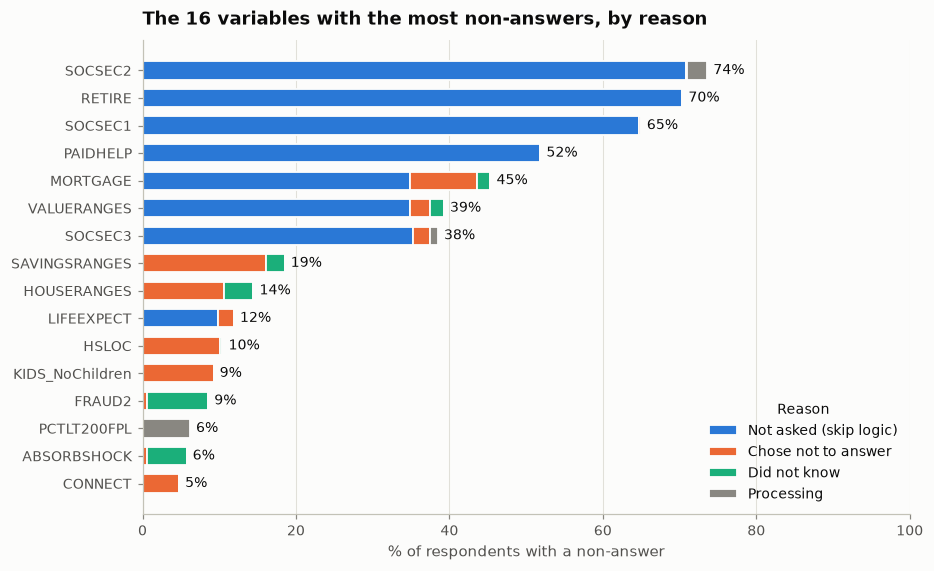

In [10]:
# Which variables are most affected, and why?
nature_order = ["Not asked (skip logic)", "Chose not to answer", "Did not know", "Processing"]
nature_colors = dict(zip(nature_order, [BLUE, ORANGE, AQUA, MUTED]))
by_var = (audit.pivot_table(index="variable", columns="nature", values="cells", aggfunc="sum", fill_value=0)
          .reindex(columns=nature_order, fill_value=0) / len(raw) * 100)
top = by_var.assign(total=by_var.sum(axis=1)).sort_values("total").tail(16)

fig, ax = plt.subplots(figsize=(9, 5.6))
left = np.zeros(len(top))
for nature in nature_order:
    ax.barh(top.index, top[nature], left=left, color=nature_colors[nature], label=nature,
            height=0.66, edgecolor=SURFACE, linewidth=1.2)
    left += top[nature].to_numpy()
for y, total in enumerate(top["total"]):
    ax.text(total + 0.8, y, f"{total:.0f}%", va="center", fontsize=9, color=INK)
ax.set_xlim(0, 100)
ax.set_xlabel("% of respondents with a non-answer")
ax.set_title("The 16 variables with the most non-answers, by reason")
ax.grid(axis="y", visible=False)
ax.legend(loc="lower right", title="Reason", title_fontsize=9)
fig.savefig(FIG_DIR / "01_special_codes_by_variable.png")
plt.show()

**Takeaways**

- **35,858 cells (2.6%) are non-answers stored as numbers**, spread over 134 of the 215 analysis columns. 81 columns have none.
- **Two-thirds of them (23,817) are skip logic**, concentrated in eight follow-up questions that were only asked of a subgroup, such as homeowners (`MORTGAGE`, `VALUERANGES`), retirees (`RETIRE`) or people aged 62+ (`SOCSEC1–3`). These are "not applicable", not refusals.
- **Genuine non-response is low for most questions** (under 2%), with a few exceptions: 19% did not state their savings and 14% did not state their housing cost.
- `PCTLT200FPL` (county poverty rate) is unknown for 6% of respondents. Section 3.8 shows these are exactly the oversample respondents.

---
## 3. Cleaning

Every cleaning decision is stated, justified and logged. The rules are applied in a fixed order and the log is printed at the end of the section.

**Principles**

1. **Never alter the raw file.** All changes are made on a copy; the raw data stays available for audit.
2. **Follow the codebook** for what counts as a non-answer; flag any place where we go beyond it.
3. **Prevent leakage.** Remove anything that mechanically reveals the outcome.
4. **Preserve information.** Where the act of not answering may itself be informative, keep a flag for it.
5. **Do not fit anything here.** Imputation and standardisation depend on the data they are fitted to, so they belong inside the modelling pipeline (fitted on training data only). Doing them here would leak test-set information into the models.

In [11]:
clean = raw.set_index("PUF_ID").astype("float64")
cleaning_log = []


def log_step(step, action, detail):
    cleaning_log.append({"Step": step, "Action": action, "Effect": detail})


print("Working copy:", clean.shape)

Working copy: (6394, 216)


#### 3.1 Capture informative non-response before removing it

For most variables fewer than 2% of respondents gave a non-answer, and treating those as missing loses nothing. A few variables are different: 15–19% of respondents declined to state their savings or housing cost. Declining may itself say something about a person, so for any variable where **at least 5%** of respondents refused or did not know, a companion flag `<VARIABLE>_NR` (1 = non-response) is created. Whether these flags carry signal is tested in Section 4.6.

Skip-logic codes (-2) are not counted here: a question that was never asked is not a refusal.

In [12]:
NR_THRESHOLD = 0.05
voluntary = audit[audit["nature"].isin(["Chose not to answer", "Did not know"])]
nr_share = voluntary[~voluntary["variable"].isin(CONDITIONAL)].groupby("variable")["cells"].sum() / len(raw)
nr_flag_vars = nr_share[nr_share >= NR_THRESHOLD].sort_values(ascending=False)

raw_by_id = raw.set_index("PUF_ID")
flags = pd.DataFrame({
    f"{col}_NR": raw_by_id[col].isin(voluntary.loc[voluntary["variable"] == col, "code"].tolist()).astype(float)
    for col in nr_flag_vars.index})
clean = pd.concat([clean, flags], axis=1)

display(pd.DataFrame({"label": codebook.loc[nr_flag_vars.index, "codebook_label"],
                      "share_refused_or_dont_know": nr_flag_vars.map("{:.1%}".format),
                      "flag_created": [f"{c}_NR" for c in nr_flag_vars.index]}))
log_step("3.1", "Created non-response flags for variables with >= 5% refused / don't know",
         f"{len(nr_flag_vars)} flag columns added")

,label,share_refused_or_dont_know,flag_created
variable,,,
SAVINGSRANGES,How much money do you have in savings today...?,18.5%,SAVINGSRANGES_NR
HOUSERANGES,About how much do you pay for your home each month?,14.5%,HOUSERANGES_NR
HSLOC,Where did you live at age 17?,10.4%,HSLOC_NR
KIDS_NoChildren,I have no children that I support financially,9.3%,KIDS_NoChildren_NR
FRAUD2,Victim of financial fraud or attempted financial fraud in past 5 years,8.6%,FRAUD2_NR
ABSORBSHOCK,"Confidence in ability to raise $2,000 in 30 days",5.7%,ABSORBSHOCK_NR


#### 3.2 Recode non-answers to missing

All special codes from Section 2.4 are converted to true missing values (`NaN`):

- every negative code, in every column **except `KHscore`**;
- 98 and 99 in the four dollar-range variables, 8 in the five "not sure" variables, 99 in `EMPLOY`;
- the eight employment tick-boxes (`EMPLOY1_1`–`EMPLOY1_8`) for the 116 respondents who ticked none of them (the codebook treats these as non-response, not as eight "No" answers).

For the other tick-box questions (products held, shocks, advice sources) the codebook treats "nothing ticked" as a valid "none of these", so those zeros are kept.

In [13]:
before_missing = int(clean.isna().sum().sum())

# (a) negative codes, with KHscore protected
neg_cols = [c for c in raw.columns if c not in ["PUF_ID", "finalwt"] + NEGATIVE_IS_VALID]
n_negative = int((clean[neg_cols] < 0).sum().sum())
clean[neg_cols] = clean[neg_cols].mask(clean[neg_cols] < 0)

# (b) positive non-response codes
n_positive = 0
for col, codes in NONRESPONSE_CODES.items():
    hit = clean[col].isin(codes)
    n_positive += int(hit.sum())
    clean[col] = clean[col].mask(hit)

# (c) employment tick-boxes for respondents who ticked nothing
employ_boxes = [f"EMPLOY1_{i}" for i in range(1, 9)]
no_employment_answer = clean["EMPLOY1_9"] == 1
clean.loc[no_employment_answer, employ_boxes] = np.nan
n_employ = int(no_employment_answer.sum()) * len(employ_boxes)

after_missing = int(clean.isna().sum().sum())
assert after_missing - before_missing == n_negative + n_positive + n_employ
assert after_missing - before_missing - n_employ == total_special, "Recode does not match the Section 2.4 audit"
assert (clean.drop(columns=NEGATIVE_IS_VALID) < 0).sum().sum() == 0, "A negative code survived"
assert clean["KHscore"].notna().all() and np.isclose(clean["KHscore"].min(), -2.053), "KHscore was damaged"

print(f"Negative codes recoded to missing:        {n_negative:>7,}")
print(f"Positive non-response codes recoded:      {n_positive:>7,}")
print(f"Employment tick-boxes set to missing:     {n_employ:>7,}")
print(f"Total cells now missing:                  {after_missing:>7,}")
print(f"KHscore untouched: {clean['KHscore'].notna().sum():,} valid values, range {clean['KHscore'].min()} to {clean['KHscore'].max()}")
log_step("3.2", "Recoded special codes to missing (KHscore protected)",
         f"{after_missing:,} cells set to NaN across {int((clean.isna().sum() > 0).sum())} columns")

Negative codes recoded to missing:         31,623
Positive non-response codes recoded:        4,235
Employment tick-boxes set to missing:         928
Total cells now missing:                   36,786
KHscore untouched: 6,394 valid values, range -2.053 to 1.267


#### 3.3 Remove target leakage

`PRODUSE_6` records "respondent did not select any item" in the same tick-box question that contains the outcome. Anyone flagged there cannot, by construction, have ticked the prepaid card box. It is not a predictor, it is the answer sheet.

In [14]:
leak = pd.crosstab(raw["PRODUSE_6"].map({0: "PRODUSE_6 = 0 (ticked at least one product)", 1: "PRODUSE_6 = 1 (ticked none)"}),
                   raw[TARGET].map({0: "Did not use prepaid", 1: "Used prepaid"}))
leak["Usage rate"] = (leak["Used prepaid"] / leak.sum(axis=1)).map("{:.1%}".format)
display(leak)
assert raw.loc[raw["PRODUSE_6"] == 1, TARGET].sum() == 0

clean = clean.drop(columns="PRODUSE_6")
log_step("3.3", "Dropped PRODUSE_6 (deterministic leakage of the outcome)", "1 column removed")

PRODUSE_3,Did not use prepaid,Used prepaid,Usage rate
PRODUSE_6,,,
PRODUSE_6 = 0 (ticked at least one product),741,560,43.0%
PRODUSE_6 = 1 (ticked none),5093,0,0.0%


The four **other** boxes in that question (`PRODUSE_1` payday loan, `PRODUSE_2` pawn or auto-title loan, `PRODUSE_4` non-bank international transfer, `PRODUSE_5` non-bank cheque cashing or money order) are not deterministic leakage, but they were answered in the same breath as the outcome and describe the same behaviour family. They are **kept in the cleaned file but marked "restricted"**: useful for describing users (Section 4.5), with a recommendation to keep them out of the predictive model unless the business case is specifically cross-selling to existing users of alternative financial services. That decision is formally taken at feature selection (Step 5).

#### 3.4 Remove administrative columns

- `finalwt` — survey weight. The brief says to ignore weights.
- `IMPUTATION_FLAG` — paradata recording that the CFPB imputed `HOUSERANGES`; not a respondent characteristic.
- `sample` — which sample the respondent was drawn from. It is a property of the survey design, not of the person, and would not exist for a real prospect. It is **kept for diagnostics only** and barred from the predictor set.

In [15]:
clean = clean.drop(columns=["finalwt", "IMPUTATION_FLAG"])
log_step("3.4", "Dropped survey weight and imputation paradata", "2 columns removed; `sample` kept for diagnostics only")

#### 3.5 Remove columns that duplicate other columns exactly

Two families of columns add no information because another column already contains it. Each claim is verified in code before anything is dropped.

- **Raw quiz answers** (`FINKNOWL1–3`, `KHKNOWL1–9`, `OBJNUMERACY1`). These store *which option* was picked (for example 1 = "More than \$102"). The companion `…correct` columns already store whether the answer was right, which is the meaningful part.
- **"Nothing ticked" indicators** (`PRODHAVE_9`, `SHOCKS_12`, `INTERCONNECTIONS_10`, `EMPLOY1_9`). Each is simply "all the other boxes are 0".

In [16]:
quiz_pairs = {**{f"FINKNOWL{i}": f"FK{i}correct" for i in range(1, 4)},
              **{f"KHKNOWL{i}": f"KH{i}correct" for i in range(1, 10)},
              "OBJNUMERACY1": "ON1correct"}
# The 'correct' flag must be a pure function of the raw answer: one flag value per answer option.
quiz_ok = all(raw.groupby(item)[flag].nunique().max() == 1 for item, flag in quiz_pairs.items())

none_ticked = {"PRODHAVE_9": [f"PRODHAVE_{i}" for i in range(1, 9)],
               "SHOCKS_12": [f"SHOCKS_{i}" for i in range(1, 12)],
               "INTERCONNECTIONS_10": [f"INTERCONNECTIONS_{i}" for i in range(1, 10)],
               "EMPLOY1_9": employ_boxes}
none_ok = all(((raw[boxes].sum(axis=1) == 0).astype(int) == raw[ind]).all() for ind, boxes in none_ticked.items())

lm_ok = (raw["LMscore"] == raw[["FK1correct", "FK2correct", "FK3correct"]].sum(axis=1)).all()

display(pd.DataFrame({"Claim": ["Each quiz 'correct' flag is fully determined by the raw answer",
                                "Each 'nothing ticked' indicator equals 'all boxes are 0'",
                                "LMscore equals the number of FK items answered correctly"],
                      "Verified": [quiz_ok, none_ok, bool(lm_ok)]}))
assert quiz_ok and none_ok and lm_ok

drop_duplicates = list(quiz_pairs) + list(none_ticked)
clean = clean.drop(columns=drop_duplicates)
log_step("3.5", "Dropped raw quiz answers and 'nothing ticked' indicators (exact duplicates of other columns)",
         f"{len(drop_duplicates)} columns removed")
print("Columns remaining:", clean.shape[1])

,Claim,Verified
0,Each quiz 'correct' flag is fully determined by the raw answer,True
1,Each 'nothing ticked' indicator equals 'all boxes are 0',True
2,LMscore equals the number of FK items answered correctly,True


Columns remaining: 202


#### 3.6 Respondent-level quality

Columns are now clean; this step checks the rows. A respondent who skipped a large part of the questionnaire contributes mostly imputed values and little real information. The check uses only questions that were asked of everyone.

In [17]:
asked_of_all = [c for c in clean.columns if c not in CONDITIONAL and not c.endswith("_NR")]
row_missing = clean[asked_of_all].isna().mean(axis=1)

bands = pd.cut(row_missing, [-0.001, 0, 0.05, 0.10, 0.20, 1.0],
               labels=["No items missing", "Up to 5% missing", "5–10% missing", "10–20% missing", "More than 20% missing"])
row_quality = pd.DataFrame({"respondents": bands.value_counts().sort_index()})
row_quality["share"] = (row_quality["respondents"] / len(clean)).map("{:.1%}".format)
row_quality["prepaid usage rate"] = clean.groupby(bands, observed=False)[TARGET].mean().map("{:.1%}".format)
display(row_quality)

MAX_ROW_MISSING = 0.20
drop_rows = row_missing > MAX_ROW_MISSING
print(f"Respondents above the {MAX_ROW_MISSING:.0%} threshold: {int(drop_rows.sum())} "
      f"({int(clean.loc[drop_rows, TARGET].sum())} of them prepaid users)")

,respondents,share,prepaid usage rate
No items missing,2793,43.7%,6.4%
Up to 5% missing,3467,54.2%,10.6%
5–10% missing,84,1.3%,14.3%
10–20% missing,23,0.4%,8.7%
More than 20% missing,27,0.4%,0.0%


Respondents above the 20% threshold: 27 (0 of them prepaid users)


In [18]:
clean = clean.loc[~drop_rows].copy()
log_step("3.6", f"Removed respondents missing more than {MAX_ROW_MISSING:.0%} of the questions asked of everyone",
         f"{int(drop_rows.sum())} rows removed; {len(clean):,} respondents remain")
print(f"Respondents remaining: {len(clean):,} | prepaid users remaining: {int(clean[TARGET].sum())}")

Respondents remaining: 6,367 | prepaid users remaining: 560


**Decision.** The 27 respondents (0.4%) who skipped more than 20% of the questionnaire are removed. None of them is recorded as a prepaid user, but that zero is not trustworthy: the outcome is a tick-box, so someone who skipped most of the survey shows "0" whether or not they use a prepaid card. Removing them loses no known users.

**Everyone else is kept, including respondents with some missing answers.** Dropping every incomplete row would discard 56% of the data and would bias it: respondents with a few missing answers use prepaid cards more (10.6%) than respondents with none (6.4%). Remaining gaps are filled by imputation inside the modelling pipeline.

#### 3.7 Two summary features

Two question batteries are easier to read, and cheaper against the 20-predictor limit, as a single count:

- `HARDSHIP_COUNT` — how many of the six material hardships (food, housing, medical care, medication, utilities) the household experienced "sometimes" or "often" (0–6).
- `SHOCKS_COUNT` — how many of the eleven financial shocks the household experienced in the past year (0–11).

The original items are kept alongside; feature selection (Step 5) decides which form to use.

In [19]:
hardship_items = [f"MATHARDSHIP_{i}" for i in range(1, 7)]
shock_items = [f"SHOCKS_{i}" for i in range(1, 12)]

clean["HARDSHIP_COUNT"] = (clean[hardship_items] >= 2).sum(axis=1).where(clean[hardship_items].notna().any(axis=1))
clean["SHOCKS_COUNT"] = clean[shock_items].sum(axis=1)

for col in ["HARDSHIP_COUNT", "SHOCKS_COUNT"]:
    counts = clean[col].value_counts().sort_index()
    counts.index = counts.index.astype(int)
    display(counts.rename("respondents").rename_axis(col).to_frame().T)
print("HARDSHIP_COUNT missing (all six items unanswered):", int(clean["HARDSHIP_COUNT"].isna().sum()))
log_step("3.7", "Added HARDSHIP_COUNT and SHOCKS_COUNT summary features", "2 columns added")

HARDSHIP_COUNT,0,1,2,3,4,5,6
respondents,4535,561,416,271,221,136,224


SHOCKS_COUNT,0,1,2,3,4,5,6,9,10,11
respondents,3153,2028,779,280,85,30,7,1,1,3


HARDSHIP_COUNT missing (all six items unanswered): 3


#### 3.8 Variable roles and measurement types

Every remaining column is assigned a **role** (may it be used as a predictor?) and a **measurement type** (how must a model treat it?). The measurement type drives the encoding in Step 6: unordered categories need one-hot encoding, ordered scales and scores can be used as numbers and standardised.

| Role | Meaning |
|---|---|
| Target | The outcome, `PRODUSE_3` |
| Candidate predictor | Eligible for the 20-variable shortlist |
| Restricted | Same-question items; excluded by default (Section 3.3) |
| Diagnostic only | `sample`; used for checks, never as a predictor |
| Excluded | Not eligible, with the reason recorded |

In [20]:
CONTINUOUS = ["FWBscore", "FSscore", "KHscore", "CONNECT", "LIFEEXPECT", "SOCSEC2", "SOCSEC3"]
NOMINAL = ["sample", "HOUSING", "LIVINGARRANGEMENT", "COVERCOSTS", "MANAGE2", "EMPLOY", "Military_Status",
           "PPETHM", "PPMARIT", "PPREG4", "PPREG9", "AUTOMATED_1", "AUTOMATED_2"]
SAME_QUESTION = ["PRODUSE_1", "PRODUSE_2", "PRODUSE_4", "PRODUSE_5"]
EXCLUDED = {
    **{c: "Asked of a subgroup only (skip logic); the parent variable carries the information" for c in CONDITIONAL},
    "PPREG9": "Finer cut of PPREG4 (census region); nine sparse levels add little",
    "generation": "Derived from age; agecat is the finer version",
    "MILITARY": "Collapsed version of Military_Status",
    "PCTLT200FPL": "Missing for exactly the race/ethnicity and poverty oversample, so it encodes the survey design",
    **{c: "Multi-select version of EMPLOY (primary employment status)" for c in employ_boxes},
}
DERIVED_LABELS = {"HARDSHIP_COUNT": "Number of material hardships experienced sometimes or often (0-6)",
                  "SHOCKS_COUNT": "Number of financial shocks in the past year (0-11)"}


# PCTLT200FPL (county poverty rate) is unknown for precisely the oversample respondents: a design artefact, not a trait.
assert (clean["PCTLT200FPL"].isna() == (clean["sample"] == 3)).all()


def measurement_type(col):
    if col in CONTINUOUS:
        return "Continuous score"
    if col in NOMINAL:
        return "Nominal (unordered categories)"
    return "Binary" if clean[col].nunique() <= 2 else "Ordinal (ordered scale or count)"


def variable_role(col):
    if col == TARGET:
        return "Target", ""
    if col == "sample":
        return "Diagnostic only", "Survey-design variable, not a respondent characteristic"
    if col in SAME_QUESTION:
        return "Restricted", "Answered in the same tick-box question as the outcome"
    if col in EXCLUDED:
        return "Excluded", EXCLUDED[col]
    return "Candidate predictor", ""


def variable_label(col):
    if col.endswith("_NR"):
        return "Non-response flag: " + codebook.loc[col[:-3], "codebook_label"]
    return DERIVED_LABELS.get(col) or codebook.loc[col, "codebook_label"]


roles = pd.DataFrame(index=pd.Index(clean.columns, name="variable"))
roles["label"] = [variable_label(c) for c in roles.index]
roles["group"] = [variable_group(c[:-3] if c.endswith("_NR") else c) for c in roles.index]
roles.loc[list(DERIVED_LABELS), "group"] = "Financial strain, hardship and shocks"
roles["measurement_type"] = [measurement_type(c) for c in roles.index]
roles[["role", "exclusion_reason"]] = [variable_role(c) for c in roles.index]
roles["n_valid"] = clean.notna().sum()
roles["pct_missing"] = (clean.isna().mean() * 100).round(2)
roles["n_levels"] = clean.nunique()

CANDIDATES = roles.index[roles["role"] == "Candidate predictor"].tolist()
display(roles["role"].value_counts().rename("columns").to_frame())
display(pd.crosstab(roles.loc[CANDIDATES, "group"], roles.loc[CANDIDATES, "measurement_type"], margins=True, margins_name="Total"))

,columns
role,
Candidate predictor,178
Excluded,20
Restricted,4
Diagnostic only,1
Target,1


measurement_type,Binary,Continuous score,Nominal (unordered categories),Ordinal (ordered scale or count),Total
group,,,,,
"Attitudes, traits and health",2,1,0,11,14
Demographics and geography,8,0,3,11,22
"Employment, retirement and military",0,0,2,0,2
Financial knowledge and numeracy (tested),14,1,0,1,16
Financial products held,8,0,0,0,8
Financial skill and self-assessed ability,0,1,0,15,16
"Financial strain, hardship and shocks",21,0,0,13,34
Financial well-being,0,1,0,13,14
"Housing, savings and household resources",7,0,2,4,13


#### 3.9 Final checks, cleaning log and save

In [21]:
cand_missing = roles.loc[CANDIDATES, "pct_missing"]
missing_profile = pd.cut(cand_missing, [-0.01, 0, 1, 5, 100],
                         labels=["0% (complete)", "Up to 1%", "1–5%", "More than 5%"]).value_counts().sort_index()
display(missing_profile.rename("candidate predictors").to_frame())
display(roles.loc[CANDIDATES].sort_values("pct_missing", ascending=False)
        .head(8)[["label", "pct_missing"]].rename(columns={"pct_missing": "% missing"}))

final_checks = {
    "Outcome has no missing values and is 0/1": bool(clean[TARGET].notna().all() and set(clean[TARGET].unique()) == {0.0, 1.0}),
    "Respondent ID is unique": clean.index.is_unique,
    "No special codes remain (no negatives outside KHscore)": bool((clean.drop(columns="KHscore") < 0).sum().sum() == 0),
    "No 98/99 remain in the dollar-range variables": bool(not clean[["HOUSERANGES", "VALUERANGES", "MORTGAGE", "SAVINGSRANGES"]].isin([98, 99]).any().any()),
    "Leakage column PRODUSE_6 is gone": "PRODUSE_6" not in clean.columns,
    "Survey weight is gone": "finalwt" not in clean.columns,
    "No candidate predictor is constant": bool((roles.loc[CANDIDATES, "n_levels"] > 1).all()),
    "Every column has a role and a measurement type": bool(roles[["role", "measurement_type"]].notna().all().all()),
}
display(pd.DataFrame({"Check": list(final_checks), "Result": ["PASS" if ok else "FAIL" for ok in final_checks.values()]}))
assert all(final_checks.values())

clean.to_csv(CLEAN_PATH)
roles.to_csv(ROLES_PATH)
log_step("3.9", "Saved cleaned data and variable-roles table", f"{CLEAN_PATH.as_posix()} and {ROLES_PATH.as_posix()}")

with pd.option_context("display.max_colwidth", 120):
    display(pd.DataFrame(cleaning_log).set_index("Step"))
print(f"Raw:     {raw.shape[0]:,} respondents x {raw.shape[1]} columns")
print(f"Cleaned: {clean.shape[0]:,} respondents x {clean.shape[1]} columns "
      f"({len(CANDIDATES)} candidate predictors, 1 target, {clean.shape[1] - len(CANDIDATES) - 1} restricted / diagnostic / excluded)")
print(f"Prepaid usage rate after cleaning: {clean[TARGET].mean():.2%} (raw: {BASE_RATE:.2%})")

,candidate predictors
pct_missing,
0% (complete),76
Up to 1%,83
1–5%,13
More than 5%,6


,label,% missing
variable,,
SAVINGSRANGES,How much money do you have in savings today...?,18.22
HOUSERANGES,About how much do you pay for your home each month?,14.34
HSLOC,Where did you live at age 17?,10.18
KIDS_NoChildren,I have no children that I support financially,8.92
FRAUD2,Victim of financial fraud or attempted financial fraud in past 5 years,8.23
ABSORBSHOCK,"Confidence in ability to raise $2,000 in 30 days",5.37
CONNECT,Psychological connectedness,4.37
COLLECT,Contacted by debt collector in past 12 months,4.18


,Check,Result
0,Outcome has no missing values and is 0/1,PASS
1,Respondent ID is unique,PASS
2,No special codes remain (no negatives outside KHscore),PASS
3,No 98/99 remain in the dollar-range variables,PASS
4,Leakage column PRODUSE_6 is gone,PASS
5,Survey weight is gone,PASS
6,No candidate predictor is constant,PASS
7,Every column has a role and a measurement type,PASS


,Action,Effect
Step,,
3.1,Created non-response flags for variables with >= 5% refused / don't know,6 flag columns added
3.2,Recoded special codes to missing (KHscore protected),"36,786 cells set to NaN across 142 columns"
3.3,Dropped PRODUSE_6 (deterministic leakage of the outcome),1 column removed
3.4,Dropped survey weight and imputation paradata,2 columns removed; `sample` kept for diagnostics only
3.5,Dropped raw quiz answers and 'nothing ticked' indicators (exact duplicates of other columns),17 columns removed
3.6,Removed respondents missing more than 20% of the questions asked of everyone,"27 rows removed; 6,367 respondents remain"
3.7,Added HARDSHIP_COUNT and SHOCKS_COUNT summary features,2 columns added
3.9,Saved cleaned data and variable-roles table,data/cfpb_clean.csv and data/variable_roles.csv


Raw:     6,394 respondents x 217 columns
Cleaned: 6,367 respondents x 204 columns (178 candidate predictors, 1 target, 25 restricted / diagnostic / excluded)
Prepaid usage rate after cleaning: 8.80% (raw: 8.76%)


**Result of cleaning**

- **Cleaned dataset:** 6,367 respondents, 204 columns, saved to `data/cfpb_clean.csv`. The outcome is intact (560 users, 8.80%).
- **178 candidate predictors**, each with a recorded group, measurement type and missing-data rate in `data/variable_roles.csv`.
- **Missing data is light:** 76 candidates are complete, 83 are missing in at most 1% of rows, 13 in 1–5%, and only 6 in more than 5%.
- **Deliberately not done here:** imputation, one-hot encoding and standardisation. These are fitted on the training data only, inside the modelling pipeline (Step 6), so that no information from the test set leaks into the models.

---
## 4. Exploration

**Aim.** Establish who uses prepaid cards and which variables carry signal, as the evidence base for choosing predictors in Step 5.

**How to read the charts.** Each bar is the share of that group who used a prepaid card. The thin line through the end of each bar is the 95% confidence interval: short lines mean a precise estimate, long lines mean a small group. The dashed vertical line is the overall rate. All rates are unweighted, as the brief requires; Section 4.8 checks that the patterns are not an artefact of the oversamples.

**Caution.** These are associations between one variable and the outcome at a time. They show who uses prepaid cards, not why, and many of the variables overlap (Section 4.7).

In [22]:
BASE = clean[TARGET].mean()

VALUE_LABELS = {
    "PPINCIMP": {1: "Less than $20,000", 2: "$20,000–29,999", 3: "$30,000–39,999", 4: "$40,000–49,999", 5: "$50,000–59,999",
                 6: "$60,000–74,999", 7: "$75,000–99,999", 8: "$100,000–149,999", 9: "$150,000 or more"},
    "agecat": {1: "18–24", 2: "25–34", 3: "35–44", 4: "45–54", 5: "55–61", 6: "62–69", 7: "70–74", 8: "75+"},
    "PPEDUC": {1: "Less than high school", 2: "High school degree / GED", 3: "Some college / Associate",
               4: "Bachelor's degree", 5: "Graduate / professional degree"},
    "PPETHM": {1: "White, non-Hispanic", 2: "Black, non-Hispanic", 3: "Other, non-Hispanic", 4: "Hispanic"},
    "PPGENDER": {1: "Male", 2: "Female"},
    "PPMARIT": {1: "Married", 2: "Widowed", 3: "Divorced / separated", 4: "Never married", 5: "Living with partner"},
    "PPREG4": {1: "Northeast", 2: "Midwest", 3: "South", 4: "West"},
    "PPMSACAT": {0: "Non-metro area", 1: "Metro area"},
    "fpl": {1: "Below the poverty line", 2: "100–199% of the poverty line", 3: "200%+ of the poverty line"},
    "HOUSING": {1: "Owns home", 2: "Rents", 3: "Neither owns nor rents"},
    "EMPLOY": {1: "Self-employed", 2: "Works full-time", 3: "Works part-time", 4: "Homemaker", 5: "Full-time student",
               6: "Sick, disabled or unable to work", 7: "Unemployed or laid off", 8: "Retired"},
    "ENDSMEET": {1: "Not at all difficult", 2: "Somewhat difficult", 3: "Very difficult"},
    "ABSORBSHOCK": {1: "Certain could not", 2: "Probably could not", 3: "Probably could", 4: "Certain could"},
    "SAVINGSRANGES": {1: "$0", 2: "$1–99", 3: "$100–999", 4: "$1,000–4,999", 5: "$5,000–19,999", 6: "$20,000–74,999", 7: "$75,000 or more"},
    "HARDSHIP_COUNT": {0: "None", 1: "1 hardship", 2: "2 hardships", 3: "3 hardships", 4: "4 hardships", 5: "5 hardships", 6: "All 6 hardships"},
    "LMscore": {0: "0 of 3 correct", 1: "1 of 3 correct", 2: "2 of 3 correct", 3: "3 of 3 correct"},
    "VOLATILITY": {1: "Roughly the same each month", 2: "Some unusually high or low months", 3: "Often varies a lot"},
}


def rate_table(data, col, labels=None):
    """Prepaid usage rate, group size and 95% Wilson interval for each level of `col`."""
    t = data.groupby(col, observed=True)[TARGET].agg(n="size", users="sum")
    t["rate"] = t["users"] / t["n"]
    t["lo"], t["hi"] = wilson_interval(t["users"], t["n"])
    labels = labels if labels is not None else VALUE_LABELS.get(col)
    if labels:
        t.index = [labels.get(k, k) for k in t.index]
    return t


def plot_rates(ax, t, title, xmax, show_xlabel=True):
    """Horizontal bars of usage rate with confidence intervals, group sizes and the overall-rate reference line."""
    y = np.arange(len(t))[::-1]
    ax.barh(y, t["rate"] * 100, height=0.62, color=BLUE, zorder=3)
    ax.errorbar(t["rate"] * 100, y, xerr=[(t["rate"] - t["lo"]) * 100, (t["hi"] - t["rate"]) * 100],
                fmt="none", ecolor=INK2, elinewidth=1, zorder=4)
    ax.axvline(BASE * 100, color=MUTED, linewidth=1, linestyle=(0, (4, 3)), zorder=2)
    for yi, rate, hi_ in zip(y, t["rate"], t["hi"]):
        ax.text(hi_ * 100 + xmax * 0.012, yi, f"{rate:.1%}", va="center", fontsize=9, color=INK)
    ax.set_yticks(y, [f"{label}  (n={n:,})" for label, n in zip(t.index, t["n"])])
    ax.set_xlim(0, xmax)
    ax.grid(axis="y", visible=False)
    ax.tick_params(axis="y", length=0)
    ax.xaxis.set_major_formatter(mpl.ticker.PercentFormatter(decimals=0))
    ax.set_title(title)
    if show_xlabel:
        ax.set_xlabel("% who used a prepaid card")


def rate_panel(specs, ncols, figsize, filename, suptitle=None, data=None):
    """Grid of rate charts sharing one x-scale so panels can be compared directly."""
    data = clean if data is None else data
    tables = [rate_table(data, col) for col, _ in specs]
    xmax = max(t["hi"].max() for t in tables) * 100 * 1.16
    nrows = int(np.ceil(len(specs) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=figsize)
    axes = np.atleast_1d(axes).ravel()
    for ax, (_, title), t in zip(axes, specs, tables):
        plot_rates(ax, t, title, xmax)
    for ax in axes[len(specs):]:
        ax.set_visible(False)
    axes[0].text(BASE * 100, 1.0, f" Overall {BASE:.1%}", transform=axes[0].get_xaxis_transform(),
                 fontsize=8.5, color=MUTED, va="bottom", ha="left")
    if suptitle:
        fig.suptitle(suptitle, x=0.01, ha="left", fontsize=13, fontweight="bold")
    fig.tight_layout()
    fig.savefig(FIG_DIR / filename)
    plt.show()
    return dict(zip([c for c, _ in specs], tables))


print(f"Overall prepaid usage rate in the cleaned data: {BASE:.2%} ({int(clean[TARGET].sum())} of {len(clean):,})")

Overall prepaid usage rate in the cleaned data: 8.80% (560 of 6,367)


#### 4.1 Demographics

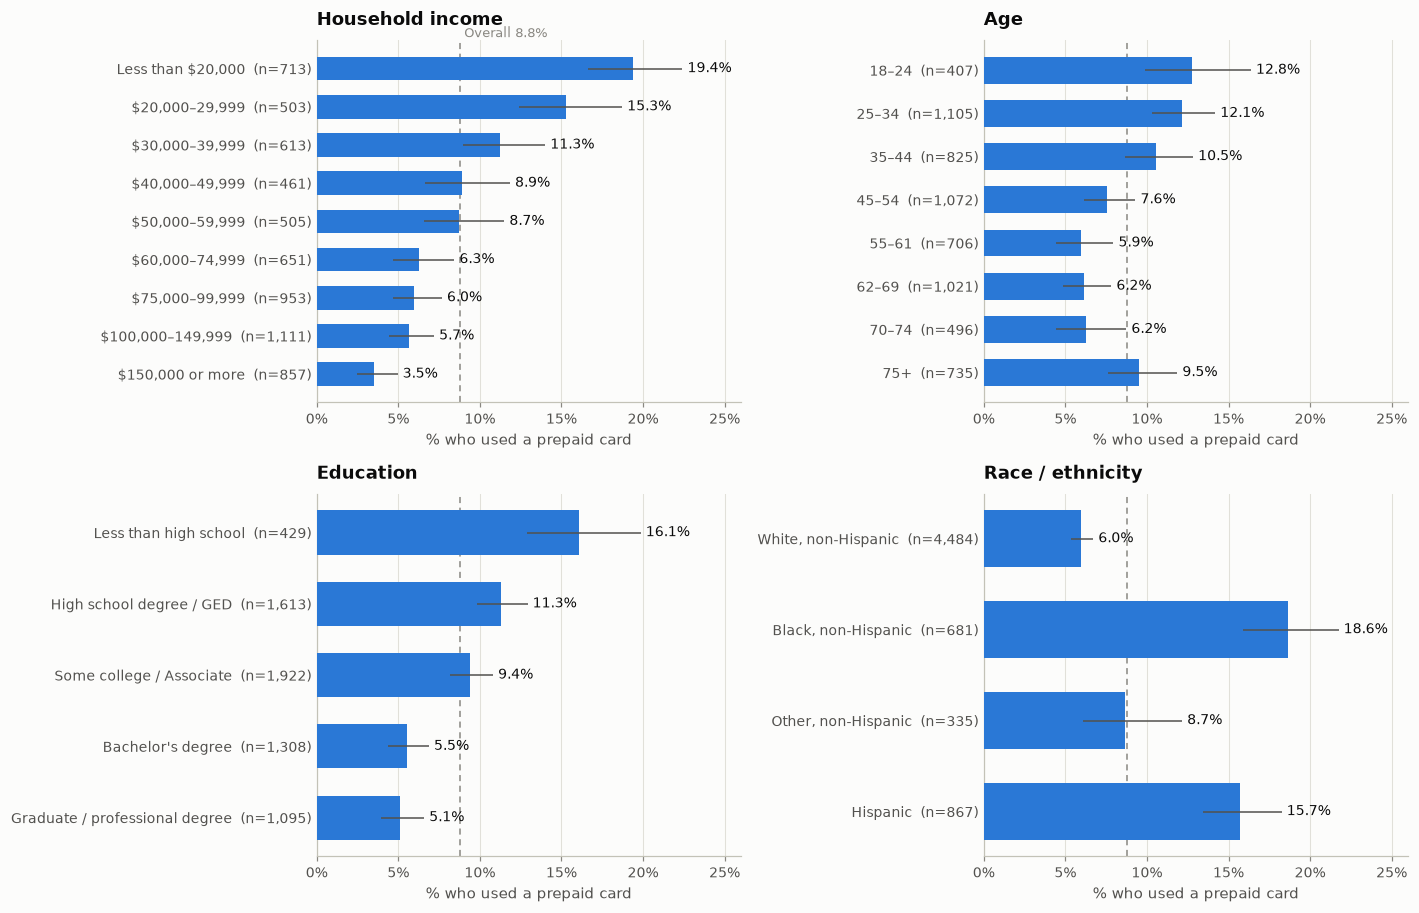

In [23]:
demo = rate_panel([("PPINCIMP", "Household income"), ("agecat", "Age"),
                   ("PPEDUC", "Education"), ("PPETHM", "Race / ethnicity")],
                  ncols=2, figsize=(13, 8.4), filename="02_demographics_core.png")

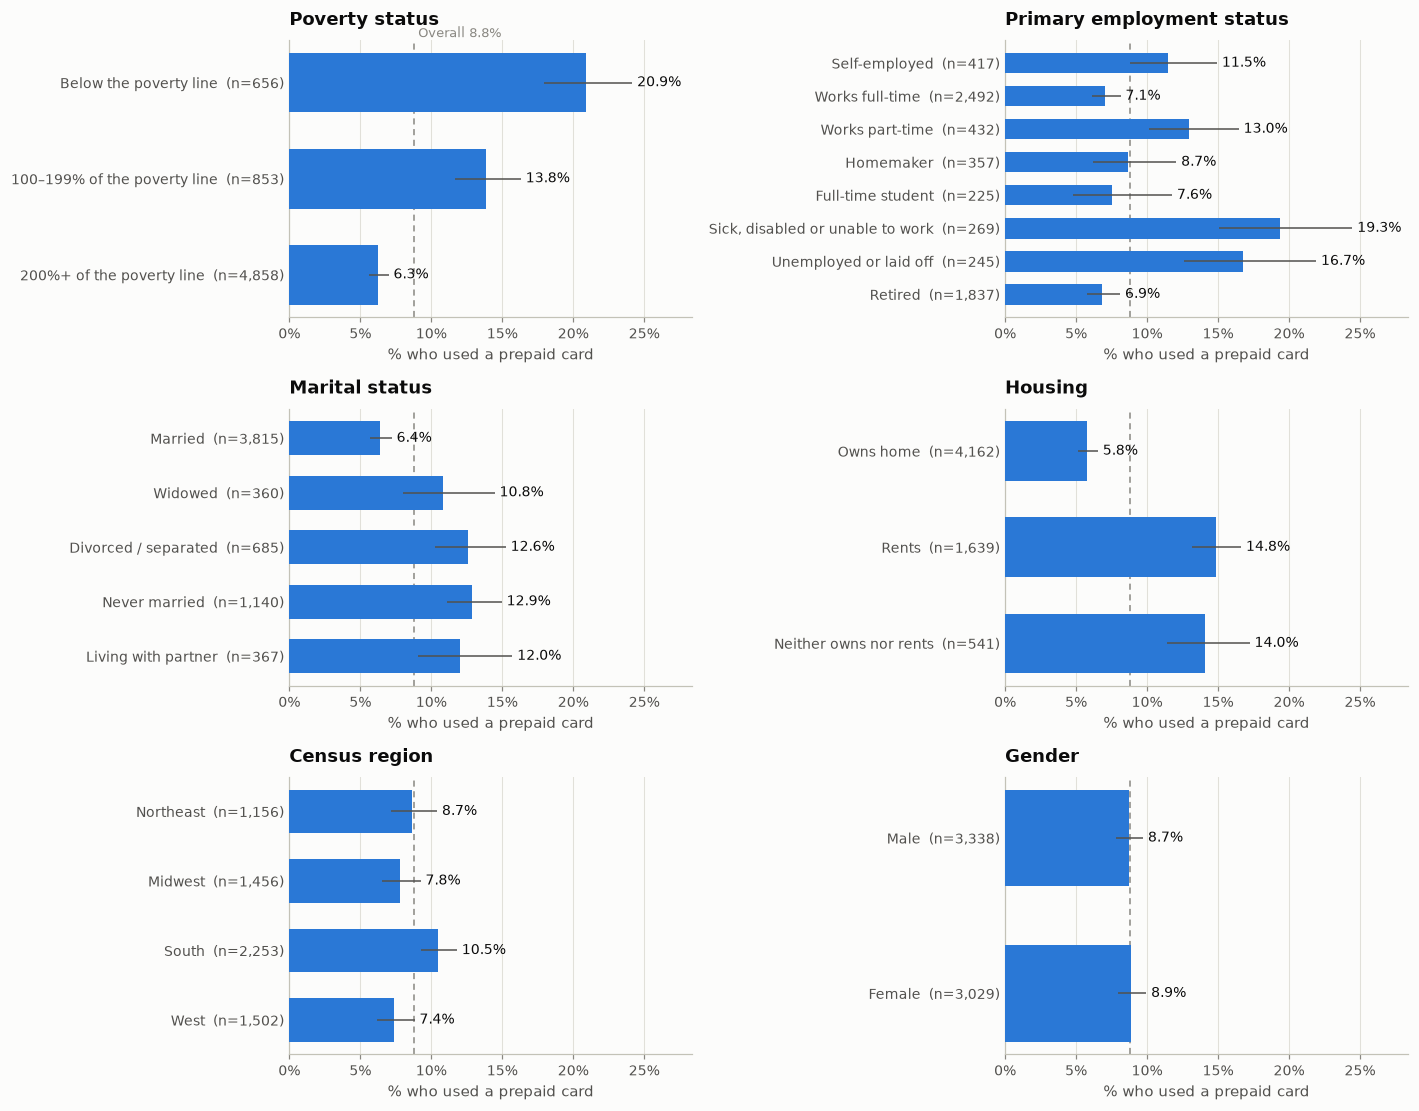

In [24]:
demo2 = rate_panel([("fpl", "Poverty status"), ("EMPLOY", "Primary employment status"),
                    ("PPMARIT", "Marital status"), ("HOUSING", "Housing"),
                    ("PPREG4", "Census region"), ("PPGENDER", "Gender")],
                   ncols=2, figsize=(13, 10.2), filename="03_demographics_other.png")

**Takeaways**

- **Income is the clearest demographic gradient.** Use falls steadily from 19.4% in households under \$20,000 to 3.5% at \$150,000 or more. People below the poverty line use prepaid cards at 20.9%, against 6.3% for those at twice the poverty line or above.
- **Age:** use is highest under 35 (12–13%) and lowest between 55 and 74 (about 6%), with a small rise at 75+ (9.5%).
- **Education:** 16.1% without a high-school diploma, falling to 5.1% with a graduate degree.
- **Race / ethnicity:** 18.6% of Black and 15.7% of Hispanic respondents, against 6.0% of White respondents.
- **Work and housing:** highest among people unable to work through sickness or disability (19.3%), the unemployed (16.7%) and part-time workers (13.0%); renters (14.8%) use prepaid cards far more than homeowners (5.8%).
- **No difference by gender** (8.7% vs 8.9%) and only a small one by region (South 10.5%, West 7.4%).

**Flag for Step 5.** Race/ethnicity carries signal, but using it to select who receives a credit-related marketing offer raises fair-lending concerns. It is clearly relevant to the CFPB's at-risk analysis. Whether it enters the card company's targeting model is a decision for the team, not a statistical one.

#### 4.2 Banking relationship and products held

For each product, the chart compares the prepaid usage rate of people who hold the product with those who do not. A wide gap means the product separates users from non-users well.

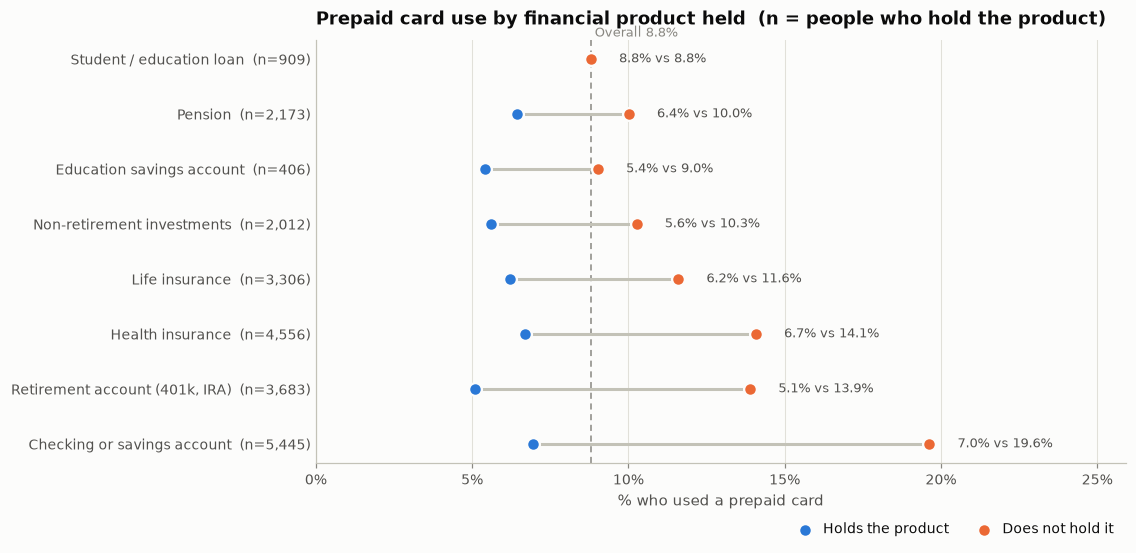

,label,rate_yes,rate_no,ratio_yes_vs_no
0,Student / education loan,8.8%,8.8%,1.00x
1,Pension,6.4%,10.0%,0.64x
2,Education savings account,5.4%,9.0%,0.60x
3,Non-retirement investments,5.6%,10.3%,0.55x
4,Life insurance,6.2%,11.6%,0.53x
5,Health insurance,6.7%,14.1%,0.48x
6,"Retirement account (401k, IRA)",5.1%,13.9%,0.37x
7,Checking or savings account,7.0%,19.6%,0.35x


In [25]:
def binary_contrast(data, cols, names=None):
    """Usage rate when a 0/1 indicator is 1 versus 0, with group sizes and the ratio between them."""
    out = []
    for col in cols:
        g = data.groupby(col)[TARGET].agg(["size", "mean"])
        out.append({"variable": col, "label": (names or {}).get(col, codebook.loc[col, "codebook_label"] if col in codebook.index else col),
                    "rate_yes": g.loc[1, "mean"], "n_yes": int(g.loc[1, "size"]),
                    "rate_no": g.loc[0, "mean"], "n_no": int(g.loc[0, "size"])})
    t = pd.DataFrame(out).set_index("variable")
    t["ratio_yes_vs_no"] = t["rate_yes"] / t["rate_no"]
    return t


def plot_contrast(t, title, filename, yes_label, no_label, figsize=(9.5, 5)):
    t = t.sort_values("ratio_yes_vs_no")
    y = np.arange(len(t))
    fig, ax = plt.subplots(figsize=figsize)
    ax.hlines(y, t["rate_no"] * 100, t["rate_yes"] * 100, color=AXIS, linewidth=2, zorder=2)
    ax.scatter(t["rate_yes"] * 100, y, s=70, color=BLUE, zorder=3, label=yes_label, edgecolor=SURFACE, linewidth=1.5)
    ax.scatter(t["rate_no"] * 100, y, s=70, color=ORANGE, zorder=3, label=no_label, edgecolor=SURFACE, linewidth=1.5)
    ax.axvline(BASE * 100, color=MUTED, linewidth=1, linestyle=(0, (4, 3)), zorder=1)
    ax.text(BASE * 100, 1.0, f" Overall {BASE:.1%}", transform=ax.get_xaxis_transform(), fontsize=8.5, color=MUTED, va="bottom")
    for yi, (_, r) in zip(y, t.iterrows()):
        right = max(r["rate_yes"], r["rate_no"]) * 100
        ax.text(right + 0.9, yi, f"{r['rate_yes']:.1%} vs {r['rate_no']:.1%}", va="center", fontsize=8.5, color=INK2)
    ax.set_yticks(y, [f"{lab}  (n={n:,})" for lab, n in zip(t["label"], t["n_yes"])])
    ax.set_xlim(0, max(t["rate_yes"].max(), t["rate_no"].max()) * 100 * 1.32)
    ax.xaxis.set_major_formatter(mpl.ticker.PercentFormatter(decimals=0))
    ax.set_xlabel("% who used a prepaid card")
    ax.grid(axis="y", visible=False)
    ax.tick_params(axis="y", length=0)
    ax.set_title(title)
    ax.legend(loc="upper right", bbox_to_anchor=(1.0, -0.11), ncol=2, columnspacing=1.6, handletextpad=0.3)
    fig.savefig(FIG_DIR / filename)
    plt.show()
    return t


product_names = {"PRODHAVE_1": "Checking or savings account", "PRODHAVE_2": "Life insurance", "PRODHAVE_3": "Health insurance",
                 "PRODHAVE_4": "Retirement account (401k, IRA)", "PRODHAVE_5": "Pension", "PRODHAVE_6": "Non-retirement investments",
                 "PRODHAVE_7": "Education savings account", "PRODHAVE_8": "Student / education loan"}
products = plot_contrast(binary_contrast(clean, list(product_names), product_names),
                         "Prepaid card use by financial product held  (n = people who hold the product)",
                         "04_products_held.png", "Holds the product", "Does not hold it")
fmt(products[["label", "rate_yes", "rate_no", "ratio_yes_vs_no"]].iloc[::-1],
    {"rate_yes": "{:.1%}", "rate_no": "{:.1%}", "ratio_yes_vs_no": "{:.2f}x"}, hide_index=True)

**Takeaways**

- **Bank-account status is the sharpest single divide among products:** 19.6% of people who report no checking or savings account use a prepaid card, against 7.0% of those with one (2.8 times higher).
- **Holding long-term financial products goes with lower use:** retirement account 5.1% vs 13.9%, health insurance 6.7% vs 14.1%, life insurance 6.2% vs 11.6%.
- **Student loans make no difference** (8.8% either way).
- **Prepaid cards are not only a substitute for a bank account.** 68% of prepaid users do have a checking or savings account.

**Caveat.** "No account" means the respondent did not tick the box (14.5% of the sample). That is higher than typical estimates of the unbanked population, so some of these people may simply have skipped the item. It is described here as "no account reported".

#### 4.3 Financial fragility

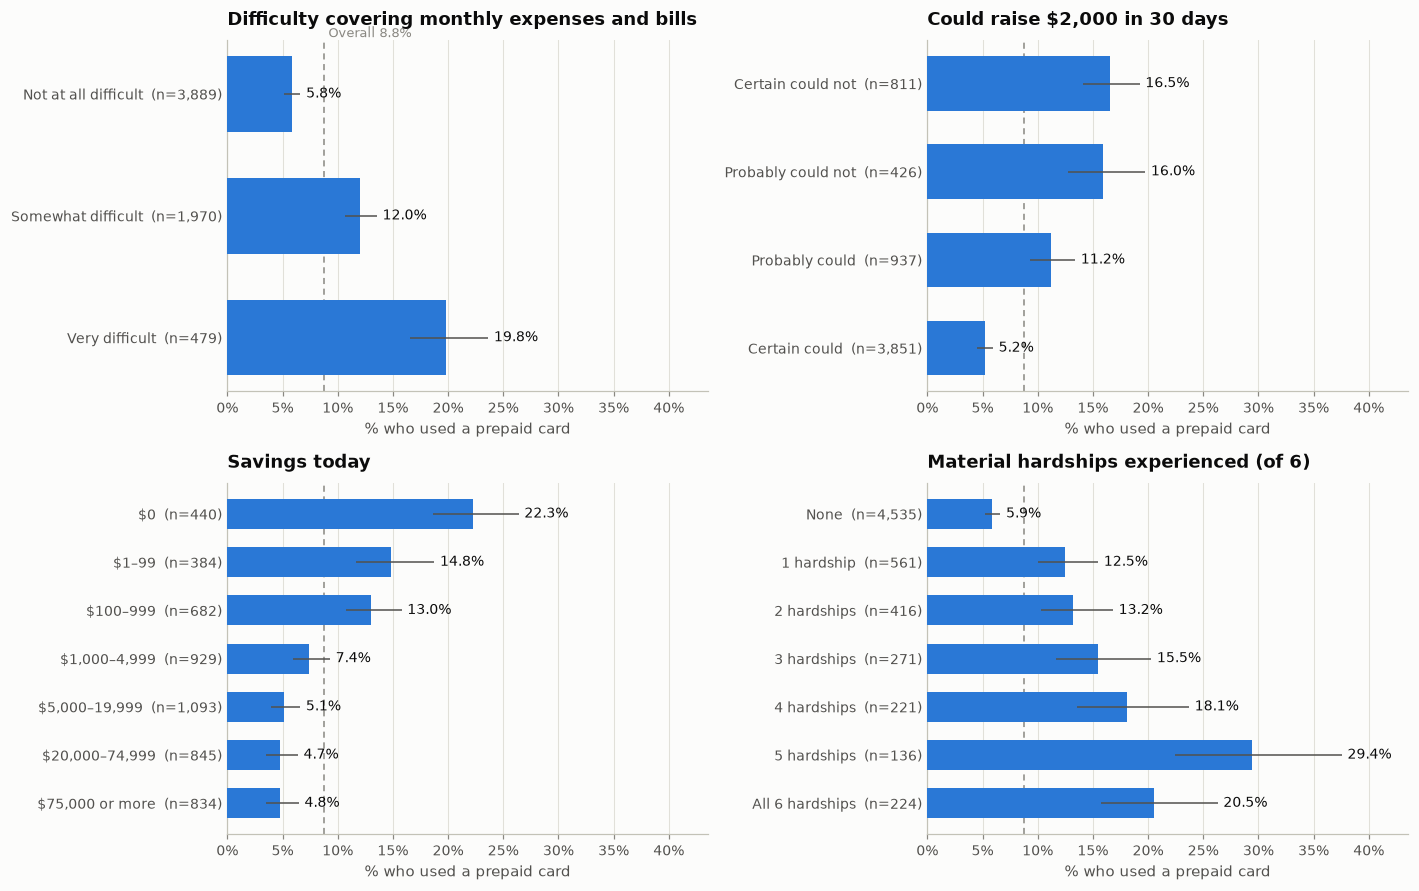

In [26]:
fragility = rate_panel([("ENDSMEET", "Difficulty covering monthly expenses and bills"),
                        ("ABSORBSHOCK", "Could raise $2,000 in 30 days"),
                        ("SAVINGSRANGES", "Savings today"),
                        ("HARDSHIP_COUNT", "Material hardships experienced (of 6)")],
                       ncols=2, figsize=(13, 8.2), filename="05_financial_fragility.png")

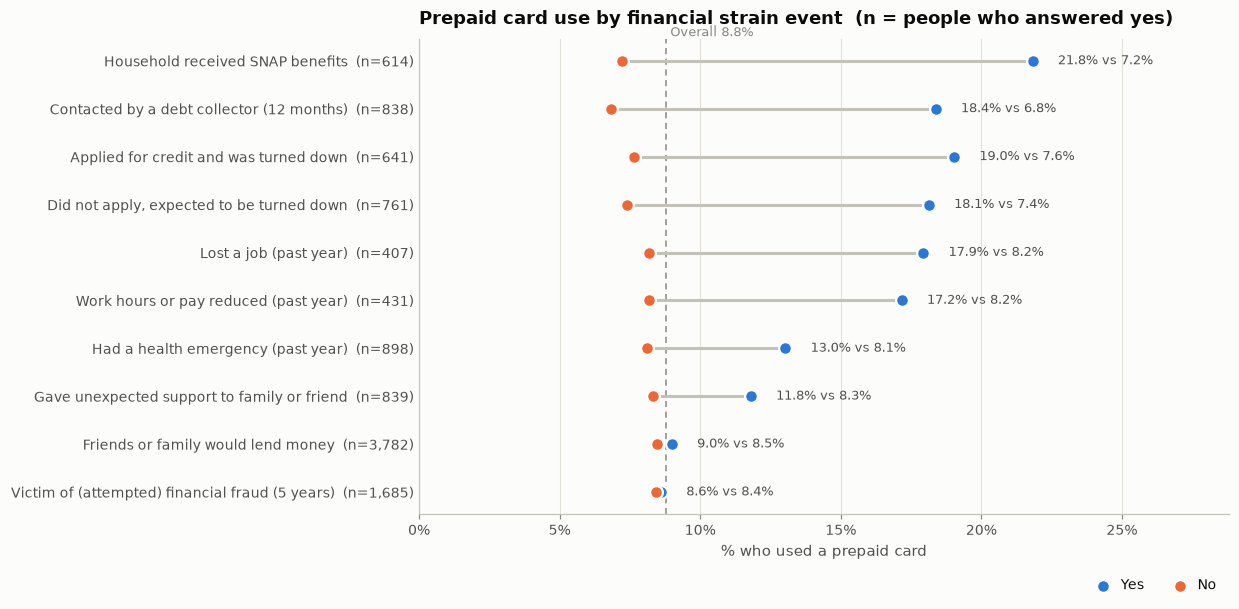

In [27]:
strain_names = {"SNAP": "Household received SNAP benefits", "COLLECT": "Contacted by a debt collector (12 months)",
                "REJECTED_1": "Applied for credit and was turned down", "REJECTED_2": "Did not apply, expected to be turned down",
                "SHOCKS_1": "Lost a job (past year)", "SHOCKS_2": "Work hours or pay reduced (past year)",
                "SHOCKS_5": "Had a health emergency (past year)", "SHOCKS_11": "Gave unexpected support to family or friend",
                "BORROW_1": "Friends or family would lend money", "FRAUD2": "Victim of (attempted) financial fraud (5 years)"}
strain = plot_contrast(binary_contrast(clean, list(strain_names), strain_names),
                       "Prepaid card use by financial strain event  (n = people who answered yes)",
                       "06_strain_events.png", "Yes", "No", figsize=(9.5, 5.6))

**Takeaways**

- **Every measure of financial strain points the same way.**
  - Covering monthly bills: 5.8% (not at all difficult) → 12.0% → 19.8% (very difficult).
  - Raising \$2,000 in 30 days: 16.5% of those certain they could not, against 5.2% of those certain they could.
  - Savings: 22.3% with \$0, falling to about 5% from \$5,000 upwards.
  - Material hardships: 5.9% with none, rising to 29.4% with five (the two highest groups are small, so their intervals are wide).
- **Strain events roughly double to triple the rate:** SNAP benefits 21.8% vs 7.2%; contacted by a debt collector 18.4% vs 6.8%; turned down for credit 19.0% vs 7.6%; did not apply for credit expecting refusal 18.1% vs 7.4%; lost a job 17.9% vs 8.2%.
- **Two things make no difference:** having been a victim of financial fraud, and having friends or family who would lend money.

#### 4.4 Financial well-being, skill and knowledge scores

Three of the four summary scores are split into five bands of roughly equal size (lowest fifth to highest fifth). `LMscore` has only four possible values and is shown as is.

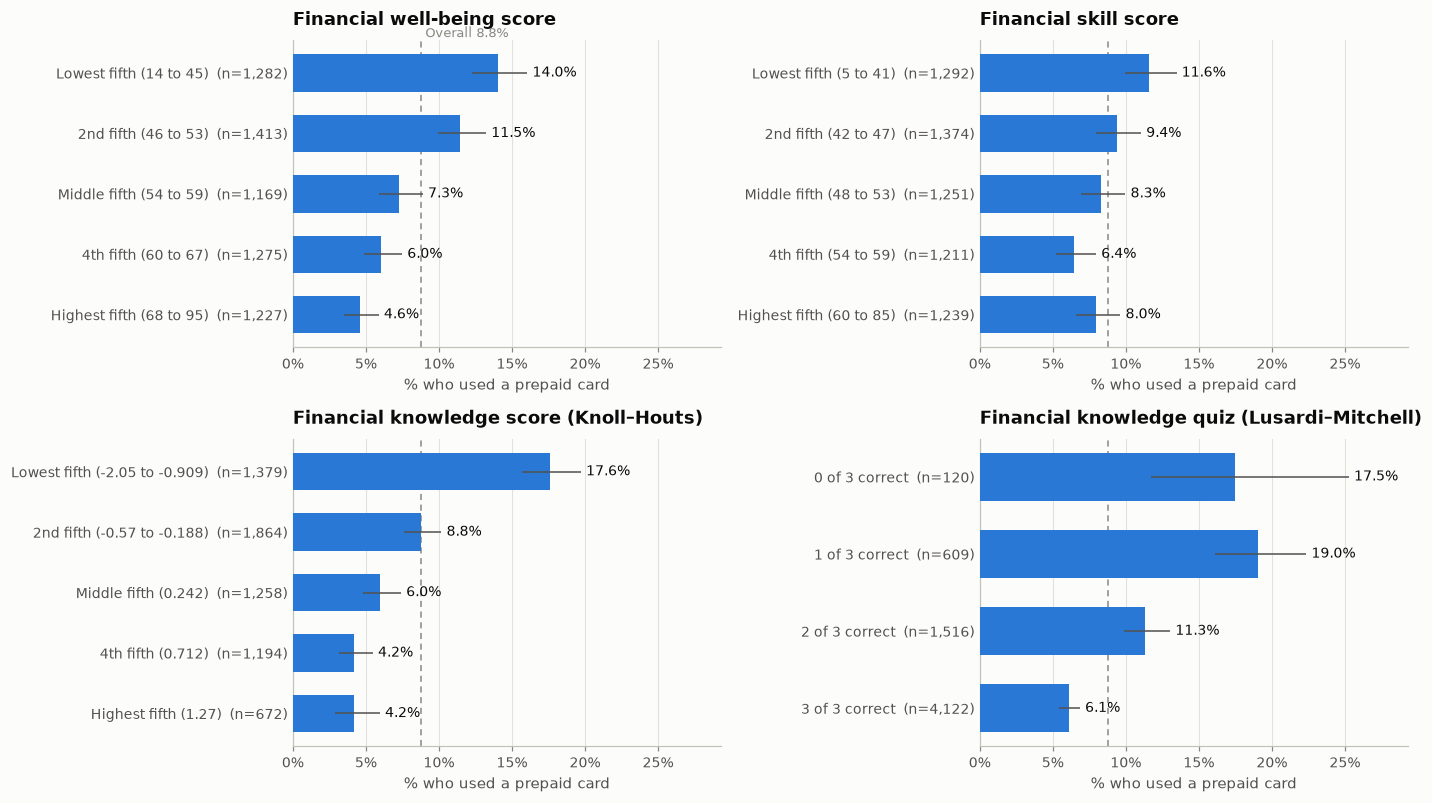

,Non-users (mean),Users (mean),Gap in standard deviations
FWBscore,56.60,50.78,-0.41
FSscore,50.96,48.90,-0.16
KHscore,-0.01,-0.49,-0.60
LMscore,2.55,2.17,-0.51


In [28]:
def score_bands(col, q=5):
    """Label each respondent with the quintile band of a score, e.g. 'Lowest fifth (14–45)'."""
    s = clean[col]
    codes = pd.qcut(s, q, labels=False, duplicates="drop")
    names = ["Lowest fifth", "2nd fifth", "Middle fifth", "4th fifth", "Highest fifth"]
    bounds = s.groupby(codes).agg(["min", "max"])
    if len(bounds) != q:
        names = [f"Band {i + 1}" for i in range(len(bounds))]
    span = {k: (f"{lo_:.3g}" if lo_ == hi_ else f"{lo_:.3g} to {hi_:.3g}") for k, (lo_, hi_) in bounds.iterrows()}
    label = {k: f"{names[i]} ({span[k]})" for i, k in enumerate(bounds.index)}
    return codes.map(label), list(label.values())


score_specs = [("FWBscore", "Financial well-being score"), ("FSscore", "Financial skill score"),
               ("KHscore", "Financial knowledge score (Knoll–Houts)"), ("LMscore", "Financial knowledge quiz (Lusardi–Mitchell)")]
score_tables = {}
for col, _ in score_specs:
    if col == "LMscore":
        score_tables[col] = rate_table(clean, col)
    else:
        band, order = score_bands(col)
        score_tables[col] = rate_table(clean.assign(_band=band), "_band").loc[order]

xmax = max(t["hi"].max() for t in score_tables.values()) * 100 * 1.16
fig, axes = plt.subplots(2, 2, figsize=(13, 7.4))
for ax, (col, title) in zip(axes.ravel(), score_specs):
    plot_rates(ax, score_tables[col], title, xmax)
axes[0, 0].text(BASE * 100, 1.0, f" Overall {BASE:.1%}", transform=axes[0, 0].get_xaxis_transform(), fontsize=8.5, color=MUTED, va="bottom")
fig.tight_layout()
fig.savefig(FIG_DIR / "07_scores.png")
plt.show()

score_compare = clean.groupby(TARGET)[["FWBscore", "FSscore", "KHscore", "LMscore"]].mean().T
score_compare.columns = ["Non-users (mean)", "Users (mean)"]
score_compare["Gap in standard deviations"] = (score_compare["Users (mean)"] - score_compare["Non-users (mean)"]) / clean[score_compare.index].std()
fmt(score_compare, "{:.2f}")

**Takeaways**

- **Tested financial knowledge separates users best.** 17.6% in the lowest knowledge band against 4.2% in the top two; on the three-question quiz, 17.5–19.0% of those with zero or one correct against 6.1% of those with all three. Users score 0.60 standard deviations lower on the knowledge score.
- **Financial well-being also separates them:** 14.0% in the lowest fifth against 4.6% in the highest (users are 0.41 standard deviations lower).
- **Self-assessed financial skill barely does:** 11.6% vs 8.0%, a gap of only 0.16 standard deviations.
- **The contrast matters for the CFPB question.** Prepaid users know measurably less about financial products than non-users, but rate their own financial skills almost as highly. That gap between knowledge and confidence is a marker of the "unsophisticated user" concern raised in the brief.

Note: the knowledge score has only 11 possible values, so its five bands are unequal in size.

#### 4.5 Overlap with other alternative financial services

These are the "restricted" same-question items (Section 3.3). They are shown to describe users, not as proposed predictors.

In [29]:
afs_names = {"PRODUSE_1": "Payday or cash-advance loan", "PRODUSE_2": "Pawn or auto-title loan",
             "PRODUSE_4": "Non-bank international money transfer", "PRODUSE_5": "Non-bank cheque cashing or money order"}
overlap = pd.DataFrame({
    "Among prepaid users": clean.loc[clean[TARGET] == 1, list(afs_names)].mean(),
    "Among non-users": clean.loc[clean[TARGET] == 0, list(afs_names)].mean(),
})
overlap.loc["Any of the four"] = [clean.loc[clean[TARGET] == 1, list(afs_names)].max(axis=1).mean(),
                                  clean.loc[clean[TARGET] == 0, list(afs_names)].max(axis=1).mean()]
overlap["Ratio"] = overlap["Among prepaid users"] / overlap["Among non-users"]
overlap.index = [afs_names.get(i, i) for i in overlap.index]
fmt(overlap, {"Among prepaid users": "{:.1%}", "Among non-users": "{:.1%}", "Ratio": "{:.1f}x"})

,Among prepaid users,Among non-users,Ratio
Payday or cash-advance loan,5.0%,2.5%,2.0x
Pawn or auto-title loan,4.6%,1.5%,3.1x
Non-bank international money transfer,6.1%,4.1%,1.5x
Non-bank cheque cashing or money order,13.6%,5.9%,2.3x
Any of the four,21.2%,12.7%,1.7x


**Takeaways**

- Prepaid users are more likely to use every other alternative financial service: pawn or auto-title loans 3.1 times, cheque cashing or money orders 2.3 times, payday loans 2.0 times.
- 21.2% of prepaid users used at least one of the four, against 12.7% of non-users. Put the other way, **about four in five prepaid users use none of them**, so prepaid use is not simply one symptom of heavy reliance on fringe finance.
- These items stay "restricted". The recommendation is to leave them out of the predictive model and use them to describe risk in the CFPB analysis.

#### 4.6 Which variables carry the most signal?

Every candidate predictor is scored on the strength of its association with prepaid use, so that variables of different types can be ranked on one scale.

- **Measure:** bias-corrected Cramér's V (0 = no association, 1 = perfect). Continuous scores are split into fifths first. It works for unordered categories, ordered scales and yes/no variables alike.
- **Significance:** chi-square test, with the Benjamini–Hochberg correction because many variables are tested at once (5% false-discovery rate).
- **Direction:** for ordered variables, the sign of the rank correlation with prepaid use.

This is a screening tool. It looks at one variable at a time and cannot see overlap between variables; that is addressed in 4.7.

Candidate predictors screened: 178
Significantly associated with prepaid use (5% false-discovery rate): 141


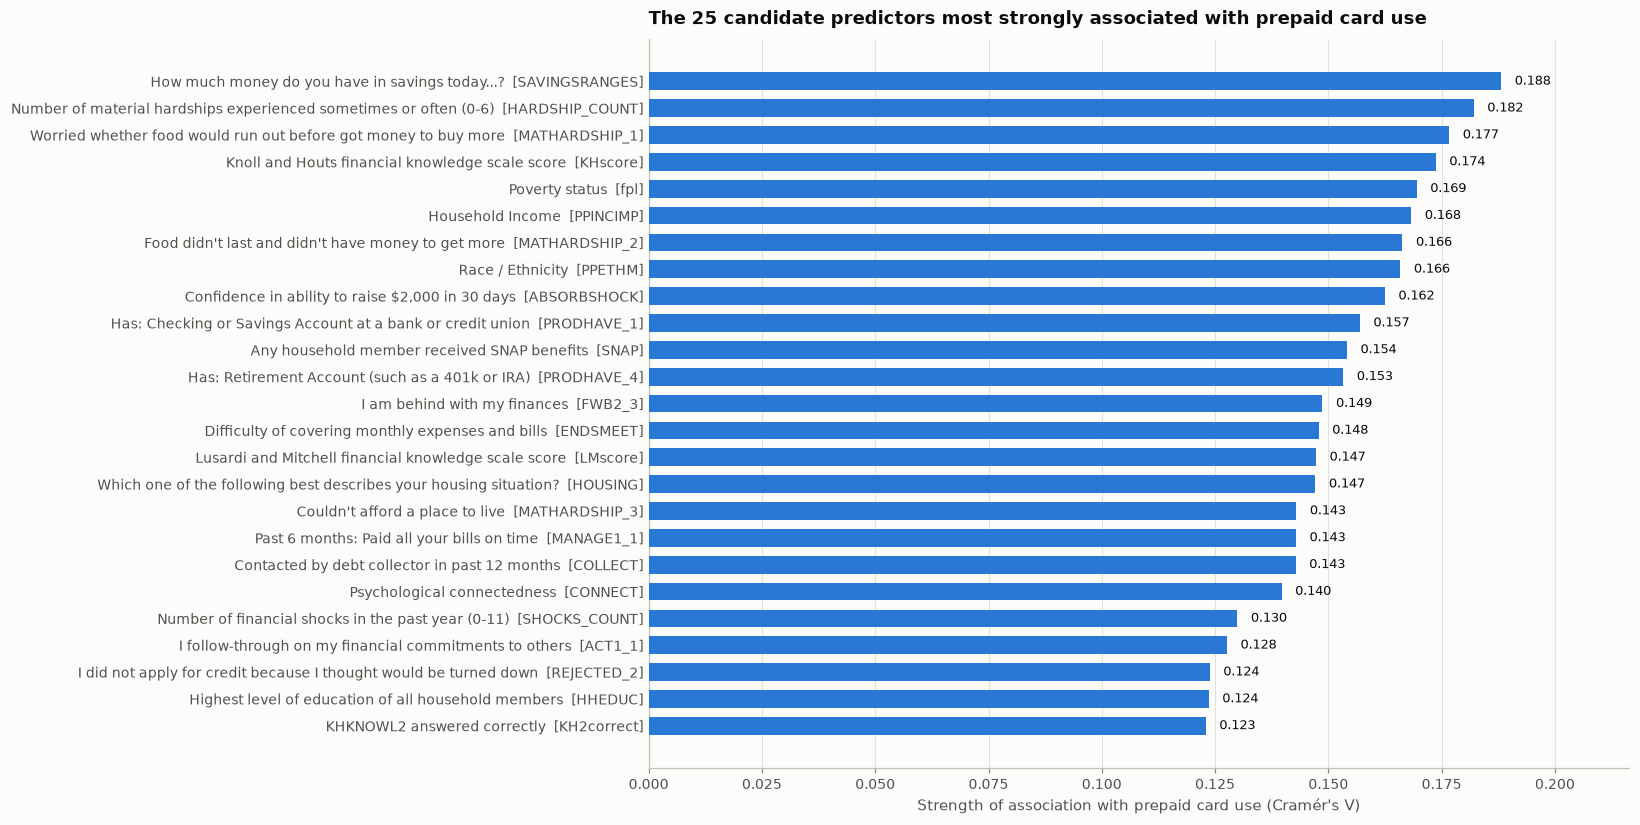

In [30]:
def cramers_v(x, y):
    """Bias-corrected Cramér's V and chi-square p-value for two categorical series."""
    ct = pd.crosstab(x, y)
    chi2, p, _, _ = stats.chi2_contingency(ct, correction=False)
    n = ct.to_numpy().sum()
    r, k = ct.shape
    phi2 = max(0.0, chi2 / n - (k - 1) * (r - 1) / (n - 1))
    r_c, k_c = r - (r - 1) ** 2 / (n - 1), k - (k - 1) ** 2 / (n - 1)
    return np.sqrt(phi2 / min(k_c - 1, r_c - 1)), p


def association_table(data, cols):
    out = []
    for col in cols:
        s = data[col]
        mtype = roles.loc[col, "measurement_type"]
        levels = pd.qcut(s, 5, labels=False, duplicates="drop") if mtype == "Continuous score" else s
        ok = levels.notna()
        v, p = cramers_v(levels[ok], data.loc[ok, TARGET])
        level_rates = data.loc[ok].groupby(levels[ok])[TARGET].agg(["mean", "size"])
        level_rates = level_rates[level_rates["size"] >= 50]
        if mtype.startswith("Nominal"):
            direction = "n/a (unordered)"
        else:
            rho = stats.spearmanr(s[ok], data.loc[ok, TARGET])[0]
            direction = "Higher value, more use" if rho > 0 else "Higher value, less use"
        out.append({"variable": col, "cramers_v": v, "p_value": p, "direction": direction,
                    "lowest_group_rate": level_rates["mean"].min(), "highest_group_rate": level_rates["mean"].max()})
    t = pd.DataFrame(out).set_index("variable")
    t["significant_fdr_5pct"] = stats.false_discovery_control(t["p_value"], method="bh") < 0.05
    return t.sort_values("cramers_v", ascending=False)


assoc = association_table(clean, CANDIDATES).join(roles[["label", "group", "measurement_type"]])
print(f"Candidate predictors screened: {len(assoc)}")
print(f"Significantly associated with prepaid use (5% false-discovery rate): {int(assoc['significant_fdr_5pct'].sum())}")

TOP_N = 25
top = assoc.head(TOP_N).iloc[::-1]
fig, ax = plt.subplots(figsize=(11.5, 8.6))
ax.barh(np.arange(len(top)), top["cramers_v"], height=0.66, color=BLUE, zorder=3)
for i, v in enumerate(top["cramers_v"]):
    ax.text(v + 0.003, i, f"{v:.3f}", va="center", fontsize=8.5, color=INK)
ax.set_yticks(np.arange(len(top)), [f"{lab if len(lab) <= 74 else lab[:72] + chr(8230)}  [{var}]" for var, lab in zip(top.index, top["label"])])
ax.set_xlim(0, top["cramers_v"].max() * 1.15)
ax.set_xlabel("Strength of association with prepaid card use (Cramér's V)")
ax.set_title(f"The {TOP_N} candidate predictors most strongly associated with prepaid card use")
ax.grid(axis="y", visible=False)
ax.tick_params(axis="y", length=0)
fig.savefig(FIG_DIR / "08_association_ranking.png")
plt.show()

In [31]:
show = assoc.head(TOP_N)[["label", "group", "cramers_v", "direction", "lowest_group_rate", "highest_group_rate"]]
display(fmt(show, {"cramers_v": "{:.3f}", "lowest_group_rate": "{:.1%}", "highest_group_rate": "{:.1%}"}))

group_signal = assoc.groupby("group").agg(candidates=("cramers_v", "size"), significant=("significant_fdr_5pct", "sum"),
                                          strongest=("cramers_v", "max"), median=("cramers_v", "median"))
group_signal["strongest_variable"] = assoc.groupby("group")["cramers_v"].idxmax()
display(fmt(group_signal.sort_values("strongest", ascending=False), {"strongest": "{:.3f}", "median": "{:.3f}"}))

nr_flags = assoc.loc[[c for c in assoc.index if c.endswith("_NR")], ["label", "cramers_v", "p_value", "significant_fdr_5pct"]]
nr_rates = binary_contrast(clean, nr_flags.index.tolist())[["rate_yes", "rate_no"]].rename(
    columns={"rate_yes": "usage if non-response", "rate_no": "usage if answered"})
display(fmt(nr_flags.join(nr_rates), {"cramers_v": "{:.3f}", "p_value": "{:.4f}",
                                      "usage if non-response": "{:.1%}", "usage if answered": "{:.1%}"}))

,label,group,cramers_v,direction,lowest_group_rate,highest_group_rate
variable,,,,,,
SAVINGSRANGES,How much money do you have in savings today...?,"Housing, savings and household resources",0.188,"Higher value, less use",4.7%,22.3%
HARDSHIP_COUNT,Number of material hardships experienced sometimes or often (0-6),"Financial strain, hardship and shocks",0.182,"Higher value, more use",5.9%,29.4%
MATHARDSHIP_1,Worried whether food would run out before got money to buy more,"Financial strain, hardship and shocks",0.177,"Higher value, more use",6.5%,22.1%
KHscore,Knoll and Houts financial knowledge scale score,Financial knowledge and numeracy (tested),0.174,"Higher value, less use",4.2%,17.6%
fpl,Poverty status,Demographics and geography,0.169,"Higher value, less use",6.3%,20.9%
PPINCIMP,Household Income,Demographics and geography,0.168,"Higher value, less use",3.5%,19.4%
MATHARDSHIP_2,Food didn't last and didn't have money to get more,"Financial strain, hardship and shocks",0.166,"Higher value, more use",6.8%,21.2%
PPETHM,Race / Ethnicity,Demographics and geography,0.166,n/a (unordered),6.0%,18.6%
ABSORBSHOCK,"Confidence in ability to raise $2,000 in 30 days","Financial strain, hardship and shocks",0.162,"Higher value, less use",5.2%,16.5%


,candidates,significant,strongest,median,strongest_variable
group,,,,,
"Housing, savings and household resources",13,11,0.188,0.085,SAVINGSRANGES
"Financial strain, hardship and shocks",34,27,0.182,0.081,HARDSHIP_COUNT
Financial knowledge and numeracy (tested),16,16,0.174,0.097,KHscore
Demographics and geography,22,12,0.169,0.035,fpl
Financial products held,8,7,0.157,0.085,PRODHAVE_1
Financial well-being,14,14,0.149,0.086,FWB2_3
Money management behaviour,29,24,0.143,0.048,MANAGE1_1
"Attitudes, traits and health",14,11,0.140,0.051,CONNECT
"Employment, retirement and military",2,1,0.114,0.061,EMPLOY


,label,cramers_v,p_value,significant_fdr_5pct,usage if non-response,usage if answered
variable,,,,,,
ABSORBSHOCK_NR,"Non-response flag: Confidence in ability to raise $2,000 in 30 days",0.055,0.0000,True,15.5%,8.4%
HSLOC_NR,Non-response flag: Where did you live at age 17?,0.054,0.0000,True,13.4%,8.3%
FRAUD2_NR,Non-response flag: Victim of financial fraud or attempted financial fraud in past 5 years,0.034,0.0039,True,12.2%,8.5%
KIDS_NoChildren_NR,Non-response flag: I have no children that I support financially,0.020,0.0634,False,6.7%,9.0%
SAVINGSRANGES_NR,Non-response flag: How much money do you have in savings today...?,0.003,0.3036,False,9.6%,8.6%
HOUSERANGES_NR,Non-response flag: About how much do you pay for your home each month?,0.000,0.9696,False,8.8%,8.8%


**Takeaways**

- **Signal is broad but individually modest.** 141 of 178 candidates are reliably associated with prepaid use, yet the strongest reaches only 0.19 on a 0–1 scale. No single question identifies users; a model has to combine many.
- **The top of the ranking is one story told several ways:** little savings, material hardship, low income and poverty, low financial knowledge, and no bank account.
- **Almost every theme contributes.** Resources, strain, knowledge, demographics, products and well-being each have a variable at 0.15 or above. The weakest themes are upbringing (4 of 10 variables significant, best 0.06) and self-assessed skill (best 0.10).
- **Non-response is informative for some questions only.** People who did not know whether they could raise \$2,000 use prepaid cards at 15.5% (8.4% among those who answered), and non-response on childhood location and on fraud also carries some signal. Declining to state savings or housing cost carries none (9.6% vs 8.6%, and 8.8% vs 8.8%), so those gaps can be imputed without a flag.

#### 4.7 Overlap between the strongest variables

Many of the top-ranked variables measure the same underlying thing. Putting several near-duplicates into a 20-variable model wastes slots and makes the model harder to interpret. The heatmap shows the rank correlation between the strongest ordered variables.

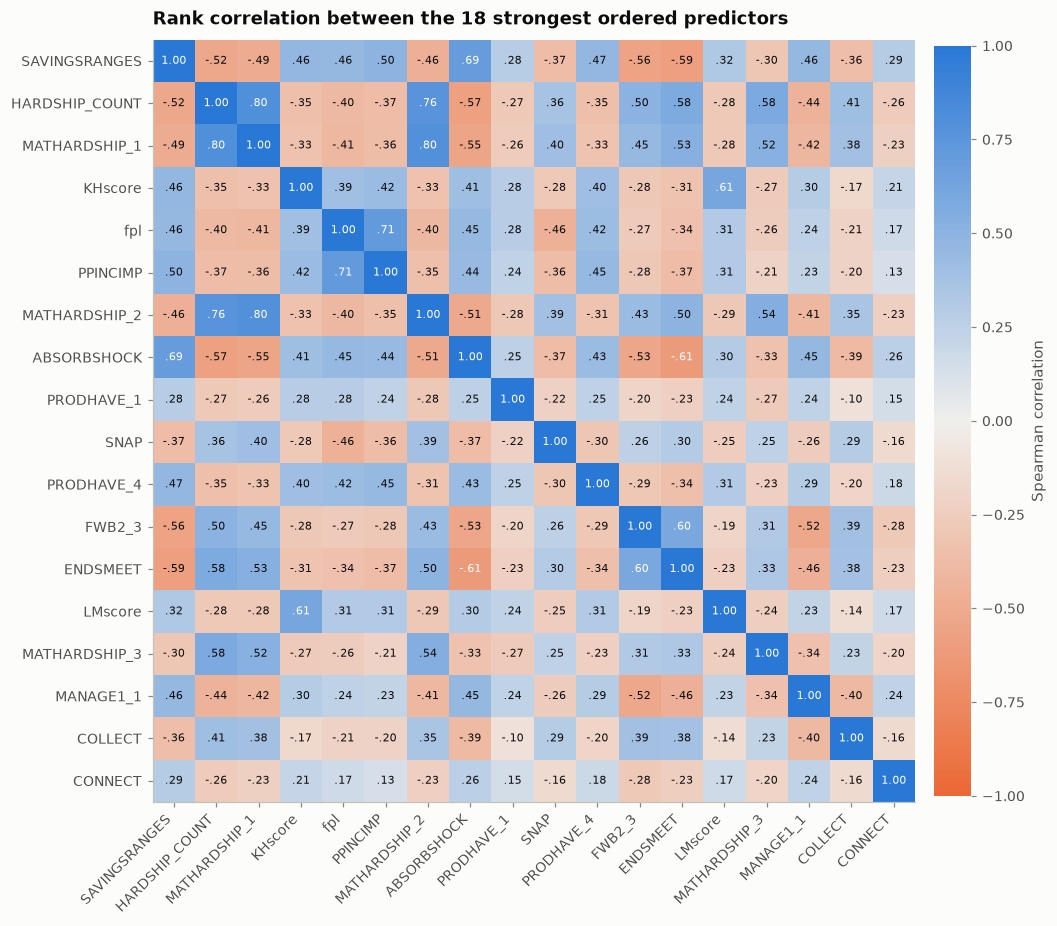

,variable_a,variable_b,spearman,a_label,b_label
0,HARDSHIP_COUNT,MATHARDSHIP_1,0.80,Number of material hardships experienced sometimes,Worried whether food would run out before got mone
1,MATHARDSHIP_1,MATHARDSHIP_2,0.80,Worried whether food would run out before got mone,Food didn't last and didn't have money to get more
2,HARDSHIP_COUNT,MATHARDSHIP_2,0.76,Number of material hardships experienced sometimes,Food didn't last and didn't have money to get more
3,fpl,PPINCIMP,0.71,Poverty status,Household Income
4,SAVINGSRANGES,ABSORBSHOCK,0.69,How much money do you have in savings today...?,"Confidence in ability to raise $2,000 in 30 days"
5,ABSORBSHOCK,ENDSMEET,-0.61,"Confidence in ability to raise $2,000 in 30 days",Difficulty of covering monthly expenses and bills
6,KHscore,LMscore,0.61,Knoll and Houts financial knowledge scale score,Lusardi and Mitchell financial knowledge scale sco
7,FWB2_3,ENDSMEET,0.60,I am behind with my finances,Difficulty of covering monthly expenses and bills
8,SAVINGSRANGES,ENDSMEET,-0.59,How much money do you have in savings today...?,Difficulty of covering monthly expenses and bills
9,HARDSHIP_COUNT,MATHARDSHIP_3,0.58,Number of material hardships experienced sometimes,Couldn't afford a place to live


In [32]:
ordered_top = [v for v in assoc.index if not assoc.loc[v, "measurement_type"].startswith("Nominal") and not v.endswith("_NR")][:18]
corr = clean[ordered_top].corr(method="spearman")

fig, ax = plt.subplots(figsize=(11, 9))
im = ax.imshow(corr, cmap=DIV_CMAP, vmin=-1, vmax=1)
ax.set_xticks(range(len(ordered_top)), ordered_top, rotation=45, ha="right")
ax.set_yticks(range(len(ordered_top)), ordered_top)
for i in range(len(ordered_top)):
    for j in range(len(ordered_top)):
        val = corr.iloc[i, j]
        ax.text(j, i, f"{val:.2f}".replace("0.", ".").replace("-.", "-."), ha="center", va="center", fontsize=7.5,
                color="white" if abs(val) > 0.6 else INK)
ax.grid(visible=False)
ax.set_title("Rank correlation between the 18 strongest ordered predictors")
cbar = fig.colorbar(im, ax=ax, fraction=0.04, pad=0.02)
cbar.set_label("Spearman correlation")
cbar.outline.set_visible(False)
fig.savefig(FIG_DIR / "09_correlation_heatmap.png")
plt.show()

pairs = (corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1)).stack().rename("spearman").reset_index()
         .rename(columns={"level_0": "variable_a", "level_1": "variable_b"}))
pairs = pairs.reindex(pairs["spearman"].abs().sort_values(ascending=False).index).head(10)
pairs["a_label"] = pairs["variable_a"].map(roles["label"]).str[:50]
pairs["b_label"] = pairs["variable_b"].map(roles["label"]).str[:50]
fmt(pairs, {"spearman": "{:.2f}"}, hide_index=True)

**Takeaways**

- **The strongest variables form a few tight clusters**, each measuring one thing:
  - *Food and material hardship:* `MATHARDSHIP_1`, `MATHARDSHIP_2` and `HARDSHIP_COUNT` (correlations 0.76–0.80).
  - *Income:* `PPINCIMP` and `fpl` (0.71).
  - *Liquidity:* `SAVINGSRANGES`, `ABSORBSHOCK`, `ENDSMEET` and `FWB2_3` (0.5–0.7 in size).
  - *Knowledge:* `KHscore` and `LMscore` (0.61).
- **Implication for the 20-variable limit:** take one representative per cluster (for example `HARDSHIP_COUNT` in place of six hardship items, one of income or poverty status, one knowledge score) and spend the remaining slots on themes that add something different.
- **Bank-account status is the most independent strong signal:** `PRODHAVE_1` correlates at no more than 0.28 with any other top variable, so it adds information the others do not.

#### 4.8 Do the effects combine, and are they robust?

**Income and banking status together.** If low income and lacking a bank account were the same signal, usage would not differ by account status within an income band.

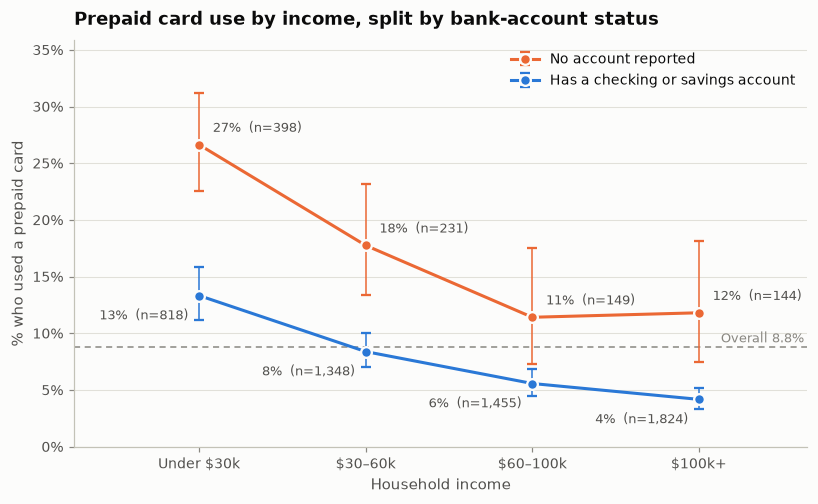

In [33]:
INCOME_BANDS = {1: "Under $30k", 2: "Under $30k", 3: "$30–60k", 4: "$30–60k", 5: "$30–60k",
                6: "$60–100k", 7: "$60–100k", 8: "$100k+", 9: "$100k+"}
INCOME_ORDER = ["Under $30k", "$30–60k", "$60–100k", "$100k+"]
AGE_BANDS = {1: "18–34", 2: "18–34", 3: "35–54", 4: "35–54", 5: "55–69", 6: "55–69", 7: "70+", 8: "70+"}
AGE_ORDER = ["18–34", "35–54", "55–69", "70+"]
view = clean.assign(income_band=clean["PPINCIMP"].map(INCOME_BANDS), age_band=clean["agecat"].map(AGE_BANDS),
                    account=clean["PRODHAVE_1"].map({1: "Has a checking or savings account", 0: "No account reported"}))

inc_acct = view.groupby(["account", "income_band"])[TARGET].agg(n="size", users="sum").reset_index()
inc_acct["rate"] = inc_acct["users"] / inc_acct["n"]
inc_acct["lo"], inc_acct["hi"] = wilson_interval(inc_acct["users"], inc_acct["n"])

fig, ax = plt.subplots(figsize=(8.6, 4.8))
x = np.arange(len(INCOME_ORDER))
for name, color in [("No account reported", ORANGE), ("Has a checking or savings account", BLUE)]:
    d = inc_acct[inc_acct["account"] == name].set_index("income_band").loc[INCOME_ORDER]
    ax.errorbar(x, d["rate"] * 100, yerr=[(d["rate"] - d["lo"]) * 100, (d["hi"] - d["rate"]) * 100],
                color=color, linewidth=2, marker="o", markersize=7, markeredgecolor=SURFACE, markeredgewidth=1.5,
                elinewidth=1, capsize=3, label=name, zorder=3)
    for xi, (rate, n) in enumerate(zip(d["rate"], d["n"])):
        above = name.startswith("No")
        ax.annotate(f"{rate:.0%}  (n={n:,})", (xi, rate * 100), textcoords="offset points",
                    xytext=(9, 11) if above else (-7, -13), ha="left" if above else "right", va="center",
                    fontsize=8.5, color=INK2)
ax.axhline(BASE * 100, color=MUTED, linewidth=1, linestyle=(0, (4, 3)))
ax.text(len(INCOME_ORDER) - 0.37, BASE * 100 + 0.4, f"Overall {BASE:.1%}", fontsize=8.5, color=MUTED, ha="right")
ax.set_xticks(x, INCOME_ORDER)
ax.set_xlim(-0.75, len(INCOME_ORDER) - 0.35)
ax.set_ylim(0, inc_acct["hi"].max() * 100 * 1.15)
ax.yaxis.set_major_formatter(mpl.ticker.PercentFormatter(decimals=0))
ax.set_xlabel("Household income")
ax.set_ylabel("% who used a prepaid card")
ax.set_title("Prepaid card use by income, split by bank-account status")
ax.grid(axis="x", visible=False)
ax.legend(loc="upper right")
fig.savefig(FIG_DIR / "10_income_by_account.png")
plt.show()

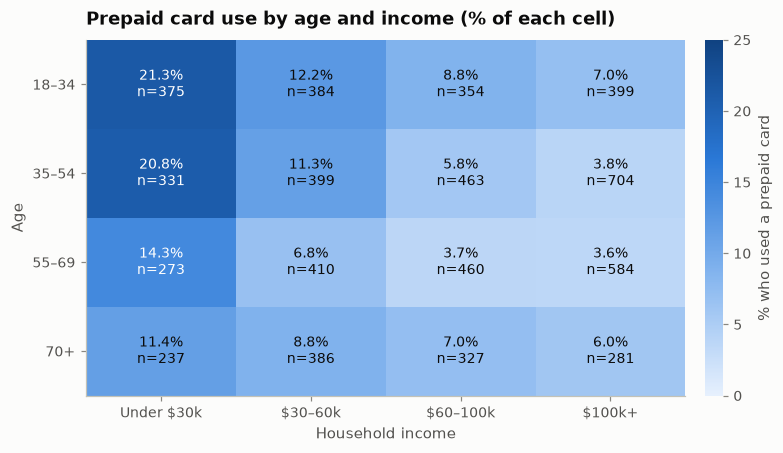

In [34]:
cell = view.groupby(["age_band", "income_band"])[TARGET].agg(["mean", "size"])
rate_grid = cell["mean"].unstack().loc[AGE_ORDER, INCOME_ORDER] * 100
n_grid = cell["size"].unstack().loc[AGE_ORDER, INCOME_ORDER]

fig, ax = plt.subplots(figsize=(7.6, 4.2))
im = ax.imshow(rate_grid, cmap=SEQ_CMAP, vmin=0, vmax=np.ceil(rate_grid.to_numpy().max() / 5) * 5, aspect="auto")
for i in range(rate_grid.shape[0]):
    for j in range(rate_grid.shape[1]):
        val = rate_grid.iloc[i, j]
        ax.text(j, i, f"{val:.1f}%\nn={n_grid.iloc[i, j]:,}", ha="center", va="center", fontsize=9,
                color="white" if val > 13 else INK)
ax.set_xticks(range(len(INCOME_ORDER)), INCOME_ORDER)
ax.set_yticks(range(len(AGE_ORDER)), AGE_ORDER)
ax.set_xlabel("Household income")
ax.set_ylabel("Age")
ax.grid(visible=False)
ax.set_title("Prepaid card use by age and income (% of each cell)")
cbar = fig.colorbar(im, ax=ax, fraction=0.045, pad=0.03)
cbar.set_label("% who used a prepaid card")
cbar.outline.set_visible(False)
fig.savefig(FIG_DIR / "11_age_by_income.png")
plt.show()

**Robustness to the oversamples.** The pooled data over-represents older adults and lower-income minority households (Section 2.2). The screening is repeated on the general-population sample alone to confirm the findings are not produced by the sample mix.

In [35]:
general = clean[clean["sample"] == 1]
assoc_general = association_table(general, CANDIDATES)
robust = assoc[["label", "cramers_v"]].rename(columns={"cramers_v": "V_all_samples"}).join(
    assoc_general["cramers_v"].rename("V_general_population_only"))
robust["rank_all"] = robust["V_all_samples"].rank(ascending=False).astype(int)
robust["rank_general"] = robust["V_general_population_only"].rank(ascending=False).astype(int)

rho = stats.spearmanr(robust["V_all_samples"], robust["V_general_population_only"])[0]
top20_all, top20_gen = set(robust.nsmallest(20, "rank_all").index), set(robust.nsmallest(20, "rank_general").index)
print(f"General-population sample: {len(general):,} respondents, usage rate {general[TARGET].mean():.1%}")
print(f"Rank correlation of association strength, all samples vs general population only: {rho:.2f}")
print(f"Variables in the top 20 under both views: {len(top20_all & top20_gen)} of 20")
display(fmt(robust.head(15), {"V_all_samples": "{:.3f}", "V_general_population_only": "{:.3f}"}))

inc_robust = pd.DataFrame({"All samples": rate_table(clean, "PPINCIMP")["rate"],
                           "General population only": rate_table(general, "PPINCIMP")["rate"]})
display(fmt(inc_robust, "{:.1%}"))

General-population sample: 4,977 respondents, usage rate 8.5%
Rank correlation of association strength, all samples vs general population only: 0.97
Variables in the top 20 under both views: 19 of 20


,label,V_all_samples,V_general_population_only,rank_all,rank_general
variable,,,,,
SAVINGSRANGES,How much money do you have in savings today...?,0.188,0.179,1,2
HARDSHIP_COUNT,Number of material hardships experienced sometimes or often (0-6),0.182,0.181,2,1
MATHARDSHIP_1,Worried whether food would run out before got money to buy more,0.177,0.176,3,3
KHscore,Knoll and Houts financial knowledge scale score,0.174,0.156,4,8
fpl,Poverty status,0.169,0.169,5,5
PPINCIMP,Household Income,0.168,0.171,6,4
MATHARDSHIP_2,Food didn't last and didn't have money to get more,0.166,0.166,7,6
PPETHM,Race / Ethnicity,0.166,0.142,8,15
ABSORBSHOCK,"Confidence in ability to raise $2,000 in 30 days",0.162,0.150,9,10


,All samples,General population only
"Less than $20,000",19.4%,18.6%
"$20,000–29,999",15.3%,17.4%
"$30,000–39,999",11.3%,10.6%
"$40,000–49,999",8.9%,8.9%
"$50,000–59,999",8.7%,8.4%
"$60,000–74,999",6.3%,5.6%
"$75,000–99,999",6.0%,5.4%
"$100,000–149,999",5.7%,5.6%
"$150,000 or more",3.5%,3.9%


**Takeaways**

- **Income and bank-account status are separate signals that stack.** In every income band, people reporting no account use prepaid cards two to three times as often as those with one: 27% vs 13% under \$30,000, and 12% vs 4% at \$100,000 or more. Low-income respondents with no account reported (n=398) are the highest-use segment found, at three times the overall rate.
- **Age and income also stack.** Use peaks at about 21% for under-55s with income below \$30,000 and falls to about 4% for 35–69-year-olds with income of \$100,000 or more. Age matters most at low incomes.
- **The findings hold without the oversamples.** On the general-population sample alone the association ranking is almost unchanged (rank correlation 0.97; 19 of the top 20 variables are the same) and the income gradient is nearly identical (18.6% falling to 3.9%).
- **Two signals are somewhat amplified by the oversamples:** race/ethnicity drops from 8th to 15th and the knowledge scores weaken slightly in the general population. They remain meaningful but should not be over-weighted.

---
## 5. Summary and hand-off to modelling

#### What is now established

1. **The data is trustworthy.** It matches the official codebook on every variable, and every cleaning rule is documented and logged.
2. **Prepaid card use is a minority behaviour (8.8%) concentrated among financially fragile households**: low income, little or no savings, material hardship, no bank account, low financial knowledge. Younger adults and Black and Hispanic respondents use them more.
3. **Most users are nonetheless mainstream.** Two-thirds have a bank account and most have income above \$30,000, because the high-rate groups are small.
4. **Signals are modest individually and overlap heavily.** Prediction requires a combination of variables, chosen to cover different themes.

#### Outputs handed to the next steps

| File | Contents |
|---|---|
| `data/cfpb_clean.csv` | Cleaned data: 6,367 respondents, 204 columns, non-answers as true missing values |
| `data/variable_roles.csv` | For every column: label, group, measurement type, role, missing rate |
| `figures/` | The 11 charts in this part as image files |

#### Implications for modelling (Steps 5–8)

- **Feature selection (Step 5):** pick up to 20 from the 178 candidates, one representative per correlated cluster (Section 4.7), covering resources, strain, knowledge, banking and demographics.
- **Preparation (Step 6):** stratified train/test split; impute missing values, one-hot encode the unordered categories and standardise, all fitted on training data only.
- **Models and evaluation (Steps 7–8):** weight the classes for the 1-to-10 imbalance and judge models on recall, precision, precision-recall AUC and lift, not accuracy.

#### Decisions needed before Step 5

1. **Other alternative-finance items** (`PRODUSE_1`, `2`, `4`, `5`): recommended **out** of the predictive model (Sections 3.3 and 4.5).
2. **Race / ethnicity:** relevant to the CFPB at-risk analysis; its use in a marketing-targeting model raises fair-lending concerns (Section 4.1).
3. **Non-response flags:** recommended to keep only `ABSORBSHOCK_NR` as a candidate; the savings and housing-cost flags carry no signal (Section 4.6).

#### Limitations

- The survey is self-reported and was fielded in 2016; prepaid products and their users may have changed since.
- The outcome records whether a prepaid card was used, not how often, what it cost in fees, or why.
- All figures are unweighted, as the brief requires, so they describe this sample and are not national estimates.
- Everything in Section 4 is association, one variable at a time. It does not show that any characteristic causes prepaid card use.

# Part 2: Predictor selection and data preparation

*Lead: Arnav Gannamani.*

**Purpose.** Turn the cleaned survey data from Part 1 into the fixed inputs that every model in this project will use: one train/test split, one set of 17 predictors, and one preparation pipeline.

| Section | What it delivers |
|---|---|
| 1. Setup | Cleaned data and variable roles loaded from Part 1 |
| 2. Eligible predictors | The pool that selection is allowed to draw from |
| 3. Train/test split | A fixed 80/20 split, made **before** any selection |
| 4. Selecting the predictors | Screening, redundancy control and the final list with reasons |
| 5. Validation | Evidence that the 17 predictors lose nothing against the alternatives |
| 6. Preparation pipeline | Imputation, encoding and standardisation, fitted on training data only |
| 7. Hand-off | Saved files and how the modelling part uses them |

### Summary

- **One fixed split:** 5,093 training respondents and 1,274 test respondents, both with an 8.8% usage rate. The split was made before any predictor was chosen, and the test set is not used anywhere in this part.
- **17 predictors selected** from 173 eligible variables, covering demographics, banking relationship, liquidity, financial strain, knowledge, well-being and behaviour. Eleven come from a statistical shortlist; six were added for coverage and interpretability. The brief allows up to 20.
- **Age, marital status, sex and SNAP receipt are not eligible as predictors.** They are prohibited bases under fair-lending law (ECOA), so a targeting model should not use them. Age, marital status and SNAP stay in the data files for describing groups.
- **The selection costs nothing in predictive power.** In cross-validation the final 17 score a ROC-AUC of 0.729, as good as the purely statistical alternatives (0.726 and 0.720) and well above using all 173 variables (0.681).
- **The two open decisions turned out not to matter for accuracy.** Adding race/ethnicity moves the ROC-AUC from 0.729 to 0.730, and adding the other non-bank products leaves it at 0.729. Both are far inside the fold-to-fold noise of 0.030, so both are left out.
- **Expect moderate predictive power.** A ROC-AUC near 0.73 means the predictors rank users above non-users clearly better than chance, but far from perfectly. Stronger models in Task B may add a little; they are unlikely to change the picture.
- **One preparation pipeline** (`prep.py`) fills missing values, one-hot encodes two unordered categories and standardises the ordered variables, turning 17 predictors into 26 model columns. It is fitted on training data only.

---
## 1. Setup

In [36]:
from pathlib import Path
import warnings

import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from scipy import stats
from IPython.display import display

from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_validate, train_test_split
from sklearn.pipeline import make_pipeline, Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
import sklearn

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_columns", 60, "display.width", 220, "display.max_colwidth", 110, "display.max_rows", 100)

DATA_DIR = Path("data")
FIG_DIR = Path("figures")
TARGET = "PRODUSE_3"
SEED = 42            # one seed for the split and the cross-validation folds, so results are reproducible
TEST_SIZE = 0.20

INK, INK2, MUTED = "#0b0b0b", "#52514e", "#898781"
GRID, AXIS, SURFACE = "#e1e0d9", "#c3c2b7", "#fcfcfb"
BLUE, ORANGE = "#2a78d6", "#eb6834"
SEQ_CMAP = LinearSegmentedColormap.from_list("seq_blue", ["#f3f7fe", "#86b6ef", "#2a78d6", "#104281"])
mpl.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "figure.dpi": 110, "savefig.dpi": 200, "savefig.bbox": "tight",
    "font.size": 10, "text.color": INK, "axes.labelcolor": INK2,
    "axes.titlesize": 11.5, "axes.titleweight": "bold", "axes.titlelocation": "left", "axes.titlepad": 10,
    "axes.edgecolor": AXIS, "axes.linewidth": 0.8, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "axes.axisbelow": True, "grid.color": GRID, "grid.linewidth": 0.7,
    "xtick.color": MUTED, "ytick.color": MUTED, "xtick.labelcolor": INK2, "ytick.labelcolor": INK2,
    "xtick.labelsize": 9, "ytick.labelsize": 9, "legend.frameon": False, "legend.fontsize": 9,
})


def fmt(df, formats, hide_index=False):
    """Return a display copy of a table with numbers formatted as text."""
    out = df.copy()
    if isinstance(formats, str):
        formats = {c: formats for c in out.columns if pd.api.types.is_numeric_dtype(out[c])}
    for col, pattern in formats.items():
        if col in out.columns:
            out[col] = out[col].map(lambda v, p=pattern: p.format(v) if pd.notna(v) else "")
    return out.reset_index(drop=True) if hide_index else out


clean = pd.read_csv(DATA_DIR / "cfpb_clean.csv", index_col="PUF_ID")
roles = pd.read_csv(DATA_DIR / "variable_roles.csv", index_col="variable")
assert list(clean.columns) == list(roles.index), "Cleaned data and roles table are out of step"

print(f"pandas {pd.__version__} | scikit-learn {sklearn.__version__}")
print(f"Cleaned data: {clean.shape[0]:,} respondents x {clean.shape[1]} columns")
print(f"Prepaid card users: {int(clean[TARGET].sum())} ({clean[TARGET].mean():.2%})")

pandas 3.1.1 | scikit-learn 1.9.1
Cleaned data: 6,367 respondents x 204 columns
Prepaid card users: 560 (8.80%)


---
## 2. Eligible predictors

Part 1 left 178 candidate predictors and two open decisions. Both are settled here, together with a third added after the team's fairness review, and Section 5 measures what the decisions cost.

| Decision | Choice made here | Reason |
|---|---|---|
| Other non-bank products (`PRODUSE_1`, `2`, `4`, `5`) | **Not eligible** | Answered in the same tick-box question as the outcome; a company would not know them for a new prospect |
| Race / ethnicity (`PPETHM`) | **Not eligible as a predictor; kept as a profiling column** | Selecting who receives a financial-product offer by race raises fair-lending concerns. Keeping the column alongside the data still lets the CFPB analysis describe at-risk groups by race and lets the team check the model for disparate outcomes |
| Prohibited bases under fair-lending law: sex (`PPGENDER`), marital status (`PPMARIT`), age (`agecat`), receipt of public assistance (`SNAP`) | **Not eligible as predictors; age, marital status and SNAP kept as describe-only columns** | The Equal Credit Opportunity Act (ECOA) prohibits credit decisions on these bases. A plain prepaid card is not credit, but cards with overdraft features can be, and regulators apply the same thinking to marketing and targeting. The fairness audit in Part 5 found that removing them costs no accuracy |

Each choice can be reversed by editing one line below and re-running the notebook.

In [37]:
INCLUDE_RACE_ETHNICITY = False       # decision 2 above
PROFILE_COLUMNS = ["PPETHM", "sample", "PRODUSE_1", "PRODUSE_2", "PRODUSE_4", "PRODUSE_5"]   # carried along, never used as predictors

candidates = roles.index[roles["role"] == "Candidate predictor"].tolist()
# Prohibited bases under the Equal Credit Opportunity Act (ECOA): sex, marital status, age and receipt of public assistance (SNAP).
# Not eligible as predictors for a targeting model. Age, marital status and SNAP are kept in train/test as describe-only columns.
ECOA_EXCLUDED = ["PPGENDER", "PPMARIT", "agecat", "SNAP"]
DESCRIBE_ONLY = ["agecat", "PPMARIT", "SNAP"]

eligible = [c for c in candidates if (INCLUDE_RACE_ETHNICITY or c != "PPETHM") and c not in ECOA_EXCLUDED]
NOMINAL = set(roles.index[roles["measurement_type"].str.startswith("Nominal")])

print(f"Candidate predictors from Part 1: {len(candidates)}")
print(f"Eligible for selection:           {len(eligible)}")
display(roles.loc[eligible, "measurement_type"].value_counts().rename("eligible predictors").to_frame())

Candidate predictors from Part 1: 178
Eligible for selection:           173


,eligible predictors
measurement_type,
Ordinal (ordered scale or count),83
Binary,77
Nominal (unordered categories),9
Continuous score,4


---
## 3. Train/test split

The data is split **before** any predictor is chosen. If predictors were chosen using all the data and the split made afterwards, the test set would already have influenced the model, and its results would look better than they really are.

- **80% training (used for everything in this part), 20% test (set aside, untouched until final model evaluation).**
- **Stratified on the outcome**, so both parts have the same share of prepaid users.
- **Fixed random seed**, so every team member gets the identical split.

In [38]:
train, test = train_test_split(clean, test_size=TEST_SIZE, stratify=clean[TARGET], random_state=SEED)

SAMPLE_LABELS = {1: "General population", 2: "Age 62+ oversample", 3: "Race/ethnicity and poverty oversample"}
balance = pd.DataFrame({
    "Respondents": [len(train), len(test)],
    "Prepaid users": [int(train[TARGET].sum()), int(test[TARGET].sum())],
    "Usage rate": [train[TARGET].mean(), test[TARGET].mean()],
    **{f"Share: {label}": [(train["sample"] == k).mean(), (test["sample"] == k).mean()] for k, label in SAMPLE_LABELS.items()},
    "Mean income band (1-9)": [train["PPINCIMP"].mean(), test["PPINCIMP"].mean()],
    "Mean age band (1-8)": [train["agecat"].mean(), test["agecat"].mean()],
}, index=["Training set", "Test set"])
display(fmt(balance, {"Respondents": "{:,}", "Usage rate": "{:.2%}", "Mean income band (1-9)": "{:.2f}", "Mean age band (1-8)": "{:.2f}",
                      **{c: "{:.1%}" for c in balance.columns if c.startswith("Share")}}).T)
assert set(train.index).isdisjoint(test.index) and len(train) + len(test) == len(clean)

,Training set,Test set
Respondents,"5,093","1,274"
Prepaid users,448,112
Usage rate,8.80%,8.79%
Share: General population,78.5%,77.0%
Share: Age 62+ oversample,15.5%,16.2%
Share: Race/ethnicity and poverty oversample,6.0%,6.8%
Mean income band (1-9),5.53,5.47
Mean age band (1-8),4.46,4.47


**Result.** 5,093 respondents for training and 1,274 for testing. The two parts match on the outcome (8.80% and 8.79% users, 448 and 112 people), on the mix of survey samples, and on average income and age. The test set is now set aside.

---
## 4. Selecting the predictors

**From here on, only the training set is used.**

The brief allows up to 20 predictors. The selection has three steps:

1. **Screen** every eligible variable for the strength of its link to prepaid use.
2. **Remove redundancy**, so that several versions of the same signal do not crowd out other themes.
3. **Apply judgement** for coverage and interpretability, with every change from the statistical shortlist written down.

#### 4.1 Screening

Same measure as Part 1 (bias-corrected Cramér's V, 0 = no association, 1 = perfect), recomputed on the training set only.

In [39]:
def levels(series, col):
    """Continuous scores are cut into fifths so that every variable is compared as categories."""
    if roles.loc[col, "measurement_type"] == "Continuous score":
        return pd.qcut(series, 5, labels=False, duplicates="drop")
    return series


def cramers_v(x, y):
    ct = pd.crosstab(x, y)
    chi2, p, _, _ = stats.chi2_contingency(ct, correction=False)
    n = ct.to_numpy().sum()
    r, k = ct.shape
    phi2 = max(0.0, chi2 / n - (k - 1) * (r - 1) / (n - 1))
    r_c, k_c = r - (r - 1) ** 2 / (n - 1), k - (k - 1) ** 2 / (n - 1)
    return np.sqrt(phi2 / max(min(k_c - 1, r_c - 1), 1e-9)), p


rows = []
for col in eligible:
    ok = train[col].notna()
    v, p = cramers_v(levels(train.loc[ok, col], col), train.loc[ok, TARGET])
    rows.append({"variable": col, "cramers_v": v, "p_value": p})
screen = pd.DataFrame(rows).set_index("variable").join(roles[["label", "group", "measurement_type", "pct_missing"]])
screen["significant"] = stats.false_discovery_control(screen["p_value"], method="bh") < 0.05
screen = screen.sort_values("cramers_v", ascending=False)

print(f"Eligible predictors screened on the training set: {len(screen)}")
print(f"Reliably associated with prepaid use (5% false-discovery rate): {int(screen['significant'].sum())}")
display(fmt(screen.head(15)[["label", "group", "cramers_v"]], {"cramers_v": "{:.3f}"}))

Eligible predictors screened on the training set: 173
Reliably associated with prepaid use (5% false-discovery rate): 133


,label,group,cramers_v
variable,,,
SAVINGSRANGES,How much money do you have in savings today...?,"Housing, savings and household resources",0.194
HARDSHIP_COUNT,Number of material hardships experienced sometimes or often (0-6),"Financial strain, hardship and shocks",0.185
MATHARDSHIP_1,Worried whether food would run out before got money to buy more,"Financial strain, hardship and shocks",0.178
MATHARDSHIP_2,Food didn't last and didn't have money to get more,"Financial strain, hardship and shocks",0.170
PPINCIMP,Household Income,Demographics and geography,0.170
fpl,Poverty status,Demographics and geography,0.169
ABSORBSHOCK,"Confidence in ability to raise $2,000 in 30 days","Financial strain, hardship and shocks",0.167
KHscore,Knoll and Houts financial knowledge scale score,Financial knowledge and numeracy (tested),0.161
HOUSING,Which one of the following best describes your housing situation?,"Housing, savings and household resources",0.157


#### 4.2 Redundancy control

Taking the 20 highest-ranked variables would give several copies of the same thing (three food-hardship measures, two income measures, four liquidity measures). Instead, variables are taken in rank order and **skipped if they are too closely related to one already chosen**.

"Too closely related" means an association of 0.60 or more with any variable already on the list. Association between two predictors is the rank correlation when both are ordered, and Cramér's V when either is an unordered category.

In [40]:
ordered_cols = [c for c in eligible if c not in NOMINAL]
spearman_abs = train[ordered_cols].corr(method="spearman").abs()


def pair_association(a, b):
    """Strength of the relationship between two predictors, 0 to 1."""
    if a in spearman_abs.index and b in spearman_abs.index:
        return spearman_abs.loc[a, b]
    ok = train[a].notna() & train[b].notna()
    return cramers_v(levels(train.loc[ok, a], a), levels(train.loc[ok, b], b))[0]


REDUNDANCY_LIMIT = 0.60
shortlist, skipped = [], []
for col in screen.index:
    if len(shortlist) == 20:
        break
    clash = next((s for s in shortlist if pair_association(col, s) >= REDUNDANCY_LIMIT), None)
    if clash is None:
        shortlist.append(col)
    else:
        skipped.append({"skipped": col, "label": roles.loc[col, "label"], "too close to": clash,
                        "association": pair_association(col, clash)})

print("Statistical shortlist (rank order):")
display(fmt(screen.loc[shortlist, ["label", "group", "cramers_v"]], {"cramers_v": "{:.3f}"}))
print("Skipped as redundant:")
display(fmt(pd.DataFrame(skipped), {"association": "{:.2f}"}, hide_index=True))

Statistical shortlist (rank order):


,label,group,cramers_v
variable,,,
SAVINGSRANGES,How much money do you have in savings today...?,"Housing, savings and household resources",0.194
HARDSHIP_COUNT,Number of material hardships experienced sometimes or often (0-6),"Financial strain, hardship and shocks",0.185
PPINCIMP,Household Income,Demographics and geography,0.170
KHscore,Knoll and Houts financial knowledge scale score,Financial knowledge and numeracy (tested),0.161
HOUSING,Which one of the following best describes your housing situation?,"Housing, savings and household resources",0.157
ENDSMEET,Difficulty of covering monthly expenses and bills,"Financial strain, hardship and shocks",0.155
FWB2_3,I am behind with my finances,Financial well-being,0.152
COLLECT,Contacted by debt collector in past 12 months,"Financial strain, hardship and shocks",0.150
PRODHAVE_1,Has: Checking or Savings Account at a bank or credit union,Financial products held,0.149


Skipped as redundant:


,skipped,label,too close to,association
0,MATHARDSHIP_1,Worried whether food would run out before got money to buy more,HARDSHIP_COUNT,0.80
1,MATHARDSHIP_2,Food didn't last and didn't have money to get more,HARDSHIP_COUNT,0.76
2,fpl,Poverty status,PPINCIMP,0.71
3,ABSORBSHOCK,"Confidence in ability to raise $2,000 in 30 days",SAVINGSRANGES,0.69
4,FWBscore,Financial well-being scale score,SAVINGSRANGES,0.66
5,LMscore,Lusardi and Mitchell financial knowledge scale score,KHscore,0.61
6,FWB2_1,Giving a gift...would put a strain on my finances for the month,ENDSMEET,0.62


#### 4.3 The final 17

The statistical shortlist is a starting point, not the answer. It has three weaknesses for this project:

- **It leaves out the respondent's education, employment and health insurance**, which both the card company (segments it can actually reach) and the CFPB (who is at risk) need.
- **It uses single survey items where a full scale exists** (one "behind with my finances" question in place of the ten-item financial well-being score).
- **It over-samples one theme.** Eight of its twenty slots are financial-strain items, including two single hardship questions alongside the hardship count.

The final list keeps the statistical core and swaps the weakest or most duplicative items for those gaps. It stops at 17 rather than filling all 20 slots: the remaining shortlist items duplicate predictors already chosen, and Section 5 shows the 17 lose nothing against the 20-item shortlist. Every variable's reason is recorded below.

In [41]:
FINAL = {
    # Demographics a marketer can reach and a regulator can describe
    "PPINCIMP":       "Strongest demographic gradient (Part 1, 4.1). Chosen over poverty status (fpl): same signal, finer scale.",
    "PPEDUC":         "Added for coverage. Respondent's own education; chosen over household education (HHEDUC) as it describes the person.",
    "HOUSING":        "On the shortlist. Renters and non-owners use prepaid cards far more than homeowners.",
    "EMPLOY":         "Added for coverage. Highest use among the disabled, unemployed and part-time workers.",
    # Banking relationship
    "PRODHAVE_1":     "On the shortlist. Bank-account status is the most independent strong signal (Part 1, 4.7).",
    "PRODHAVE_4":     "On the shortlist. Retirement account: marks attachment to mainstream long-term finance.",
    "PRODHAVE_3":     "Added. Health insurance: second-largest product gap after the bank account.",
    # Liquidity and resources
    "SAVINGSRANGES":  "On the shortlist; the single strongest variable.",
    "ABSORBSHOCK":    "Added. Could raise $2,000 in 30 days: liquidity under stress. Related to savings (0.69) but far fewer missing answers.",
    "VOLATILITY":     "Added. Month-to-month income volatility: irregular income is a stated use case for prepaid cards.",
    # Strain and shocks
    "HARDSHIP_COUNT": "On the shortlist. One count in place of six separate hardship items.",
    "COLLECT":        "On the shortlist. Contact from a debt collector: marker of credit distress.",
    "REJECTED_1":     "On the shortlist. Turned down for credit: blocked access to mainstream credit.",
    "SHOCKS_COUNT":   "On the shortlist. Number of financial shocks in the past year.",
    # Knowledge, well-being, behaviour
    "KHscore":        "On the shortlist. Tested financial knowledge; central to the CFPB 'unsophisticated user' question.",
    "FWBscore":       "Replaces the single item FWB2_3. The CFPB's own ten-item financial well-being score.",
    "MANAGE1_1":      "On the shortlist. Pays bills on time: the strongest money-management behaviour.",
}
selected = list(FINAL)
assert len(selected) == 17 and set(selected) <= set(eligible)   # the brief allows up to 20

dropped_from_shortlist = [c for c in shortlist if c not in selected]
added_to_shortlist = [c for c in selected if c not in shortlist]
print(f"Kept from the statistical shortlist: {len(set(selected) & set(shortlist))} of 20")
print(f"Added by judgement ({len(added_to_shortlist)}): {', '.join(added_to_shortlist)}")
print(f"Dropped from the shortlist ({len(dropped_from_shortlist)}): {', '.join(dropped_from_shortlist)}")

Kept from the statistical shortlist: 11 of 20
Added by judgement (6): PPEDUC, EMPLOY, PRODHAVE_3, ABSORBSHOCK, VOLATILITY, FWBscore
Dropped from the shortlist (9): ENDSMEET, FWB2_3, MATHARDSHIP_3, CONNECT, HHEDUC, REJECTED_2, ACT1_1, MATHARDSHIP_6, KH2correct


In [42]:
PREPARATION = {"scaled": "Impute median, standardise",
               "binary": "Impute most frequent, keep as 0/1",
               "nominal": "Impute most frequent, one-hot encode"}


def preparation_rule(col):
    if col in NOMINAL:
        return PREPARATION["nominal"]
    return PREPARATION["binary"] if roles.loc[col, "measurement_type"] == "Binary" else PREPARATION["scaled"]


# How realistically a card company could know this about a prospect. This is the team's judgement, not a data fact.
AVAILABILITY = {
    "PPINCIMP": "Yes (stated or modelled income)", "agecat": "Yes", "PPEDUC": "Partly (marketing data)", "HOUSING": "Yes (owner / renter)",
    "EMPLOY": "Partly (application data)", "PPMARIT": "Partly (marketing data)",
    "PRODHAVE_1": "Partly (application or partner data)", "PRODHAVE_4": "Partly (application or partner data)", "PRODHAVE_3": "Partly (application data)",
    "SAVINGSRANGES": "Survey only", "ABSORBSHOCK": "Survey only", "VOLATILITY": "Survey only",
    "HARDSHIP_COUNT": "Survey only", "SNAP": "Survey only", "COLLECT": "Yes (credit bureau)", "REJECTED_1": "Partly (credit bureau)",
    "SHOCKS_COUNT": "Survey only", "KHscore": "Survey only", "FWBscore": "Survey only", "MANAGE1_1": "Partly (credit bureau payment history)",
}

features = pd.DataFrame(index=pd.Index(selected, name="variable"))
features["label"] = roles.loc[selected, "label"]
features["theme"] = roles.loc[selected, "group"]
features["measurement_type"] = roles.loc[selected, "measurement_type"]
features["cramers_v_train"] = screen.loc[selected, "cramers_v"].round(3)
features["screening_rank"] = [screen.index.get_loc(c) + 1 for c in selected]
features["pct_missing_train"] = (train[selected].isna().mean() * 100).round(1)
features["closest_other_predictor"] = [max((o for o in selected if o != c), key=lambda o: pair_association(c, o)) for c in selected]
features["association_with_closest"] = [round(pair_association(c, o), 2) for c, o in zip(selected, features["closest_other_predictor"])]
features["preparation"] = [preparation_rule(c) for c in selected]
features["available_to_card_company"] = pd.Series(AVAILABILITY)
features["why_selected"] = pd.Series(FINAL)

display(features[["label", "theme", "cramers_v_train", "screening_rank", "pct_missing_train", "why_selected"]])
display(features["theme"].value_counts().rename("predictors").to_frame())

,label,theme,cramers_v_train,screening_rank,pct_missing_train,why_selected
variable,,,,,,
PPINCIMP,Household Income,Demographics and geography,0.170,5,0.0,"Strongest demographic gradient (Part 1, 4.1). Chosen over poverty status (fpl): same signal, finer scale."
PPEDUC,Education (Highest Degree Received),Demographics and geography,0.111,30,0.0,Added for coverage. Respondent's own education; chosen over household education (HHEDUC) as it describes t...
HOUSING,Which one of the following best describes your housing situation?,"Housing, savings and household resources",0.157,9,0.3,On the shortlist. Renters and non-owners use prepaid cards far more than homeowners.
EMPLOY,Primary or only employment status,"Employment, retirement and military",0.113,28,1.4,"Added for coverage. Highest use among the disabled, unemployed and part-time workers."
PRODHAVE_1,Has: Checking or Savings Account at a bank or credit union,Financial products held,0.149,13,0.0,"On the shortlist. Bank-account status is the most independent strong signal (Part 1, 4.7)."
PRODHAVE_4,Has: Retirement Account (such as a 401k or IRA),Financial products held,0.149,14,0.0,On the shortlist. Retirement account: marks attachment to mainstream long-term finance.
PRODHAVE_3,Has: Health Insurance,Financial products held,0.110,32,0.0,Added. Health insurance: second-largest product gap after the bank account.
SAVINGSRANGES,How much money do you have in savings today...?,"Housing, savings and household resources",0.194,1,18.2,On the shortlist; the single strongest variable.
ABSORBSHOCK,"Confidence in ability to raise $2,000 in 30 days","Financial strain, hardship and shocks",0.167,7,5.3,"Added. Could raise $2,000 in 30 days: liquidity under stress. Related to savings (0.69) but far fewer miss..."


,predictors
theme,
"Financial strain, hardship and shocks",6
Financial products held,3
Demographics and geography,2
"Housing, savings and household resources",2
"Employment, retirement and military",1
Financial knowledge and numeracy (tested),1
Financial well-being,1
Money management behaviour,1


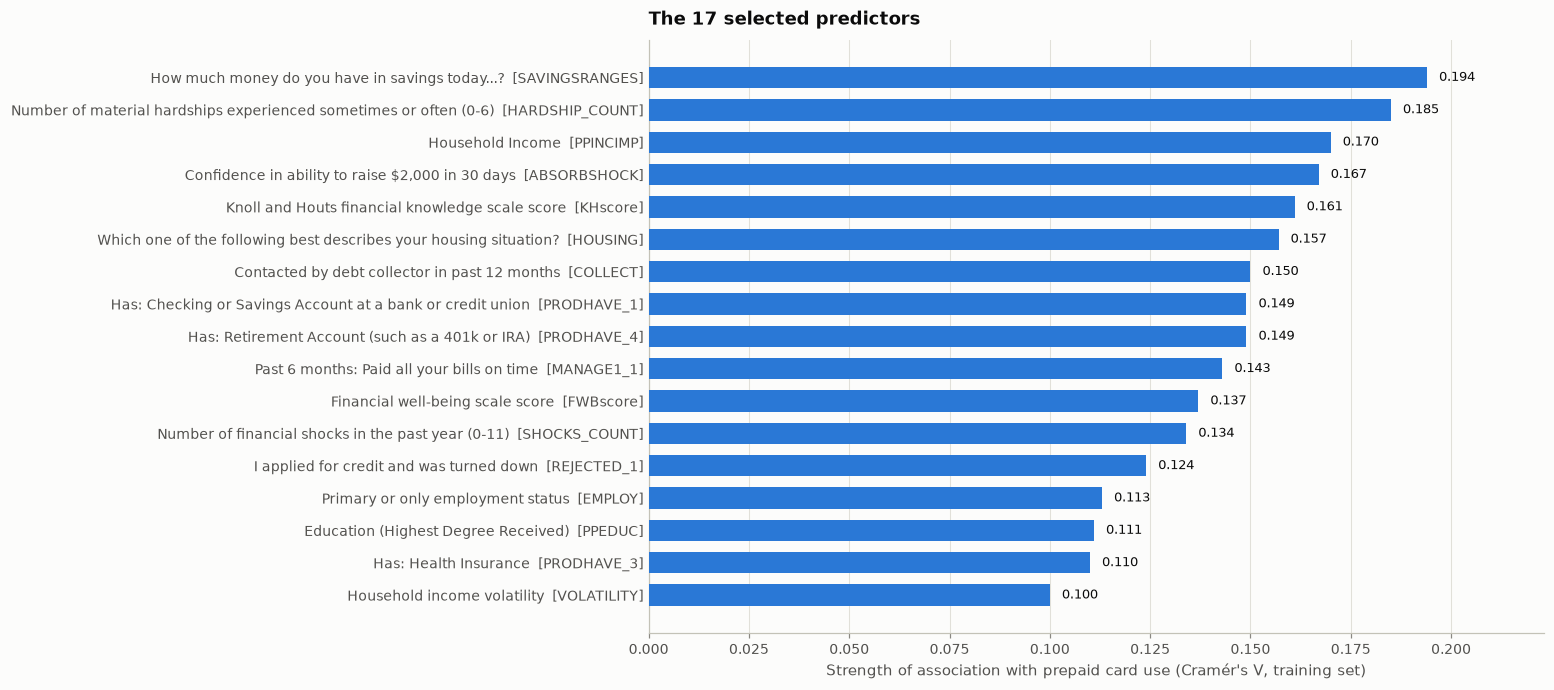

In [43]:
order = features.sort_values("cramers_v_train").index
fig, ax = plt.subplots(figsize=(10.5, 7))
ax.barh(np.arange(len(order)), features.loc[order, "cramers_v_train"], height=0.66, color=BLUE, zorder=3)
for i, col in enumerate(order):
    ax.text(features.loc[col, "cramers_v_train"] + 0.003, i, f"{features.loc[col, 'cramers_v_train']:.3f}", va="center", fontsize=8.5, color=INK)
ax.set_yticks(np.arange(len(order)), [f"{features.loc[c, 'label'][:66]}  [{c}]" for c in order])
ax.set_xlim(0, features["cramers_v_train"].max() * 1.15)
ax.set_xlabel("Strength of association with prepaid card use (Cramér's V, training set)")
ax.set_title(f"The {len(selected)} selected predictors")
ax.grid(axis="y", visible=False)
ax.tick_params(axis="y", length=0)
fig.savefig(FIG_DIR / "12_selected_predictors.png")
plt.show()

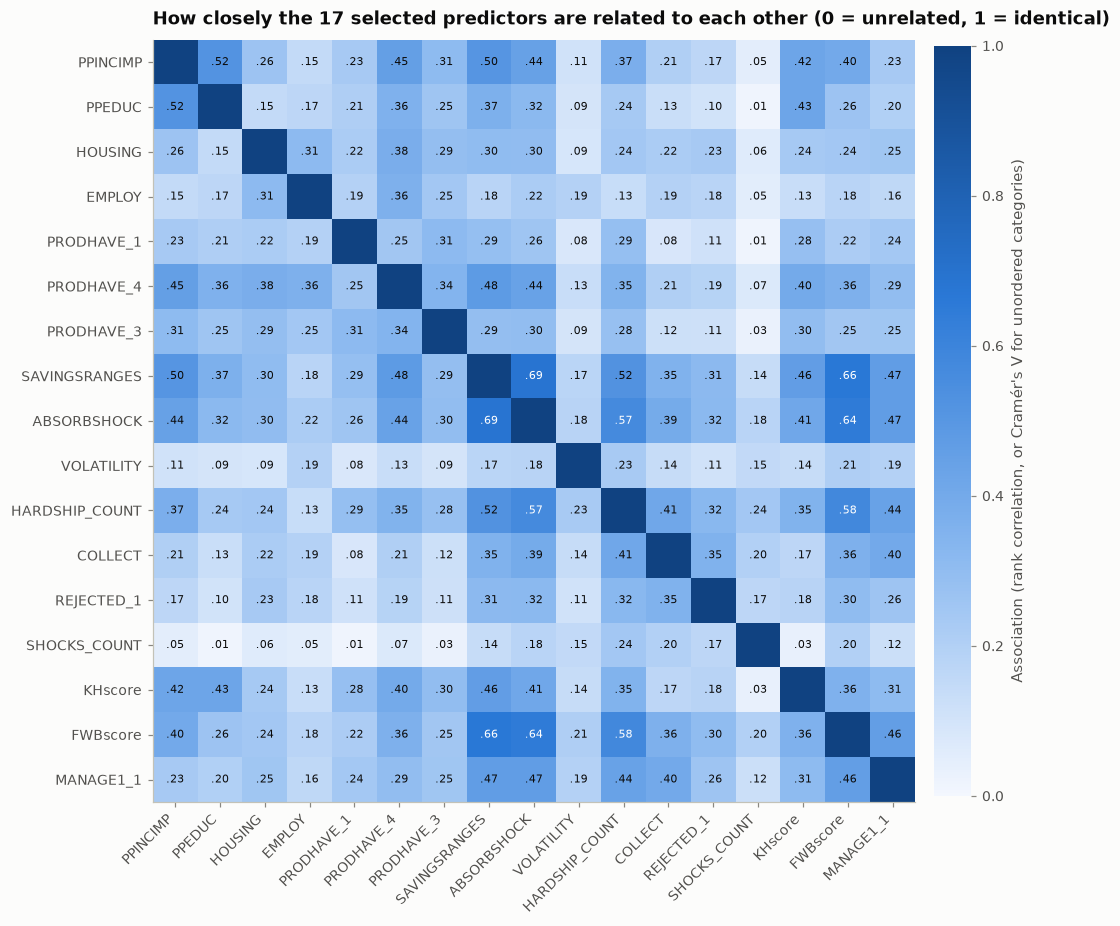

Median association between two selected predictors: 0.25
Pairs at or above the 0.60 redundancy limit: SAVINGSRANGES / ABSORBSHOCK (0.69), SAVINGSRANGES / FWBscore (0.66), ABSORBSHOCK / FWBscore (0.64)


In [44]:
assoc_matrix = pd.DataFrame([[1.0 if a == b else pair_association(a, b) for b in selected] for a in selected],
                            index=selected, columns=selected)
fig, ax = plt.subplots(figsize=(11, 9))
im = ax.imshow(assoc_matrix, cmap=SEQ_CMAP, vmin=0, vmax=1)
ax.set_xticks(range(len(selected)), selected, rotation=45, ha="right")
ax.set_yticks(range(len(selected)), selected)
for i in range(len(selected)):
    for j in range(len(selected)):
        if i != j:
            val = assoc_matrix.iloc[i, j]
            ax.text(j, i, f"{val:.2f}"[1:], ha="center", va="center", fontsize=7.5, color="white" if val > 0.55 else INK)
ax.grid(visible=False)
ax.set_title(f"How closely the {len(selected)} selected predictors are related to each other (0 = unrelated, 1 = identical)")
cbar = fig.colorbar(im, ax=ax, fraction=0.04, pad=0.02)
cbar.set_label("Association (rank correlation, or Cramér's V for unordered categories)")
cbar.outline.set_visible(False)
fig.savefig(FIG_DIR / "13_selected_predictor_overlap.png")
plt.show()

off_diag = assoc_matrix.where(~np.eye(len(selected), dtype=bool))
print(f"Median association between two selected predictors: {np.nanmedian(off_diag.to_numpy()):.2f}")
print(f"Pairs at or above the {REDUNDANCY_LIMIT:.2f} redundancy limit: "
      f"{', '.join(f'{a} / {b} ({assoc_matrix.loc[a, b]:.2f})' for i, a in enumerate(selected) for b in selected[i + 1:] if assoc_matrix.loc[a, b] >= REDUNDANCY_LIMIT)}")

**Takeaways**

- **Eleven of the 17 come straight from the statistical shortlist; six were added by judgement** (education, employment, health insurance, ability to raise \$2,000, income volatility, and the full well-being score).
- **Every major theme is represented:** four demographic and household variables, three banking and product variables, three liquidity variables, four strain variables, and one each for knowledge, well-being and behaviour.
- **The set is mostly non-overlapping.** The typical association between two selected predictors is 0.25.
- **One deliberate exception:** savings, ability to raise \$2,000 and the well-being score are related to each other at 0.64–0.69, above the 0.60 limit used for the shortlist. All three are kept because savings, the strongest variable, is unanswered by 18% of respondents, and the other two carry the same information for those people. When reading model coefficients, treat these three as one "liquidity" group.
- **Section 5 tests whether these judgement calls cost anything.**

---
## 5. Validation: does this set of 17 hold up?

A selection that mixes statistics with judgement should be tested. The check: fit the same simple model (a class-weighted logistic regression) on different sets of predictors and compare how well each ranks users above non-users.

- **Method:** 5-fold cross-validation **within the training set**. The test set is not touched.
- **Metrics:** ROC-AUC (0.5 = coin flip, 1.0 = perfect ranking) and PR-AUC (average precision; the baseline is the 8.8% usage rate). Both are suited to a rare outcome; accuracy is not.
- **This is not the final model.** It is a yardstick for comparing predictor sets. Model choice and tuning are Task B.

In [45]:
def make_preprocessor(cols):
    """Same preparation rules as the shared pipeline in prep.py, for any list of columns."""
    nominal = [c for c in cols if c in NOMINAL]
    binary = [c for c in cols if c not in NOMINAL and roles.loc[c, "measurement_type"] == "Binary"]
    scaled = [c for c in cols if c not in nominal and c not in binary]
    return ColumnTransformer([
        ("scaled", Pipeline([("impute", SimpleImputer(strategy="median")), ("scale", StandardScaler())]), scaled),
        ("binary", SimpleImputer(strategy="most_frequent"), binary),
        ("nominal", Pipeline([("impute", SimpleImputer(strategy="most_frequent")),
                              ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False))]), nominal),
    ], verbose_feature_names_out=False)


folds = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)


def cv_score(cols):
    model = make_pipeline(make_preprocessor(cols), LogisticRegression(max_iter=3000, class_weight="balanced"))
    res = cross_validate(model, train[cols], train[TARGET], cv=folds, scoring=["roc_auc", "average_precision"])
    return {"predictors": len(cols), "roc_auc": res["test_roc_auc"].mean(), "roc_auc_sd": res["test_roc_auc"].std(),
            "pr_auc": res["test_average_precision"].mean(), "pr_auc_sd": res["test_average_precision"].std()}


restricted = ["PRODUSE_1", "PRODUSE_2", "PRODUSE_4", "PRODUSE_5"]
predictor_sets = {
    "Final 17 (this notebook)": selected,
    "Statistical shortlist (Section 4.2)": shortlist,
    "Top 17 by screening rank, no redundancy control": screen.index[:17].tolist(),
    f"All {len(eligible)} eligible predictors": eligible,
    "Final 17 + race / ethnicity": selected + ["PPETHM"],
    "Final 17 + other non-bank products": selected + restricted,
}
comparison = pd.DataFrame({name: cv_score(cols) for name, cols in predictor_sets.items()}).T
comparison["predictors"] = comparison["predictors"].astype(int)
display(fmt(comparison, {"roc_auc": "{:.3f}", "roc_auc_sd": "{:.3f}", "pr_auc": "{:.3f}", "pr_auc_sd": "{:.3f}"}))

,predictors,roc_auc,roc_auc_sd,pr_auc,pr_auc_sd
Final 17 (this notebook),17,0.729,0.030,0.224,0.028
Statistical shortlist (Section 4.2),20,0.726,0.024,0.220,0.031
"Top 17 by screening rank, no redundancy control",17,0.720,0.033,0.218,0.038
All 173 eligible predictors,173,0.681,0.023,0.200,0.032
Final 17 + race / ethnicity,18,0.730,0.031,0.231,0.026
Final 17 + other non-bank products,21,0.729,0.029,0.218,0.023


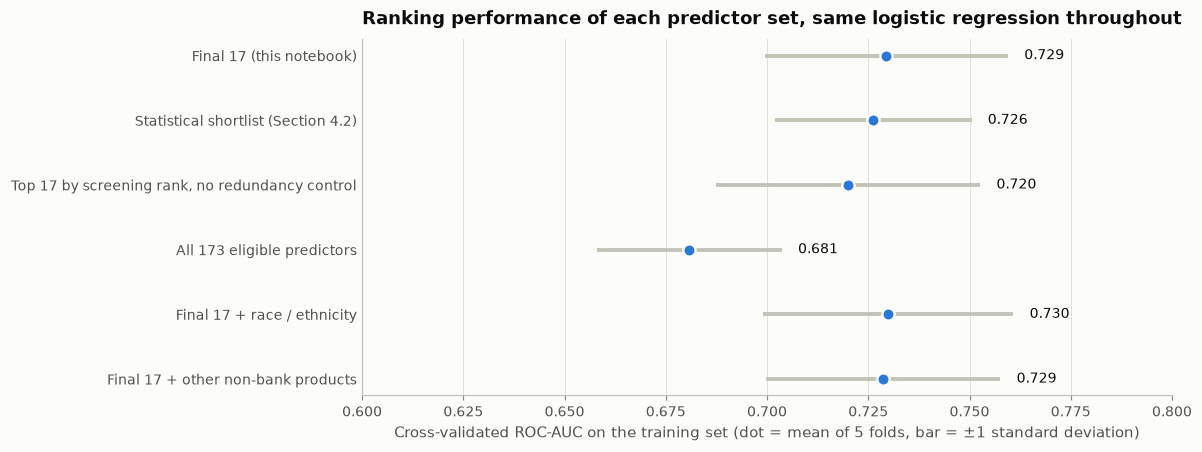

In [46]:
plot = comparison.iloc[::-1]
fig, ax = plt.subplots(figsize=(9.5, 4.2))
y = np.arange(len(plot))
ax.errorbar(plot["roc_auc"], y, xerr=plot["roc_auc_sd"], fmt="o", color=BLUE, ecolor=AXIS, elinewidth=2.5, markersize=8,
            markeredgecolor=SURFACE, markeredgewidth=1.5, zorder=3)
for yi, (m, sd) in enumerate(zip(plot["roc_auc"], plot["roc_auc_sd"])):
    ax.text(m + sd + 0.004, yi, f"{m:.3f}", va="center", fontsize=9, color=INK)
ax.set_yticks(y, plot.index)
ax.set_xlim(0.60, 0.80)
ax.set_xlabel("Cross-validated ROC-AUC on the training set (dot = mean of 5 folds, bar = ±1 standard deviation)")
ax.set_title("Ranking performance of each predictor set, same logistic regression throughout")
ax.grid(axis="y", visible=False)
ax.tick_params(axis="y", length=0)
fig.savefig(FIG_DIR / "14_predictor_set_validation.png")
plt.show()

In [47]:
# What does each predictor contribute on top of the other 19?
base_auc = comparison.loc["Final 17 (this notebook)", "roc_auc"]
drop_one = pd.Series({col: base_auc - cv_score([c for c in selected if c != col])["roc_auc"] for col in selected}, name="auc_lost_if_removed")
contribution = features[["label", "theme"]].join(drop_one).sort_values("auc_lost_if_removed", ascending=False)
display(fmt(contribution, {"auc_lost_if_removed": "{:+.4f}"}))
print(f"Fold-to-fold standard deviation of the ROC-AUC: {comparison.loc['Final 17 (this notebook)', 'roc_auc_sd']:.3f}")
print(f"Largest single-predictor contribution: {drop_one.max():.4f}")

,label,theme,auc_lost_if_removed
variable,,,
SHOCKS_COUNT,Number of financial shocks in the past year (0-11),"Financial strain, hardship and shocks",+0.0091
KHscore,Knoll and Houts financial knowledge scale score,Financial knowledge and numeracy (tested),+0.0057
HOUSING,Which one of the following best describes your housing situation?,"Housing, savings and household resources",+0.0045
PRODHAVE_1,Has: Checking or Savings Account at a bank or credit union,Financial products held,+0.0042
PPINCIMP,Household Income,Demographics and geography,+0.0034
VOLATILITY,Household income volatility,"Financial strain, hardship and shocks",+0.0014
COLLECT,Contacted by debt collector in past 12 months,"Financial strain, hardship and shocks",+0.0009
HARDSHIP_COUNT,Number of material hardships experienced sometimes or often (0-6),"Financial strain, hardship and shocks",+0.0003
MANAGE1_1,Past 6 months: Paid all your bills on time,Money management behaviour,+0.0001


Fold-to-fold standard deviation of the ROC-AUC: 0.030
Largest single-predictor contribution: 0.0091


**Takeaways**

- **The final 17 perform as well as any alternative.** ROC-AUC 0.729, against 0.726 for the 20-item statistical shortlist and 0.720 for the top 17 by rank. These differences are well inside the fold-to-fold variation (0.030), so the three sets are indistinguishable. Choosing for coverage and interpretability cost nothing.
- **More variables is worse, not better.** All 173 eligible predictors score 0.681. With only 448 users in the training set, a model given 173 inputs fits noise.
- **Leaving out race/ethnicity costs nothing measurable** (0.730 with it, 0.729 without). The other predictors already carry that information, which also means the model can still produce different outcomes by race; that should be checked in the CFPB analysis.
- **Leaving out the other non-bank products costs nothing either** (0.729 with them).
- **PR-AUC is 0.224 against a baseline of 0.088**, so the ranking is about 2.5 times better than random at finding users.
- **No single predictor is indispensable.** Removing any one changes the ROC-AUC by less than 0.01. The largest contributions come from the number of financial shocks, financial knowledge, housing and bank-account status. Employment and education add no ranking power on top of the others; they are kept because the card-company and CFPB answers need to describe segments in those terms.
- **Set expectations accordingly.** A ROC-AUC of about 0.73 is moderate. It reflects what Part 1 found: many weak, overlapping signals and no strong one.

---
## 6. Preparation pipeline

Models cannot use the data as it stands: there are missing values, two unordered categories stored as code numbers, and variables on very different scales. The brief also asks for standardisation where necessary.

| Variable type | Predictors | Preparation |
|---|---|---|
| Ordered scales, counts and scores | 10 | Fill missing values with the training median, then standardise to mean 0 and standard deviation 1 |
| Yes/no | 5 | Fill missing values with the most frequent answer; keep as 0/1 |
| Unordered categories | 2 (`HOUSING`, `EMPLOY`) | Fill missing values with the most frequent category, then one-hot encode (one 0/1 column per category) |

**Why standardise.** Logistic regression with a penalty, SVMs and neural networks are sensitive to scale: a 14–95 well-being score would otherwise outweigh a 1–3 scale. Tree-based models (Random Forest, XGBoost, AdaBoost) are unaffected, so one pipeline serves all the models.

**Why this is a pipeline and not a prepared file.** The medians, means and standard deviations must be learned from training data only. The pipeline is therefore saved as code (`prep.py`) and fitted inside each model, including inside every cross-validation fold. A pre-standardised CSV would have used the test rows to compute those numbers.

The pipeline lives in `prep.py` so that every notebook imports exactly the same steps.

In [48]:
features.to_csv(DATA_DIR / "selected_features.csv")

keep = selected + [TARGET] + PROFILE_COLUMNS + DESCRIBE_ONLY
train[keep].to_csv(DATA_DIR / "train.csv")
test[keep].to_csv(DATA_DIR / "test.csv")
print("Saved:", ", ".join(str((DATA_DIR / f).as_posix()) for f in ["selected_features.csv", "train.csv", "test.csv"]))

display(features[["label", "measurement_type", "pct_missing_train", "preparation"]])

Saved: data/selected_features.csv, data/train.csv, data/test.csv


,label,measurement_type,pct_missing_train,preparation
variable,,,,
PPINCIMP,Household Income,Ordinal (ordered scale or count),0.0,"Impute median, standardise"
PPEDUC,Education (Highest Degree Received),Ordinal (ordered scale or count),0.0,"Impute median, standardise"
HOUSING,Which one of the following best describes your housing situation?,Nominal (unordered categories),0.3,"Impute most frequent, one-hot encode"
EMPLOY,Primary or only employment status,Nominal (unordered categories),1.4,"Impute most frequent, one-hot encode"
PRODHAVE_1,Has: Checking or Savings Account at a bank or credit union,Binary,0.0,"Impute most frequent, keep as 0/1"
PRODHAVE_4,Has: Retirement Account (such as a 401k or IRA),Binary,0.0,"Impute most frequent, keep as 0/1"
PRODHAVE_3,Has: Health Insurance,Binary,0.0,"Impute most frequent, keep as 0/1"
SAVINGSRANGES,How much money do you have in savings today...?,Ordinal (ordered scale or count),18.2,"Impute median, standardise"
ABSORBSHOCK,"Confidence in ability to raise $2,000 in 30 days",Ordinal (ordered scale or count),5.3,"Impute median, standardise"


In [49]:
# Load everything back through the shared module, exactly as the modelling notebook will.
import importlib
import prep
importlib.reload(prep)

X_train, X_test, y_train, y_test = prep.load_split()
preprocessor = prep.build_preprocessor()
Xt_train = pd.DataFrame(preprocessor.fit_transform(X_train), index=X_train.index, columns=preprocessor.get_feature_names_out())
Xt_test = pd.DataFrame(preprocessor.transform(X_test), index=X_test.index, columns=preprocessor.get_feature_names_out())   # transform only: nothing is learned from the test set

scaled_cols, binary_cols, nominal_cols = prep.feature_lists()
print(f"Predictors in: {X_train.shape[1]}  ->  model columns out: {Xt_train.shape[1]} "
      f"({len(scaled_cols)} standardised, {len(binary_cols)} yes/no, {Xt_train.shape[1] - len(scaled_cols) - len(binary_cols)} one-hot from {len(nominal_cols)} categories)")
print(f"Training matrix: {Xt_train.shape} | Test matrix: {Xt_test.shape}")

pipeline_checks = {
    "Split reloaded from disk matches the split made in Section 3": bool(X_train.index.equals(train.index) and X_test.index.equals(test.index)),
    "Exactly the 17 selected predictors are loaded": list(X_train.columns) == selected,
    "No missing values remain after preparation (train and test)": bool(Xt_train.notna().all().all() and Xt_test.notna().all().all()),
    "Standardised columns have mean 0 on the training set": bool(np.allclose(Xt_train[scaled_cols].mean(), 0, atol=1e-9)),
    "Standardised columns have standard deviation 1 on the training set": bool(np.allclose(Xt_train[scaled_cols].std(ddof=0), 1, atol=1e-9)),
    "Yes/no columns contain only 0 and 1": bool(Xt_train[binary_cols].isin([0, 1]).all().all()),
    "Each one-hot group sums to exactly 1 per respondent": all(
        bool((Xt_train[[c for c in Xt_train.columns if c.startswith(n + "_")]].sum(axis=1) == 1).all()) for n in nominal_cols),
    "Outcome rate is the same in train and test (to 0.1 point)": abs(y_train.mean() - y_test.mean()) < 0.001,
    "No profiling column or outcome is among the predictors": not (set(prep.PROFILE_COLUMNS) | {TARGET}) & set(X_train.columns),
}
display(pd.DataFrame({"Check": list(pipeline_checks), "Result": ["PASS" if ok else "FAIL" for ok in pipeline_checks.values()]}))
assert all(pipeline_checks.values())

Predictors in: 17  ->  model columns out: 26 (10 standardised, 5 yes/no, 11 one-hot from 2 categories)
Training matrix: (5093, 26) | Test matrix: (1274, 26)


,Check,Result
0,Split reloaded from disk matches the split made in Section 3,PASS
1,Exactly the 17 selected predictors are loaded,PASS
2,No missing values remain after preparation (train and test),PASS
3,Standardised columns have mean 0 on the training set,PASS
4,Standardised columns have standard deviation 1 on the training set,PASS
5,Yes/no columns contain only 0 and 1,PASS
6,Each one-hot group sums to exactly 1 per respondent,PASS
7,Outcome rate is the same in train and test (to 0.1 point),PASS
8,No profiling column or outcome is among the predictors,PASS


In [50]:
print("Model columns after preparation:")
display(pd.DataFrame({"model column": Xt_train.columns,
                      "meaning": prep.readable_names(preprocessor),
                      "train mean": Xt_train.mean().round(3).to_numpy(),
                      "train sd": Xt_train.std(ddof=0).round(3).to_numpy(),
                      "test mean": Xt_test.mean().round(3).to_numpy()}))
drift = (Xt_test[scaled_cols].mean()).abs().max()
print(f"Largest gap between test and training means on a standardised column: {drift:.2f} standard deviations")

Model columns after preparation:


,model column,meaning,train mean,train sd,test mean
0,PPINCIMP,Household Income,-0.000,1.000,-0.021
1,PPEDUC,Education (Highest Degree Received),0.000,1.000,0.005
2,SAVINGSRANGES,How much money do you have in savings today...?,0.000,1.000,0.002
3,ABSORBSHOCK,"Confidence in ability to raise $2,000 in 30 days",-0.000,1.000,0.010
4,VOLATILITY,Household income volatility,0.000,1.000,-0.034
5,HARDSHIP_COUNT,Number of material hardships experienced sometimes or often (0-6),-0.000,1.000,0.009
6,SHOCKS_COUNT,Number of financial shocks in the past year (0-11),-0.000,1.000,0.013
7,KHscore,Knoll and Houts financial knowledge scale score,-0.000,1.000,-0.004
8,FWBscore,Financial well-being scale score,0.000,1.000,-0.033
9,MANAGE1_1,Past 6 months: Paid all your bills on time,-0.000,1.000,0.038


Largest gap between test and training means on a standardised column: 0.04 standard deviations


**Result.** The pipeline turns the 17 predictors into 26 model columns (10 standardised, 5 yes/no, 11 one-hot) with no missing values. All nine checks pass. Test-set means sit within 0.04 standard deviations of the training means on every standardised column, which confirms the two parts are alike and that the test set was only transformed, never used to fit.

---
## 7. Hand-off

#### Files produced

| File | Contents |
|---|---|
| `data/train.csv` | 5,093 training respondents: 17 predictors, the outcome, 6 profiling columns, and 3 describe-only columns (age, marital status, SNAP) |
| `data/test.csv` | 1,274 test respondents, same columns. **Do not use until final evaluation** |
| `data/selected_features.csv` | The 17 predictors: label, theme, preparation rule, and reason for selection |
| `prep.py` | `load_split()`, `build_preprocessor()`, `load_profile()`, `readable_names()` |
| `figures/12–14` | Charts from this part |

#### How Task B (models) starts

```python
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from prep import load_split, build_preprocessor

X_train, X_test, y_train, y_test = load_split()
model = make_pipeline(build_preprocessor(), LogisticRegression(max_iter=3000, class_weight="balanced"))
model.fit(X_train, y_train)
```

#### Rules for everyone downstream

1. **Use `load_split()`.** Do not re-split or re-clean the data.
2. **Keep the preprocessor inside the model pipeline**, so it is re-fitted in every cross-validation fold.
3. **Tune on the training set by cross-validation. Touch the test set once, at the end**, to report the final numbers.
4. **Handle the 1-to-10 class imbalance** (class weights or equivalent) and report recall, precision, PR-AUC, ROC-AUC and lift. Accuracy alone is misleading.
5. **Profiling columns are for describing groups, never for predicting.** `load_profile()` returns race/ethnicity, sample type and the other non-bank products for the card-company and CFPB analyses. Age (`agecat`), marital status (`PPMARIT`) and SNAP are also in `train.csv` and `test.csv` for the same purpose only.
6. For any other survey variable, join `data/cfpb_clean.csv` to the split on `PUF_ID`.

#### Notes for the next tasks

- **Task B (models):** the logistic regression in Section 5 is a yardstick, not the final model. It gives a floor to beat: cross-validated ROC-AUC 0.729 and PR-AUC 0.224.
- **Task C (card company):** `data/selected_features.csv` has a column, `available_to_card_company`, marking which predictors a company could realistically know about a prospect and which exist only in a survey. It is the team's judgement and should be reviewed, but it matters: a targeting strategy can only use what is observable.
- **Task D (CFPB):** race/ethnicity is not in the model but is available through `load_profile()` for describing at-risk groups and for checking whether the model's scores differ by group.

# Part 3: Models and evaluation

*Lead: Jairaj Narang.*

**Purpose.** Build three predictive models of prepaid card use (`PRODUSE_3`), compare them fairly, choose one, and hand its scores to the card-company (Task C) and CFPB (Task D) analyses.

| Section | What it delivers |
|---|---|
| 1. Setup | The shared split and 17 predictors, loaded through `prep.py` |
| 2. Three models | Logistic regression, random forest and XGBoost, each as a pipeline with the shared preparation step |
| 3. Tuning | A hyperparameter search per model, by cross-validation on the training set |
| 4. Comparison | All three models on the same five folds: ROC-AUC, PR-AUC, recall and precision at the top 20% |
| 5. Choice | The chosen model and why |
| 6. Threshold | The recall–precision trade-off and a recommended "top X%" rule |
| 7. Test-set evaluation | The one and only use of the test set: final numbers, confusion matrix, curves and lift |
| 8. Honest reading | What the model can and cannot do |
| 9. Hand-off | Saved scores and model for Tasks C and D |

### Summary

- **The three models are statistically tied.** Cross-validated PR-AUC is 0.225 (logistic regression), 0.228 (random forest) and 0.233 (XGBoost); ROC-AUC is 0.730, 0.723 and 0.723. Every gap is smaller than the fold-to-fold spread (0.028–0.049), and XGBoost beats logistic regression on PR-AUC in only 3 of the 5 folds.
- **Chosen model: logistic regression.** With no real difference in accuracy, the deciding factors are stability (it has the smallest fold-to-fold spread) and interpretability (one readable weight per predictor, which Tasks C and D need to explain who scores high and why).
- **Tuning added almost nothing,** for any model. The best settings beat Task A's untuned baseline (ROC-AUC 0.729, PR-AUC 0.224) by at most 0.009 in PR-AUC. This confirms Task A's finding: the signal is many weak, overlapping predictors, and a more flexible model cannot find much more.
- **Recommended rule: flag the top 20% of scores** (score of 0.602 or more). On the test set this flags 19.3% of people, catches **53.6% of all prepaid users**, and 24.4% of those flagged are users: **2.77 times** the 8.8% average.
- **Test-set results agree with cross-validation:** ROC-AUC 0.746 and PR-AUC 0.247 for the chosen model. The top 10% of scores contains 31.2% of all users; the top 30% contains 63.4%.
- **Performance is moderate, and that is the honest answer.** The model is good at sorting a population into a high-use group and a low-use group; it is not able to say with confidence whether a particular person uses a prepaid card. Three in four people it flags are not users.

---
## 1. Setup

Data comes through the shared module `prep.py`, exactly as Task A left it: the same 5,093 training and 1,274 test respondents, and the same 17 predictors. Nothing is re-split, re-cleaned or re-selected here.

**The test set is not touched until Section 7.** Every choice before that (settings, model, threshold) is made by cross-validation on the training set.

In [51]:
from pathlib import Path
import warnings

import joblib
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from IPython.display import display

from sklearn.base import clone
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score, confusion_matrix, precision_recall_curve, roc_auc_score, roc_curve
from sklearn.model_selection import GridSearchCV, StratifiedKFold, cross_val_predict
from sklearn.pipeline import Pipeline
import sklearn
import xgboost
from xgboost import XGBClassifier

import prep
from prep import build_preprocessor, load_split

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_columns", 60, "display.width", 220, "display.max_colwidth", 110, "display.max_rows", 100)

DATA_DIR = Path("data")
FIG_DIR = Path("figures")
MODEL_DIR = Path("models")
MODEL_DIR.mkdir(exist_ok=True)
SEED = 42

# Baseline to beat, from Part 2, Section 5 (class-weighted logistic regression, default settings)
BASELINE_ROC_AUC, BASELINE_PR_AUC = 0.729, 0.224   # Task A, Section 5

INK, INK2, MUTED = "#0b0b0b", "#52514e", "#898781"
GRID, AXIS, SURFACE = "#e1e0d9", "#c3c2b7", "#fcfcfb"
BLUE, ORANGE = "#2a78d6", "#eb6834"
mpl.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "figure.dpi": 110, "savefig.dpi": 200, "savefig.bbox": "tight",
    "font.size": 10, "text.color": INK, "axes.labelcolor": INK2,
    "axes.titlesize": 11.5, "axes.titleweight": "bold", "axes.titlelocation": "left", "axes.titlepad": 10,
    "axes.edgecolor": AXIS, "axes.linewidth": 0.8, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "axes.axisbelow": True, "grid.color": GRID, "grid.linewidth": 0.7,
    "xtick.color": MUTED, "ytick.color": MUTED, "xtick.labelcolor": INK2, "ytick.labelcolor": INK2,
    "xtick.labelsize": 9, "ytick.labelsize": 9, "legend.frameon": False, "legend.fontsize": 9,
})
MODEL_COLOURS = {"Logistic regression": BLUE, "Random forest": "#1f9e74", "XGBoost": ORANGE}


def fmt(df, formats, hide_index=False):
    """Return a display copy of a table with numbers formatted as text."""
    out = df.copy()
    if isinstance(formats, str):
        formats = {c: formats for c in out.columns if pd.api.types.is_numeric_dtype(out[c])}
    for col, pattern in formats.items():
        if col in out.columns:
            out[col] = out[col].map(lambda v, p=pattern: p.format(v) if pd.notna(v) else "")
    return out.reset_index(drop=True) if hide_index else out


X_train, X_test, y_train, y_test = load_split()
base_rate = y_train.mean()
print(f"scikit-learn {sklearn.__version__}, XGBoost {xgboost.__version__}")
print(f"Training set: {X_train.shape[0]:,} respondents x {X_train.shape[1]} predictors, {int(y_train.sum())} prepaid users ({base_rate:.1%})")
print(f"Test set:     {X_test.shape[0]:,} respondents, {int(y_test.sum())} prepaid users ({y_test.mean():.1%}) -- not used until Section 7")
print(f"Baseline to beat (cross-validated): ROC-AUC {BASELINE_ROC_AUC:.3f}, PR-AUC {BASELINE_PR_AUC:.3f}")

scikit-learn 1.9.1, XGBoost 3.4.1
Training set: 5,093 respondents x 17 predictors, 448 prepaid users (8.8%)
Test set:     1,274 respondents, 112 prepaid users (8.8%) -- not used until Section 7
Baseline to beat (cross-validated): ROC-AUC 0.729, PR-AUC 0.224


**Result.** 5,093 training respondents (448 prepaid users) and 1,274 test respondents (112 users), both 8.8%. The baseline to beat is Task A's untuned, class-weighted logistic regression: cross-validated **ROC-AUC 0.729** and **PR-AUC 0.224**.

---
## 2. Three models

The brief allows six model types. Three are used, chosen to span the range from simplest to most flexible:

| Model | How it works, in one line | Why it is here | How it handles the 1-to-10 imbalance |
|---|---|---|---|
| **Logistic regression** | Adds up a weight for each predictor and turns the total into a score | Simplest; each weight can be read and explained | `class_weight="balanced"`: each user counts as much as about 10 non-users |
| **Random forest** | Averages hundreds of decision trees, each grown on a random sample of people and predictors | Captures interactions (for example, age mattering only at low incomes) without being told | `class_weight="balanced_subsample"`: the same reweighting, inside each tree's sample |
| **XGBoost** | Builds small trees one after another, each correcting the mistakes of those before it | Usually the strongest model on tabular data | `scale_pos_weight` = ratio of non-users to users |

Every model is a **pipeline**: `build_preprocessor()` (fill gaps, one-hot encode, standardise) followed by the model. The preparation step is therefore re-learned from the training folds inside every cross-validation split, so nothing about the held-out fold leaks in.

**Settings searched.** Each model gets a modest grid of the settings that matter most for it:
- Logistic regression: `C`, the strength of the penalty that shrinks weights (small `C` = stronger shrinking, a simpler model).
- Random forest: tree depth, minimum people per leaf, and how many predictors each split may consider. Smaller trees and bigger leaves guard against fitting noise.
- XGBoost: tree depth, learning rate (how big a step each new tree takes) and minimum leaf weight. The number of trees is fixed at 300.

In [52]:
folds = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
fold_list = list(folds.split(X_train, y_train))     # the same five folds for every model, so comparisons are paired
neg_to_pos = (y_train == 0).sum() / (y_train == 1).sum()

MODELS = {
    "Logistic regression": dict(
        key="logit",
        estimator=LogisticRegression(class_weight="balanced", max_iter=5000, random_state=SEED),
        grid={"model__C": [0.001, 0.003, 0.01, 0.03, 0.1, 0.3, 1, 3, 10]},
    ),
    "Random forest": dict(
        key="rf",
        estimator=RandomForestClassifier(n_estimators=300, class_weight="balanced_subsample", n_jobs=-1, random_state=SEED),
        grid={"model__max_depth": [4, 8, None], "model__min_samples_leaf": [10, 25, 50], "model__max_features": ["sqrt", 0.5]},
    ),
    "XGBoost": dict(
        key="xgb",
        estimator=XGBClassifier(n_estimators=300, scale_pos_weight=neg_to_pos, subsample=0.8, colsample_bytree=0.8,
                                eval_metric="logloss", n_jobs=-1, random_state=SEED),
        grid={"model__max_depth": [1, 2, 3, 4], "model__learning_rate": [0.01, 0.02, 0.05, 0.1], "model__min_child_weight": [1, 10]},
    ),
}
for spec in MODELS.values():
    spec["pipeline"] = Pipeline([("prep", build_preprocessor()), ("model", spec["estimator"])])

grid_table = pd.DataFrame([{"Model": name, "Setting": p.replace("model__", ""), "Values tried": ", ".join(map(str, v))}
                           for name, spec in MODELS.items() for p, v in spec["grid"].items()])
grid_table["Combinations for this model"] = grid_table["Model"].map({n: int(np.prod([len(v) for v in s["grid"].values()])) for n, s in MODELS.items()})
print(f"Class imbalance: {neg_to_pos:.1f} non-users for every user. XGBoost's scale_pos_weight is set to this ratio.")
display(grid_table)

Class imbalance: 10.4 non-users for every user. XGBoost's scale_pos_weight is set to this ratio.


,Model,Setting,Values tried,Combinations for this model
0,Logistic regression,C,"0.001, 0.003, 0.01, 0.03, 0.1, 0.3, 1, 3, 10",9
1,Random forest,max_depth,"4, 8, None",18
2,Random forest,min_samples_leaf,"10, 25, 50",18
3,Random forest,max_features,"sqrt, 0.5",18
4,XGBoost,max_depth,"1, 2, 3, 4",32
5,XGBoost,learning_rate,"0.01, 0.02, 0.05, 0.1",32
6,XGBoost,min_child_weight,"1, 10",32


---
## 3. Tuning

Every setting in the grid is scored by 5-fold cross-validation on the training set (`StratifiedKFold(5, shuffle=True, random_state=42)`): the model is fitted on four-fifths of the training respondents and scored on the remaining fifth, five times over. All three models use **the same five folds**.

Two measures are used throughout. Both judge how well a model **ranks** people, which is what a marketer or a regulator needs: who is most likely to use a prepaid card.

- **PR-AUC** (average precision): how precise the model is, averaged over every possible cut-off. A random ranking scores the base rate, **0.088**; a perfect one scores 1.0. It focuses on the users, the rare group that matters, so it is the measure the search optimises.
- **ROC-AUC**: the chance that a randomly picked user gets a higher score than a randomly picked non-user. 0.5 is a coin flip; 1.0 is perfect.

The **fold-to-fold standard deviation** (sd) shows how much a score moves just from which people land in which fold. Differences smaller than this are noise.

In [53]:
search_results, best_rows = {}, []
for name, spec in MODELS.items():
    search = GridSearchCV(spec["pipeline"], spec["grid"], cv=fold_list, refit="pr_auc", n_jobs=1,
                          scoring={"pr_auc": "average_precision", "roc_auc": "roc_auc"})
    search.fit(X_train, y_train)
    spec["search"], spec["best"] = search, search.best_estimator_
    res = pd.DataFrame(search.cv_results_)
    search_results[name] = res
    b = search.best_index_
    best_rows.append({"Model": name,
                      "Best settings": ", ".join(f"{k.replace('model__', '')}={v}" for k, v in search.best_params_.items()),
                      "PR-AUC": res.loc[b, "mean_test_pr_auc"], "PR-AUC sd": res.loc[b, "std_test_pr_auc"],
                      "ROC-AUC": res.loc[b, "mean_test_roc_auc"], "ROC-AUC sd": res.loc[b, "std_test_roc_auc"],
                      "Worst setting PR-AUC": res["mean_test_pr_auc"].min()})
best_table = pd.DataFrame(best_rows).set_index("Model")
print("Best setting per model (mean of 5 folds; sd = fold-to-fold standard deviation):")
display(fmt(best_table, "{:.3f}"))

Best setting per model (mean of 5 folds; sd = fold-to-fold standard deviation):


,Best settings,PR-AUC,PR-AUC sd,ROC-AUC,ROC-AUC sd,Worst setting PR-AUC
Model,,,,,,
Logistic regression,C=0.3,0.225,0.028,0.730,0.030,0.214
Random forest,"max_depth=None, max_features=sqrt, min_samples_leaf=10",0.228,0.049,0.723,0.044,0.219
XGBoost,"learning_rate=0.01, max_depth=2, min_child_weight=10",0.233,0.046,0.723,0.037,0.190


In [54]:
for name, res in search_results.items():
    params = [c for c in res.columns if c.startswith("param_")]
    top = res.sort_values("rank_test_pr_auc").head(5)[params + ["mean_test_pr_auc", "std_test_pr_auc", "mean_test_roc_auc"]]
    top.columns = [c.replace("param_model__", "") for c in params] + ["PR-AUC", "PR-AUC sd", "ROC-AUC"]
    print(f"{name}: five best of {len(res)} settings")
    display(fmt(top, {"PR-AUC": "{:.3f}", "PR-AUC sd": "{:.3f}", "ROC-AUC": "{:.3f}"}, hide_index=True))

Logistic regression: five best of 9 settings


,C,PR-AUC,PR-AUC sd,ROC-AUC
0,0.3,0.225,0.028,0.730
1,3.0,0.224,0.028,0.729
2,1.0,0.224,0.028,0.729
3,10.0,0.224,0.028,0.729
4,0.1,0.224,0.028,0.731


Random forest: five best of 18 settings


,max_depth,max_features,min_samples_leaf,PR-AUC,PR-AUC sd,ROC-AUC
0,None,sqrt,10,0.228,0.049,0.723
1,None,sqrt,25,0.227,0.046,0.725
2,None,sqrt,50,0.227,0.045,0.724
3,8,sqrt,50,0.226,0.046,0.724
4,8,sqrt,10,0.226,0.046,0.722


XGBoost: five best of 32 settings


,learning_rate,max_depth,min_child_weight,PR-AUC,PR-AUC sd,ROC-AUC
0,0.01,2,10,0.233,0.046,0.723
1,0.05,1,10,0.232,0.036,0.723
2,0.01,2,1,0.232,0.047,0.723
3,0.02,2,1,0.232,0.037,0.722
4,0.05,1,1,0.232,0.034,0.722


**Takeaways**

- **Logistic regression:** best `C` = 0.3, PR-AUC **0.225 ± 0.028**, ROC-AUC **0.730 ± 0.030**. Every `C` from 0.1 to 10 gives 0.224 or 0.225, so the penalty barely matters: the result is flat across the grid. Tuning leaves the model where Task A's baseline already was.
- **Random forest:** best is full-depth trees with at least 10 people per leaf and `sqrt` predictors per split. PR-AUC **0.228 ± 0.049**, ROC-AUC **0.723 ± 0.044**.
- **XGBoost:** best is very shallow trees (depth 2) with a slow learning rate (0.01). PR-AUC **0.233 ± 0.046**, ROC-AUC **0.723 ± 0.037**. Its five best settings all use trees of depth 1 or 2, which means XGBoost finds little in the way of interactions between predictors: a near-additive model, like a logistic regression, does nearly as well.
- **Settings matter less than the noise.** The spread from best to worst setting is 0.011 in PR-AUC for logistic regression and 0.009 for the random forest, well below the fold-to-fold sd. Only XGBoost has settings that clearly hurt (worst 0.190, from deep trees learning fast, which fit noise).

---
## 4. Comparison on cross-validation

The tuned version of each model is compared on the same five folds. Besides the two ranking measures, the table shows what happens at a **stated threshold**: flag the **top 20%** of scores in each fold.

- **Recall:** of all prepaid users, the share the model flags. "How many of the users do we reach?"
- **Precision:** of the people flagged, the share who are users. "How many of the people we reach are users?"

A share-based threshold ("top 20%") is used instead of a fixed score such as 0.5, because class-weighted models produce scores that are inflated and not comparable across models (Section 6 explains). Flagging the same share of people puts all three models on equal terms.

The scores below are **out-of-fold**: every training respondent is scored by the one model, of the five, that did not see them during fitting.

In [55]:
TOP_SHARE = 0.20      # the stated threshold for comparison: flag the 20% of people with the highest scores


def top_share_metrics(y, score, share=TOP_SHARE):
    """Recall and precision when the top `share` of scores are flagged."""
    y, score = np.asarray(y), np.asarray(score)
    cutoff = np.quantile(score, 1 - share)
    flagged = score >= cutoff
    hits = (flagged & (y == 1)).sum()
    return {"recall": hits / (y == 1).sum(), "precision": hits / flagged.sum()}


oof = {}
for name, spec in MODELS.items():
    # Out-of-fold scores: every training respondent is scored by a model that never saw them
    oof[name] = cross_val_predict(clone(spec["best"]), X_train, y_train, cv=fold_list, method="predict_proba")[:, 1]

per_fold = []
for name in MODELS:
    for f, (_, val) in enumerate(fold_list):
        y_val, s_val = y_train.iloc[val], oof[name][val]
        per_fold.append({"Model": name, "fold": f + 1, "ROC-AUC": roc_auc_score(y_val, s_val),
                         "PR-AUC": average_precision_score(y_val, s_val), **{
                         f"{k.capitalize()} at top 20%": v for k, v in top_share_metrics(y_val, s_val).items()}})
per_fold = pd.DataFrame(per_fold)
METRICS = ["ROC-AUC", "PR-AUC", "Recall at top 20%", "Precision at top 20%"]
grouped = per_fold.groupby("Model", sort=False)[METRICS]
means, sds = grouped.mean(), grouped.std(ddof=0)      # ddof=0 matches the sd reported by GridSearchCV in Section 3
cv_compare = pd.concat([means, sds.add_suffix(" sd")], axis=1)[[c for m in METRICS for c in (m, f"{m} sd")]]
cv_compare.loc["Baseline (Task A logistic regression)", ["ROC-AUC", "PR-AUC"]] = [BASELINE_ROC_AUC, BASELINE_PR_AUC]
print("Cross-validated comparison on the training set (mean and fold-to-fold sd over the same 5 folds):")
display(fmt(cv_compare, "{:.3f}"))

Cross-validated comparison on the training set (mean and fold-to-fold sd over the same 5 folds):


,ROC-AUC,ROC-AUC sd,PR-AUC,PR-AUC sd,Recall at top 20%,Recall at top 20% sd,Precision at top 20%,Precision at top 20% sd
Model,,,,,,,,
Logistic regression,0.730,0.030,0.225,0.028,0.484,0.051,0.213,0.022
Random forest,0.723,0.044,0.228,0.049,0.482,0.052,0.212,0.023
XGBoost,0.723,0.037,0.233,0.046,0.498,0.065,0.219,0.029
Baseline (Task A logistic regression),0.729,,0.224,,,,,


In [56]:
# Paired differences: same folds, so subtract fold by fold. A difference is only meaningful if it is large relative to its own spread.
wide = per_fold.pivot(index="fold", columns="Model")
pairs = [("XGBoost", "Logistic regression"), ("Random forest", "Logistic regression"), ("XGBoost", "Random forest")]
paired = []
for a, b in pairs:
    for m in ["ROC-AUC", "PR-AUC"]:
        d = wide[(m, a)] - wide[(m, b)]
        paired.append({"Comparison": f"{a} minus {b}", "Metric": m, "Mean difference": d.mean(), "sd of difference": d.std(ddof=0),
                       "Folds where first is better": f"{int((d > 0).sum())} of 5",
                       "Difference / sd": d.mean() / d.std(ddof=0)})
paired = pd.DataFrame(paired)
display(fmt(paired, {"Mean difference": "{:+.3f}", "sd of difference": "{:.3f}", "Difference / sd": "{:+.2f}"}, hide_index=True))

,Comparison,Metric,Mean difference,sd of difference,Folds where first is better,Difference / sd
0,XGBoost minus Logistic regression,ROC-AUC,-0.007,0.007,1 of 5,-0.93
1,XGBoost minus Logistic regression,PR-AUC,+0.009,0.024,3 of 5,+0.37
2,Random forest minus Logistic regression,ROC-AUC,-0.007,0.019,3 of 5,-0.37
3,Random forest minus Logistic regression,PR-AUC,+0.003,0.023,1 of 5,+0.13
4,XGBoost minus Random forest,ROC-AUC,+0.000,0.014,2 of 5,+0.02
5,XGBoost minus Random forest,PR-AUC,+0.006,0.012,3 of 5,+0.50


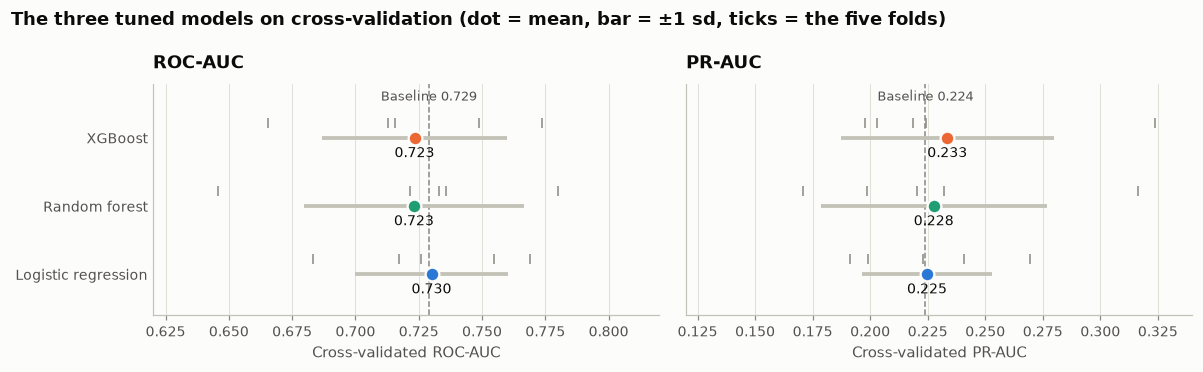

In [57]:
names = list(MODELS)
fig, axes = plt.subplots(1, 2, figsize=(11, 3.4), sharey=True)
for ax, metric, baseline, xlim in [(axes[0], "ROC-AUC", BASELINE_ROC_AUC, (0.62, 0.82)), (axes[1], "PR-AUC", BASELINE_PR_AUC, (0.12, 0.34))]:
    for i, name in enumerate(names):
        m, sd = cv_compare.loc[name, metric], cv_compare.loc[name, f"{metric} sd"]
        ax.errorbar(m, i, xerr=sd, fmt="o", color=MODEL_COLOURS[name], ecolor=AXIS, elinewidth=2.5, markersize=9,
                    markeredgecolor=SURFACE, markeredgewidth=1.5, zorder=3)
        ax.text(m, i - 0.28, f"{m:.3f}", ha="center", fontsize=9, color=INK)
        for f in range(5):
            ax.plot(wide.loc[f + 1, (metric, name)], i + 0.22, "|", color=MUTED, markersize=7)
    ax.axvline(baseline, color=MUTED, linestyle="--", linewidth=1)
    ax.text(baseline, len(names) - 0.45, f"Baseline {baseline:.3f}", fontsize=8.5, color=INK2, ha="center")
    ax.set_xlim(*xlim)
    ax.set_xlabel(f"Cross-validated {metric}")
    ax.set_title(metric)
    ax.grid(axis="y", visible=False)
    ax.tick_params(axis="y", length=0)
axes[0].set_yticks(range(len(names)), names)
axes[0].set_ylim(-0.6, len(names) - 0.2)
fig.suptitle("The three tuned models on cross-validation (dot = mean, bar = ±1 sd, ticks = the five folds)", x=0.01, ha="left", fontweight="bold")
fig.tight_layout()
fig.savefig(FIG_DIR / "15_cv_model_comparison.png")
plt.show()

**Takeaways**

- **The three models are tied.** XGBoost has the highest PR-AUC (0.233) and logistic regression the highest ROC-AUC (0.730). XGBoost's PR-AUC lead over logistic regression is +0.009, with a fold-by-fold spread of 0.024 (ratio +0.37), and it is ahead in only 3 of 5 folds; on ROC-AUC it is behind by 0.007. No pair of models differs by more than 0.93 times the spread of its difference.
- **The same holds at the top-20% threshold.** Recall is 48.4% (logistic regression), 48.2% (random forest) and 49.8% (XGBoost); precision is 21.3%, 21.2% and 21.9%. In practice, all three would flag nearly the same people.
- **Logistic regression is the most stable.** Its fold-to-fold sd is the smallest on every measure (0.030 ROC-AUC, 0.028 PR-AUC, against 0.037–0.049 for the tree models).
- **None clearly beats the baseline** (0.729 / 0.224). The ceiling is set by the information in the 17 predictors, not by the choice of algorithm.

---
## 5. Choosing one model

The model has to do three things for this project: rank people as well as the alternatives, give stable results, and be explainable to the card company and to the CFPB (Tasks C and D must say *why* someone scores high).

In [58]:
CHOSEN = "Logistic regression"
chosen_spec = MODELS[CHOSEN]
chosen_model = chosen_spec["best"]
coef = pd.Series(chosen_model.named_steps["model"].coef_[0], index=prep.readable_names(chosen_model.named_steps["prep"]))
print(f"Chosen model: {CHOSEN} ({best_table.loc[CHOSEN, 'Best settings']})")
print(f"Model columns: {len(coef)}, of which {int((coef.abs() > 1e-6).sum())} have a non-zero weight")
print("Largest weights (on the standardised scale; positive = higher score). Full interpretation is Task C:")
display(fmt(coef.reindex(coef.abs().sort_values(ascending=False).index).head(8).rename("weight").to_frame(), "{:+.2f}"))

Chosen model: Logistic regression (C=0.3)
Model columns: 26, of which 26 have a non-zero weight
Largest weights (on the standardised scale; positive = higher score). Full interpretation is Task C:


,weight
Has: Checking or Savings Account at a bank or credit union,-0.55
Primary or only employment status: Homemaker,-0.40
Contacted by debt collector in past 12 months,+0.38
Primary or only employment status: Full-time student,-0.32
"Primary or only employment status: Sick, disabled or unable to work",+0.30
Primary or only employment status: Retired,+0.27
Which one of the following best describes your housing situation?: Owns home,-0.26
I applied for credit and was turned down,+0.26


**Decision: logistic regression (`C` = 0.3, class-weighted).**

| Criterion | Logistic regression | Random forest | XGBoost |
|---|---|---|---|
| Ranking performance (cross-validated PR-AUC) | 0.225 | 0.228 | 0.233 |
| Better than logistic regression beyond the noise? | — | No (+0.003, ahead in 1 of 5 folds) | No (+0.009, ahead in 3 of 5 folds) |
| Stability (fold-to-fold sd of PR-AUC) | **0.028, smallest** | 0.049 | 0.046 |
| Interpretability | **One weight per predictor, with a direction** | 300 deep trees; needs permutation importance | 300 small trees; needs permutation importance |

**Why.**
1. **Performance is tied** (Section 4). When models are statistically indistinguishable, the brief's rule is to prefer the more interpretable one.
2. **It is the most stable.** Its scores move least from one fold to the next, so its rankings are least likely to depend on which people happened to be in the data.
3. **It can be explained to a non-specialist.** Every predictor has one weight: positive weights raise the score, negative ones lower it. Tasks C and D can turn these into odds ratios and say, for example, that having a bank account is associated with lower use, holding the other predictors fixed. The top weights above already match Part 1: no bank account, debt-collector contact, credit rejection and being sick or disabled raise the score, and owning a home lowers it.
4. **XGBoost's tuning points the same way:** it prefers trees of depth 1–2, which is close to an additive model, so little is lost by using one.

**What is given up:** about 0.009 in PR-AUC on cross-validation, which is within the noise. Section 7 reports all three on the test set so this can be checked.

---
## 6. Threshold: how many people to flag

The model gives everyone a score. Turning that into a decision ("send this person an offer", "treat this group as at risk") needs a cut-off, and the cut-off is a trade-off:

- **Flag more people** and you catch more of the users (higher recall), but a larger share of those flagged are not users (lower precision): more wasted marketing, or more people wrongly labelled at risk.
- **Flag fewer people** and those you flag are more likely to be users, but you miss most of the users.

**Why not the usual 0.5 cut-off?** The class weights make the model treat every user as if there were ten of them, which pushes all scores upward. The scores still **rank** people correctly, but they are not true probabilities: a score of 0.6 does not mean a 60% chance of using a prepaid card. So the threshold is stated as a **share of people** ("top X%"), which means the same thing whatever the scale.

The threshold is chosen here on the training set's out-of-fold scores, **before** the test set is opened.

In [59]:
chosen_oof = oof[CHOSEN]
shares = [0.05, 0.10, 0.15, 0.20, 0.25, 0.30, 0.40, 0.50]
rows = []
for s in shares:
    m = top_share_metrics(y_train, chosen_oof, s)
    rows.append({"Share of people flagged": s, "Score cutoff": np.quantile(chosen_oof, 1 - s),
                 "People flagged (of 5,093)": int(round(s * len(y_train))),
                 "Recall (share of users caught)": m["recall"], "Precision (share of flagged who are users)": m["precision"],
                 "Lift over 8.8%": m["precision"] / base_rate})
tradeoff = pd.DataFrame(rows)
display(fmt(tradeoff, {"Share of people flagged": "{:.0%}", "Score cutoff": "{:.3f}", "People flagged (of 5,093)": "{:,}",
                       "Recall (share of users caught)": "{:.1%}", "Precision (share of flagged who are users)": "{:.1%}",
                       "Lift over 8.8%": "{:.2f}x"}, hide_index=True))

print(f"For reference, the default 0.5 cutoff on this class-weighted model flags {np.mean(chosen_oof >= 0.5):.0%} of people.")

,Share of people flagged,Score cutoff,"People flagged (of 5,093)",Recall (share of users caught),Precision (share of flagged who are users),Lift over 8.8%
0,5%,0.801,255,17.0%,29.8%,3.39x
1,10%,0.723,509,29.7%,26.1%,2.96x
2,15%,0.655,764,41.1%,24.1%,2.74x
3,20%,0.602,"1,019",48.7%,21.4%,2.43x
4,25%,0.552,"1,273",55.8%,19.6%,2.23x
5,30%,0.508,"1,528",61.4%,18.0%,2.05x
6,40%,0.434,"2,037",71.2%,15.7%,1.78x
7,50%,0.380,"2,546",79.2%,13.9%,1.58x


For reference, the default 0.5 cutoff on this class-weighted model flags 31% of people.


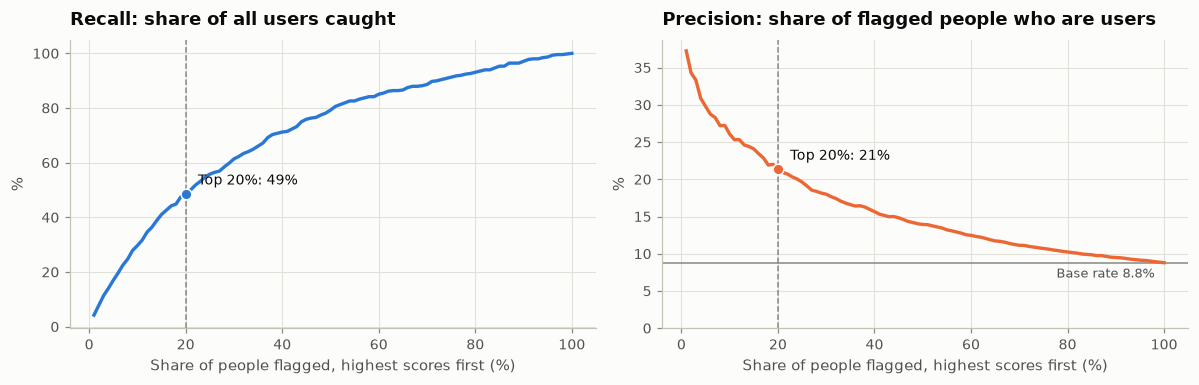

Recommended rule: flag the top 20% of scores. On the training scores that is a cutoff of 0.602.


In [60]:
grid_share = np.linspace(0.01, 1, 100)
curve = pd.DataFrame([top_share_metrics(y_train, chosen_oof, s) for s in grid_share], index=grid_share)
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
for ax, col, title, colour in [(axes[0], "recall", "Recall: share of all users caught", BLUE),
                               (axes[1], "precision", "Precision: share of flagged people who are users", ORANGE)]:
    ax.plot(curve.index * 100, curve[col] * 100, color=colour, linewidth=2.2, zorder=3)
    ax.axvline(TOP_SHARE * 100, color=MUTED, linestyle="--", linewidth=1)
    v = tradeoff.loc[tradeoff["Share of people flagged"] == TOP_SHARE].iloc[0]
    val = v["Recall (share of users caught)"] if col == "recall" else v["Precision (share of flagged who are users)"]
    ax.plot(TOP_SHARE * 100, val * 100, "o", color=colour, markersize=7, markeredgecolor=SURFACE, zorder=4)
    ax.annotate(f"Top 20%: {val:.0%}", (TOP_SHARE * 100, val * 100), xytext=(8, 6), textcoords="offset points", fontsize=9)
    ax.set_xlabel("Share of people flagged, highest scores first (%)")
    ax.set_ylabel("%")
    ax.set_title(title)
axes[1].axhline(base_rate * 100, color=MUTED, linewidth=1)
axes[1].set_ylim(0, None)
axes[1].text(98, base_rate * 100 - 2, "Base rate 8.8%", ha="right", fontsize=8.5, color=INK2)
fig.tight_layout()
fig.savefig(FIG_DIR / "16_threshold_tradeoff.png")
plt.show()

THRESHOLD = float(np.quantile(chosen_oof, 1 - TOP_SHARE))     # fixed on training data, applied unchanged to the test set
print(f"Recommended rule: flag the top {TOP_SHARE:.0%} of scores. On the training scores that is a cutoff of {THRESHOLD:.3f}.")

**Takeaways** (out-of-fold scores, all 5,093 training respondents pooled)

- **The trade-off is steep at the top.** Flagging the top 5% gives the highest precision (29.8%, 3.39 times the average) but catches only 17.0% of users. Flagging the top 50% catches 79.2% of users, but only 13.9% of those flagged are users, barely 1.6 times the average.
- **The default 0.5 cut-off would flag 31% of people,** a side effect of the class weights, not a deliberate choice. This is why the rule is stated as a share.
- **Recommendation: flag the top 20% of scores** (score of 0.602 or more). On the training scores this catches **48.7% of users at 21.4% precision, a lift of 2.43x**. It is the point where the model still finds about half the users, while those flagged remain well over twice as likely to be users as the average person. Beyond 20%, each extra person flagged adds users at close to the average rate.
- **Different uses can justify different shares.**
  - *Card company (Task C):* the top 10–20%, where marketing spend works hardest (lift 3.0x at 10%, 2.4x at 20%).
  - *CFPB (Task D):* missing an at-risk user is worse than flagging a non-user, so a wider net is defensible: the top 30% catches 61.4% of users.

(The 48.7% here pools all respondents; the 48.4% in Section 4 is the average of five per-fold figures. They measure the same thing in slightly different ways.)

---
## 7. Final test-set evaluation

**This is the first and only time the test set is used.** All three tuned models, each refitted on the full training set, score the 1,274 test respondents. The top-20% cut-off for each model was fixed on its training scores in the previous sections and is applied unchanged.

Test results for the two models not chosen are shown for transparency. They do not change the choice made in Section 5: re-choosing a model after looking at the test set would turn the test set into another tuning set.

**Lift** is the usage rate in a group divided by the overall usage rate. A lift of 2.0x means the group uses prepaid cards at twice the average rate.

In [61]:
# The only place the test set is used. Every model is the tuned pipeline refitted on the full training set by GridSearchCV.
test_scores = {name: spec["best"].predict_proba(X_test)[:, 1] for name, spec in MODELS.items()}
model_cutoffs = {name: float(np.quantile(oof[name], 1 - TOP_SHARE)) for name in MODELS}   # each model's own training-derived top-20% cutoff

rows = []
for name, s in test_scores.items():
    flagged = s >= model_cutoffs[name]
    tn, fp, fn, tp = confusion_matrix(y_test, flagged).ravel()
    rows.append({"Model": name, "ROC-AUC": roc_auc_score(y_test, s), "PR-AUC": average_precision_score(y_test, s),
                 "Share flagged": flagged.mean(), "Recall": tp / (tp + fn), "Precision": tp / (tp + fp), "Lift": (tp / (tp + fp)) / y_test.mean()})
test_table = pd.DataFrame(rows).set_index("Model")
test_table.loc["Cross-validated (training) for reference: chosen model", ["ROC-AUC", "PR-AUC"]] = cv_compare.loc[CHOSEN, ["ROC-AUC", "PR-AUC"]].to_numpy()
print(f"Test set: {len(y_test):,} respondents, {int(y_test.sum())} users. Recall, precision and lift use each model's training-derived top-20% cutoff.")
display(fmt(test_table, {"ROC-AUC": "{:.3f}", "PR-AUC": "{:.3f}", "Share flagged": "{:.1%}", "Recall": "{:.1%}", "Precision": "{:.1%}", "Lift": "{:.2f}x"}))

Test set: 1,274 respondents, 112 users. Recall, precision and lift use each model's training-derived top-20% cutoff.


,ROC-AUC,PR-AUC,Share flagged,Recall,Precision,Lift
Model,,,,,,
Logistic regression,0.746,0.247,19.3%,53.6%,24.4%,2.77x
Random forest,0.749,0.244,18.9%,49.1%,22.8%,2.60x
XGBoost,0.736,0.247,18.2%,50.0%,24.1%,2.75x
Cross-validated (training) for reference: chosen model,0.730,0.225,,,,


In [62]:
flagged = test_scores[CHOSEN] >= THRESHOLD
cm = pd.DataFrame(confusion_matrix(y_test, flagged), index=["Actual: non-user", "Actual: prepaid user"],
                  columns=["Predicted: not flagged", "Predicted: flagged"])
print(f"Confusion matrix, {CHOSEN}, cutoff {THRESHOLD:.3f} (the top 20% rule fixed on training data):")
display(cm)
tn, fp, fn, tp = cm.to_numpy().ravel()
print(f"Flagged {tp + fp} of {len(y_test):,} ({(tp + fp) / len(y_test):.1%}); caught {tp} of {tp + fn} users (recall {tp / (tp + fn):.1%}); "
      f"{tp / (tp + fp):.1%} of those flagged are users (precision), against a base rate of {y_test.mean():.1%}.")
print(f"Accuracy, for comparison only: {(tp + tn) / len(y_test):.1%}. Flagging no one would score {1 - y_test.mean():.1%}.")

Confusion matrix, Logistic regression, cutoff 0.602 (the top 20% rule fixed on training data):


,Predicted: not flagged,Predicted: flagged
Actual: non-user,976,186
Actual: prepaid user,52,60


Flagged 246 of 1,274 (19.3%); caught 60 of 112 users (recall 53.6%); 24.4% of those flagged are users (precision), against a base rate of 8.8%.
Accuracy, for comparison only: 81.3%. Flagging no one would score 91.2%.


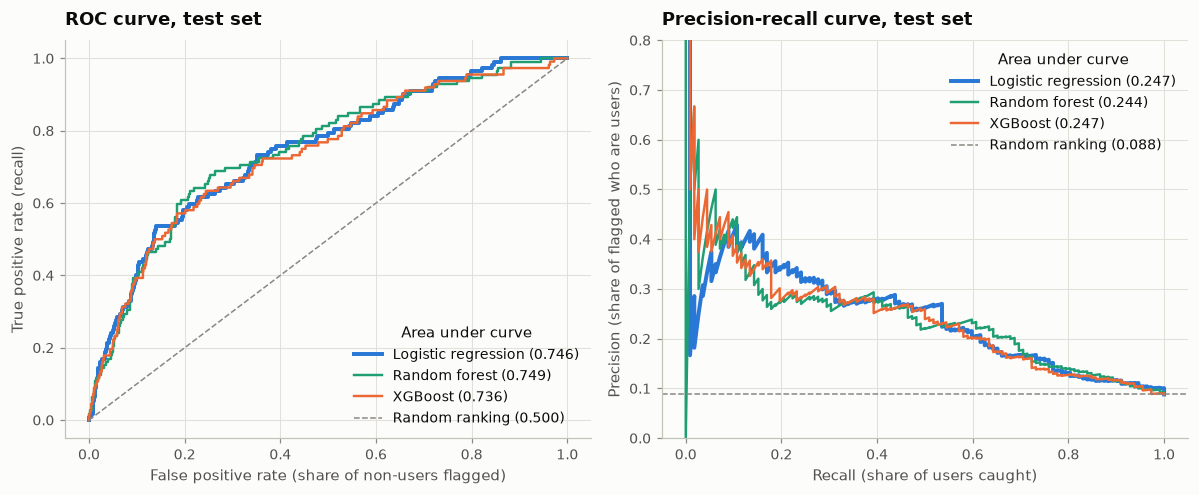

In [63]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.6))
for name, s in test_scores.items():
    fpr, tpr, _ = roc_curve(y_test, s)
    prec, rec, _ = precision_recall_curve(y_test, s)
    lw = 2.6 if name == CHOSEN else 1.6
    axes[0].plot(fpr, tpr, color=MODEL_COLOURS[name], linewidth=lw, label=f"{name} ({test_table.loc[name, 'ROC-AUC']:.3f})")
    axes[1].plot(rec, prec, color=MODEL_COLOURS[name], linewidth=lw, label=f"{name} ({test_table.loc[name, 'PR-AUC']:.3f})")
axes[0].plot([0, 1], [0, 1], color=MUTED, linestyle="--", linewidth=1, label="Random ranking (0.500)")
axes[1].axhline(y_test.mean(), color=MUTED, linestyle="--", linewidth=1, label=f"Random ranking ({y_test.mean():.3f})")
axes[0].set(xlabel="False positive rate (share of non-users flagged)", ylabel="True positive rate (recall)", title="ROC curve, test set")
axes[1].set(xlabel="Recall (share of users caught)", ylabel="Precision (share of flagged who are users)", title="Precision-recall curve, test set")
axes[1].set_ylim(0, 0.8)
for ax in axes:
    ax.legend(loc="lower right" if ax is axes[0] else "upper right", title="Area under curve")
fig.tight_layout()
fig.savefig(FIG_DIR / "17_test_roc_pr_curves.png")
plt.show()

In [64]:
def lift_table(y, score):
    """Decile 1 = the 10% with the highest scores."""
    d = pd.DataFrame({"y": np.asarray(y), "score": np.asarray(score)}).sort_values("score", ascending=False).reset_index(drop=True)
    d["decile"] = np.arange(len(d)) * 10 // len(d) + 1
    t = d.groupby("decile").agg(people=("y", "size"), users=("y", "sum"), usage_rate=("y", "mean"))
    t["lift"] = t["usage_rate"] / d["y"].mean()
    t["cumulative share of users captured"] = t["users"].cumsum() / d["y"].sum()
    return t


lifts = {name: lift_table(y_test, s) for name, s in test_scores.items()}
print(f"Lift by decile on the test set, {CHOSEN}:")
display(fmt(lifts[CHOSEN], {"usage_rate": "{:.1%}", "lift": "{:.2f}x", "cumulative share of users captured": "{:.1%}"}))

capture = pd.DataFrame({name: t["cumulative share of users captured"].loc[[1, 2, 3, 5]].to_numpy() for name, t in lifts.items()},
                       index=["Top 10%", "Top 20%", "Top 30%", "Top 50%"]).T
capture["Top-decile lift"] = [lifts[n].loc[1, "lift"] for n in capture.index]
print("Share of all test-set users captured in the top X% of scores:")
display(fmt(capture, {c: "{:.1%}" for c in capture.columns[:-1]} | {"Top-decile lift": "{:.2f}x"}))

Lift by decile on the test set, Logistic regression:


,people,users,usage_rate,lift,cumulative share of users captured
decile,,,,,
1,128,35,27.3%,3.11x,31.2%
2,127,25,19.7%,2.24x,53.6%
3,128,11,8.6%,0.98x,63.4%
4,127,11,8.7%,0.99x,73.2%
5,127,4,3.1%,0.36x,76.8%
6,128,7,5.5%,0.62x,83.0%
7,127,9,7.1%,0.81x,91.1%
8,128,4,3.1%,0.36x,94.6%
9,127,6,4.7%,0.54x,100.0%


Share of all test-set users captured in the top X% of scores:


,Top 10%,Top 20%,Top 30%,Top 50%,Top-decile lift
Logistic regression,31.2%,53.6%,63.4%,76.8%,3.11x
Random forest,30.4%,50.0%,68.8%,79.5%,3.02x
XGBoost,32.1%,52.7%,63.4%,75.9%,3.20x


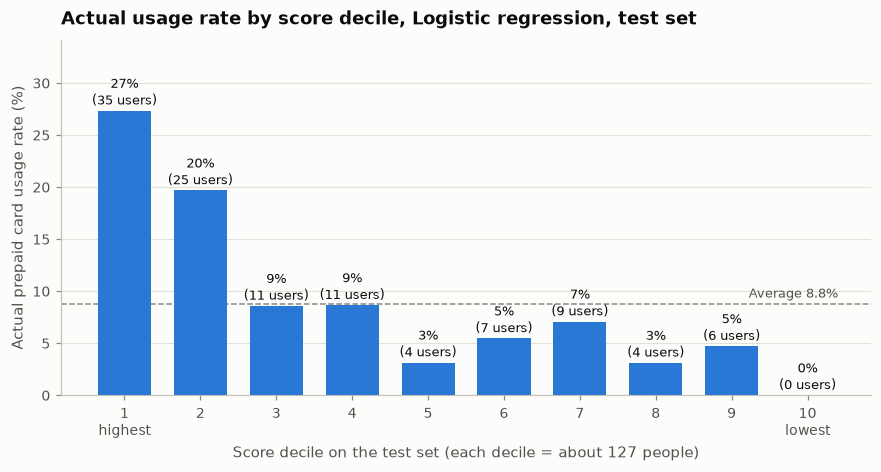

In [65]:
fig, ax = plt.subplots(figsize=(9.5, 4.2))
t = lifts[CHOSEN]
bars = ax.bar(t.index, t["usage_rate"] * 100, color=BLUE, width=0.7, zorder=3)
for x, (rate, users) in enumerate(zip(t["usage_rate"], t["users"]), start=1):
    ax.text(x, rate * 100 + 0.6, f"{rate:.0%}\n({users} users)", ha="center", fontsize=8.5, color=INK)
ax.axhline(y_test.mean() * 100, color=MUTED, linestyle="--", linewidth=1)
ax.text(10.4, y_test.mean() * 100 + 0.6, f"Average {y_test.mean():.1%}", ha="right", fontsize=8.5, color=INK2)
ax.set_xticks(t.index, [f"{d}\n{'highest' if d == 1 else 'lowest' if d == 10 else ''}" for d in t.index])
ax.set_xlabel("Score decile on the test set (each decile = about 127 people)")
ax.set_ylabel("Actual prepaid card usage rate (%)")
ax.set_ylim(0, t["usage_rate"].max() * 100 * 1.25)
ax.set_title(f"Actual usage rate by score decile, {CHOSEN}, test set")
ax.grid(axis="x", visible=False)
fig.savefig(FIG_DIR / "18_test_lift_by_decile.png")
plt.show()

In [66]:
# How uncertain are the test-set numbers? Resample the 1,274 test respondents 2,000 times (bootstrap).
rng = np.random.default_rng(SEED)
yt = y_test.to_numpy()
boot = {k: [] for k in ["chosen ROC-AUC", "chosen PR-AUC", "XGBoost minus chosen, PR-AUC", "Random forest minus chosen, PR-AUC"]}
for _ in range(2000):
    i = rng.integers(0, len(yt), len(yt))
    if yt[i].sum() == 0:
        continue
    pr = {n: average_precision_score(yt[i], s[i]) for n, s in test_scores.items()}
    boot["chosen ROC-AUC"].append(roc_auc_score(yt[i], test_scores[CHOSEN][i]))
    boot["chosen PR-AUC"].append(pr[CHOSEN])
    boot["XGBoost minus chosen, PR-AUC"].append(pr["XGBoost"] - pr[CHOSEN])
    boot["Random forest minus chosen, PR-AUC"].append(pr["Random forest"] - pr[CHOSEN])
ci = pd.DataFrame({k: {"2.5%": np.percentile(v, 2.5), "median": np.median(v), "97.5%": np.percentile(v, 97.5)} for k, v in boot.items()}).T
print("95% bootstrap intervals on the test set:")
display(fmt(ci, "{:+.3f}"))

95% bootstrap intervals on the test set:


,2.5%,median,97.5%
chosen ROC-AUC,+0.699,+0.746,+0.794
chosen PR-AUC,+0.186,+0.253,+0.328
"XGBoost minus chosen, PR-AUC",-0.034,+0.000,+0.034
"Random forest minus chosen, PR-AUC",-0.048,-0.002,+0.042


**Takeaways**

- **The test results confirm cross-validation.** The chosen model scores **ROC-AUC 0.746 and PR-AUC 0.247** on the test set, against 0.730 and 0.225 in cross-validation. There is no sign of overfitting.
- **The ranking of the three models shuffles on the test set**: the random forest has the best ROC-AUC (0.749), XGBoost and logistic regression share the best PR-AUC (0.247), and logistic regression has the best recall at the top 20% (53.6%). This is what a tie looks like. The bootstrap intervals for the PR-AUC gaps (XGBoost minus logistic regression: −0.034 to +0.034; random forest minus logistic regression: −0.048 to +0.042) both include zero.
- **At the top-20% rule** (cut-off 0.602, fixed on training data), the model flags 246 of 1,274 people (19.3%) and catches **60 of the 112 users (recall 53.6%)**. Of those flagged, **24.4% are users (precision), 2.77 times the 8.8% average.** It misses 52 users and flags 186 non-users.
- **Accuracy would be misleading.** The model's accuracy is 81.3%, lower than the 91.2% scored by flagging no one, which is useless. This is why accuracy is not used to judge models here.
- **Lift is concentrated in the top two deciles.** The top 10% of scores has a usage rate of 27.3% (3.11x) and the next 10% has 19.7%; from the third decile down, every decile is at or below the 8.8% average, and the lowest decile has no users at all. **The top 10% of scores holds 31.2% of all users, the top 20% holds 53.6% and the top 30% holds 63.4%.**
- **The numbers are uncertain.** With only 112 users in the test set, the 95% bootstrap interval for the chosen model's ROC-AUC is 0.699–0.794, and for its PR-AUC 0.186–0.328. The 53.6% recall on the test set is higher than the 48.7% on training scores; the truth is probably in between, so plan on **about half of users in the top 20%**.

---
## 8. Honest reading: what the model can and cannot do

**What it can do**
- **Sort a population into a high-use and a low-use group.** People in the top 20% of scores use prepaid cards at about 2.4–2.8 times the average rate (2.43x on training scores, 2.77x on the test set), and that group contains roughly half of all users. People in the bottom half are much less likely to be users. For a marketing list or for sizing an at-risk group, this is useful.
- **Do so with a model that can be explained.** Every score is a weighted sum of 17 survey answers, so Tasks C and D can say which characteristics are associated with higher scores.
- **Hold up on new data.** Test-set performance matched cross-validation.

**What it cannot do**
- **It cannot identify individual users with confidence.** Even in the top 20%, three in four people flagged are not users, and almost half of all users fall outside the top 20%.
- **Its scores are rankings, not probabilities.** Because of the class weights, a score of 0.6 does not mean a 60% chance. To read scores as probabilities they would need to be recalibrated, which was not done. Tasks C and D should compare people by score rank or by actual usage rates within score groups, not by the score itself.
- **It cannot be made much better with these predictors.** Three very different algorithms, tuned, all land at a ROC-AUC near 0.73. The limit is the information in the 17 predictors, not the algorithm.
- **It shows associations, not causes.** A high weight on "contacted by a debt collector" means the two go together, not that one causes the other.
- **It describes this 2016 sample.** Survey weights were ignored (as the brief requires), so the usage rates are not national estimates.

---
## 9. Hand-off

#### Files produced

| File | Contents |
|---|---|
| `data/test_scores.csv` | 1,274 test respondents: `PUF_ID`, `PRODUSE_3`, `score_logit`, `score_rf`, `score_xgb`, `score_chosen` |
| `data/train_oof_scores.csv` | 5,093 training respondents, same columns. Out-of-fold scores: each person scored by a model that did not see them |
| `models/chosen_model.joblib` | The chosen pipeline (preparation + model), fitted on the full training set |
| `figures/15–18` | Charts from this part |

In [67]:
def score_frame(index, y, scores):
    out = pd.DataFrame({"PRODUSE_3": np.asarray(y)}, index=index)
    for name, spec in MODELS.items():
        out[f"score_{spec['key']}"] = scores[name]
    out["score_chosen"] = scores[CHOSEN]
    out.index.name = "PUF_ID"
    return out


test_out = score_frame(X_test.index, y_test, test_scores)
oof_out = score_frame(X_train.index, y_train, oof)
test_out.to_csv(DATA_DIR / "test_scores.csv")
oof_out.to_csv(DATA_DIR / "train_oof_scores.csv")
joblib.dump(chosen_model, MODEL_DIR / "chosen_model.joblib")

reloaded = joblib.load(MODEL_DIR / "chosen_model.joblib")
handoff_checks = {
    "test_scores.csv has one row per test respondent": len(pd.read_csv(DATA_DIR / "test_scores.csv")) == len(X_test),
    "train_oof_scores.csv has one row per training respondent": len(pd.read_csv(DATA_DIR / "train_oof_scores.csv")) == len(X_train),
    "Columns are PUF_ID, PRODUSE_3, score_logit, score_rf, score_xgb, score_chosen":
        list(pd.read_csv(DATA_DIR / "test_scores.csv").columns) == ["PUF_ID", "PRODUSE_3", "score_logit", "score_rf", "score_xgb", "score_chosen"],
    "Saved model reproduces the test scores": bool(np.allclose(reloaded.predict_proba(X_test)[:, 1], test_out["score_chosen"])),
    "score_chosen equals the chosen model's column": bool(np.allclose(test_out["score_chosen"], test_out[f"score_{chosen_spec['key']}"])),
    "No missing scores": bool(test_out.notna().all().all() and oof_out.notna().all().all()),
}
display(pd.DataFrame({"Check": list(handoff_checks), "Result": ["PASS" if ok else "FAIL" for ok in handoff_checks.values()]}))
assert all(handoff_checks.values())
print("Saved: data/test_scores.csv, data/train_oof_scores.csv, models/chosen_model.joblib")

,Check,Result
0,test_scores.csv has one row per test respondent,PASS
1,train_oof_scores.csv has one row per training respondent,PASS
2,"Columns are PUF_ID, PRODUSE_3, score_logit, score_rf, score_xgb, score_chosen",PASS
3,Saved model reproduces the test scores,PASS
4,score_chosen equals the chosen model's column,PASS
5,No missing scores,PASS


Saved: data/test_scores.csv, data/train_oof_scores.csv, models/chosen_model.joblib


In [68]:
t = test_table.loc[CHOSEN]
chosen_record = pd.DataFrame({"Value": [
    CHOSEN, best_table.loc[CHOSEN, "Best settings"], "class_weight='balanced'",
    f"Flag the top {TOP_SHARE:.0%} of scores", f"{THRESHOLD:.3f} (score_chosen >= this value)",
    f"{cv_compare.loc[CHOSEN, 'ROC-AUC']:.3f} ± {cv_compare.loc[CHOSEN, 'ROC-AUC sd']:.3f}",
    f"{cv_compare.loc[CHOSEN, 'PR-AUC']:.3f} ± {cv_compare.loc[CHOSEN, 'PR-AUC sd']:.3f}",
    f"{t['ROC-AUC']:.3f}", f"{t['PR-AUC']:.3f}",
    f"recall {t['Recall']:.1%}, precision {t['Precision']:.1%}, lift {t['Lift']:.2f}x",
    "score_chosen in data/test_scores.csv and data/train_oof_scores.csv; models/chosen_model.joblib"]},
    index=["Chosen model", "Tuned settings", "Class imbalance handling", "Recommended rule", "Score cutoff",
           "Cross-validated ROC-AUC", "Cross-validated PR-AUC", "Test ROC-AUC", "Test PR-AUC", "Test, top-20% rule", "Where to find it"])
display(chosen_record)

,Value
Chosen model,Logistic regression
Tuned settings,C=0.3
Class imbalance handling,class_weight='balanced'
Recommended rule,Flag the top 20% of scores
Score cutoff,0.602 (score_chosen >= this value)
Cross-validated ROC-AUC,0.730 ± 0.030
Cross-validated PR-AUC,0.225 ± 0.028
Test ROC-AUC,0.746
Test PR-AUC,0.247
"Test, top-20% rule","recall 53.6%, precision 24.4%, lift 2.77x"


#### How Tasks C and D use this

```python
import joblib, pandas as pd
import prep

scores_test = pd.read_csv("data/test_scores.csv", index_col="PUF_ID")       # final numbers
scores_oof = pd.read_csv("data/train_oof_scores.csv", index_col="PUF_ID")   # profiling 5,093 people without leakage
model = joblib.load("models/chosen_model.joblib")                           # preparation + logistic regression
coefs = pd.Series(model.named_steps["model"].coef_[0], index=prep.readable_names(model.named_steps["prep"]))
```

#### Notes for the next tasks

- **Use `score_chosen`.** The other three score columns are there so the three models can be compared, not to be mixed.
- **Treat scores as rankings.** "Top 20%" means `score_chosen >= 0.602` (the cut-off fixed on training data), or the top 20% by rank within whichever group is being profiled. Report actual usage rates within score groups, not average scores.
- **Out-of-fold scores come from five slightly different models** (one per fold). They are fine for ranking and profiling within the training set; the test-set scores come from the single final model.
- **Task C:** the model is a logistic regression on standardised inputs, so `exp(weight)` gives the odds ratio for a one-standard-deviation change (or for a yes versus no). Treat savings, ability to raise \$2,000 and the well-being score as one liquidity group, as Task A advised; their weights split a shared signal between them.
- **Task D:** for screening at-risk groups, the top 30% (61.4% of users caught on training scores) may suit better than the top 20%; Section 6 has the full trade-off table.

# Part 4: Card company marketing and origination strategy

*Lead: Ethan Dsouza.*

**Question.** Can a card company build a marketing and origination strategy around who to target for a prepaid card, and what are the key insights about who is likely to use one?

**Purpose.** Turn the chosen model from Part 3 into a practical, responsible strategy: who is most likely to use a reloadable prepaid card, which of those signals a company can actually see, and how the product should be marketed and originated.

| Section | What it delivers |
|---|---|
| 1. Setup | The shared split, the 17 predictors and the chosen model's scores |
| 2. What drives the score | The model's weights, read as odds ratios |
| 3. Target segments | Size, usage rate and lift of each candidate segment, confirmed on the test set |
| 4. Reachability | How much targeting power survives when only company-observable data is used |
| 5. Strategy | Who to target, channels, message, origination and measurement, each tied to evidence |
| 6. Responsible marketing | Who the targeting rule reaches, by race/ethnicity |
| 7. Conclusions and limitations | What the company can and cannot rely on |

### Summary

- **Target the top 20% of model scores.** On the test set the rule flags 246 of 1,274 people (19.3%), reaches 60 of the 112 prepaid users (53.6%), and 24.4% of those flagged are users: **2.77 times** the 8.8% average. On the larger training set the figures are 48.7% of users and 2.43 times. Plan on **about half of users at roughly 2.4 to 2.8 times the average rate**. Three in four people flagged are not users.
- **What raises the score most is access to mainstream finance and credit distress.** Having a bank account has the largest weight (odds ratio 0.58). Contact from a debt collector (1.47), being turned down for credit (1.30), financial shocks (1.29 per standard deviation) and renting (1.63 against owning) raise it. Higher financial knowledge (0.80 per standard deviation) and income (0.81) lower it. The model does not use age, marital status or SNAP receipt, which are prohibited bases under fair-lending law (Part 2).
- **Savings, ability to raise \$2,000, well-being and the hardship count add almost nothing inside the model**, although each is strongly related to prepaid use on its own. Other predictors already carry their signal: without the three liquidity measures the training lift is 2.49, against 2.43 with them.
- **A company can get most of this from data it can observe.** With the 10 predictors a company can observe or partly observe, the top-20% lift is 2.41 on training data (99% of the full model) and 2.40 on test data (87%). With only the 3 it clearly has (income, housing, debt-collection contact), lift is 2.26 and 2.03 (93% and 73%).
- **"The unbanked" is not the market.** 69.2% of prepaid users have a bank account. The top-20% rule mostly finds the financially fragile users; the half of users it misses are 89.1% banked and need a different, mainstream message.
- **The best prospects are also the most fee-sensitive.** Among those flagged, 72.6% report a material hardship and 61.0% have under \$1,000 in savings. The rule also flags 42.2% of Black and 40.8% of Hispanic respondents against 12.6% of White respondents, though race is not a predictor. Transparent, low-fee product design is part of the strategy, not an afterthought.

All results are associations in a 2016 self-reported survey, unweighted as the brief requires. They are not causal effects, national estimates or forecasts of revenue.

---
## 1. Setup

This part uses the fixed train/test split and 17 predictors from Part 2, and the chosen model and its scores from Part 3. Nothing is re-split, re-cleaned or re-tuned.

- **Training scores are out-of-fold:** each of the 5,093 training respondents was scored by a model that did not see them, so they can be used for profiling without leakage.
- **Test scores** (1,274 respondents) are used only to confirm the patterns found on the training scores.
- **The top-20% rule** from Part 3 is applied as a fixed score cut-off taken from the training scores.

In [69]:
from pathlib import Path
import warnings

import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

import prep
from prep import build_preprocessor, feature_lists, feature_table, load_profile, load_split, readable_names

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_columns", 60, "display.width", 220, "display.max_colwidth", 110, "display.max_rows", 100)

DATA_DIR = Path("data")
FIG_DIR = Path("figures")
FIG_DIR.mkdir(exist_ok=True)
SEED = 42
TOP_SHARE = 0.20

INK, INK2, MUTED = "#0b0b0b", "#52514e", "#898781"
GRID, AXIS, SURFACE = "#e1e0d9", "#c3c2b7", "#fcfcfb"
BLUE, ORANGE = "#2a78d6", "#eb6834"
mpl.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "figure.dpi": 110, "savefig.dpi": 200, "savefig.bbox": "tight",
    "font.size": 10, "text.color": INK, "axes.labelcolor": INK2,
    "axes.titlesize": 11.5, "axes.titleweight": "bold", "axes.titlelocation": "left", "axes.titlepad": 10,
    "axes.edgecolor": AXIS, "axes.linewidth": 0.8, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "axes.axisbelow": True, "grid.color": GRID, "grid.linewidth": 0.7,
    "xtick.color": MUTED, "ytick.color": MUTED, "xtick.labelcolor": INK2, "ytick.labelcolor": INK2,
    "xtick.labelsize": 9, "ytick.labelsize": 9, "legend.frameon": False, "legend.fontsize": 9,
})


def fmt(df, formats, hide_index=False):
    """Return a display copy of a table with numbers formatted as text."""
    out = df.copy()
    if isinstance(formats, str):
        formats = {c: formats for c in out.columns if pd.api.types.is_numeric_dtype(out[c])}
    for col, pattern in formats.items():
        if col in out.columns:
            out[col] = out[col].map(lambda v, p=pattern: p.format(v) if pd.notna(v) else "")
    return out.reset_index(drop=True) if hide_index else out


def logit():
    """The chosen model's settings from Part 3."""
    return LogisticRegression(C=0.3, class_weight="balanced", max_iter=5000, random_state=SEED)


X_train, X_test, y_train, y_test = load_split()
train_scores = pd.read_csv(DATA_DIR / "train_oof_scores.csv", index_col="PUF_ID")
test_scores = pd.read_csv(DATA_DIR / "test_scores.csv", index_col="PUF_ID")
train_raw = pd.read_csv(DATA_DIR / "train.csv", index_col="PUF_ID")
test_raw = pd.read_csv(DATA_DIR / "test.csv", index_col="PUF_ID")
features = feature_table()

assert train_scores.index.equals(train_raw.index) and test_scores.index.equals(test_raw.index)
assert train_scores["score_chosen"].notna().all() and test_scores["score_chosen"].notna().all()
base_rate = y_train.mean()
threshold = float(np.quantile(train_scores["score_chosen"], 1 - TOP_SHARE))
print(f"Training: {len(train_raw):,} respondents, {int(y_train.sum())} prepaid users ({base_rate:.1%})")
print(f"Test:     {len(test_raw):,} respondents, {int(y_test.sum())} prepaid users ({y_test.mean():.1%})")
print(f"Top-{TOP_SHARE:.0%} rule from Part 3: score_chosen >= {threshold:.3f} (cut-off fixed on training scores)")

# Refit the chosen model from its documented settings, so this notebook does not depend on a saved model file.
chosen_model = Pipeline([("prep", build_preprocessor()), ("model", logit())]).fit(X_train, y_train)
refit_test_scores = chosen_model.predict_proba(X_test)[:, 1]
assert np.allclose(refit_test_scores, test_scores["score_chosen"].to_numpy(), atol=1e-8)
print("Refitted chosen model reproduces the Part 3 test scores exactly.")

Training: 5,093 respondents, 448 prepaid users (8.8%)
Test:     1,274 respondents, 112 prepaid users (8.8%)
Top-20% rule from Part 3: score_chosen >= 0.602 (cut-off fixed on training scores)
Refitted chosen model reproduces the Part 3 test scores exactly.


---
## 2. What drives the score?

The chosen model is a logistic regression: it adds up one weight per predictor and turns the total into a score. A positive weight raises the score, a negative weight lowers it, **holding the other 16 predictors fixed**.

**Odds ratio** = `exp(weight)`. An odds ratio of 1.47 means the odds of being a prepaid user are 47% higher; 0.58 means 42% lower. For yes/no predictors it compares yes with no. For ordered scales and scores, which were standardised, it is the change for a one-standard-deviation increase.

**Two cautions before reading the tables**

1. **Weights are not the same as the raw patterns in Part 1.** Part 1 looked at one variable at a time. A model weight is what a predictor adds *after* the other 16 are accounted for. A variable that is strongly related to prepaid use on its own can have a small weight if other predictors already carry its signal.
2. **These are associations, not causes.**

The saved model keeps every category of housing and employment, so those weights have no reference group. The second table refits the same model with a reference category (owns home, self-employed) to give odds ratios that can be read as "compared with".

In [70]:
full_coef = pd.Series(chosen_model.named_steps["model"].coef_[0], index=readable_names(chosen_model.named_steps["prep"]), name="Weight")
raw_names = pd.Series(chosen_model.named_steps["prep"].get_feature_names_out(), index=full_coef.index)

scaled_cols, binary_cols, nominal_cols = feature_lists()
single = full_coef[[features.loc[c, "label"] for c in scaled_cols + binary_cols]].to_frame()
single["Odds ratio"] = np.exp(single["Weight"])
single["Type"] = ["Per 1 standard deviation"] * len(scaled_cols) + ["Yes vs no"] * len(binary_cols)
single[f"Rank by size (of {len(full_coef)} model columns)"] = full_coef.abs().rank(ascending=False).astype(int)[single.index]
single = single.sort_values("Weight", key=np.abs, ascending=False)
print(f"Yes/no predictors and ordered scales ({len(scaled_cols) + len(binary_cols)} of the {len(features)} predictors), largest weight first:")
display(fmt(single, {"Weight": "{:+.3f}", "Odds ratio": "{:.2f}"}))

Yes/no predictors and ordered scales (15 of the 17 predictors), largest weight first:


,Weight,Odds ratio,Type,Rank by size (of 26 model columns)
Has: Checking or Savings Account at a bank or credit union,-0.551,0.58,Yes vs no,1
Contacted by debt collector in past 12 months,+0.382,1.47,Yes vs no,3
I applied for credit and was turned down,+0.259,1.30,Yes vs no,8
Number of financial shocks in the past year (0-11),+0.252,1.29,Per 1 standard deviation,9
Knoll and Houts financial knowledge scale score,-0.225,0.80,Per 1 standard deviation,11
Household Income,-0.206,0.81,Per 1 standard deviation,13
Has: Retirement Account (such as a 401k or IRA),-0.170,0.84,Yes vs no,15
Household income volatility,+0.117,1.12,Per 1 standard deviation,16
Past 6 months: Paid all your bills on time,-0.063,0.94,Per 1 standard deviation,20
Financial well-being scale score,+0.056,1.06,Per 1 standard deviation,21


In [71]:
# Category predictors: refit with a reference category so each odds ratio reads as "compared with the reference".
reference_model = Pipeline([("prep", build_preprocessor(drop_first=True)), ("model", logit())]).fit(X_train, y_train)
rank_agreement = pd.Series(reference_model.predict_proba(X_test)[:, 1]).corr(pd.Series(refit_test_scores), method="spearman")
assert rank_agreement > 0.999, "The reference-category refit must rank people the same way as the chosen model"

ref_coef = pd.Series(reference_model.named_steps["model"].coef_[0], index=readable_names(reference_model.named_steps["prep"]))
SHORT = {"Which one of the following best describes your housing situation?": "Housing",
         "Primary or only employment status": "Employment", "Marital Status": "Marital status"}
category = ref_coef[[i for i in ref_coef.index if i.split(": ")[0] in SHORT]].rename("Weight").to_frame()
category["Odds ratio vs reference"] = np.exp(category["Weight"])
category.index = [SHORT[i.split(": ")[0]] + ": " + i.split(": ")[1] for i in category.index]
category["Reference group"] = [{"Housing": "Owns home", "Employment": "Self-employed", "Marital status": "Married"}[i.split(":")[0]] for i in category.index]
category = category.sort_values("Weight", key=np.abs, ascending=False)
print(f"Scores from this refit rank test respondents identically to the chosen model (rank correlation {rank_agreement:.3f}).")
display(fmt(category, {"Weight": "{:+.3f}", "Odds ratio vs reference": "{:.2f}"}))

# The four category groups with the largest weights, mapped back to their survey codes.
GROUP_CODE = {f"{name}: {label}": (var, code) for var, name in [("HOUSING", "Housing"), ("EMPLOY", "Employment"), ("PPMARIT", "Marital status")]
              for code, label in prep.CATEGORY_LABELS[var].items()}
group_sizes = pd.DataFrame({g.split(": ")[1]: [(train_raw[GROUP_CODE[g][0]] == GROUP_CODE[g][1]).sum(),
                                                train_raw.loc[train_raw[GROUP_CODE[g][0]] == GROUP_CODE[g][1], "PRODUSE_3"].sum()]
                            for g in category.index[:4]},
                           index=["Training respondents", "of whom prepaid users"]).astype(int)
print("Size of the four category groups with the largest weights:")
display(group_sizes)

Scores from this refit rank test respondents identically to the chosen model (rank correlation 1.000).


,Weight,Odds ratio vs reference,Reference group
Housing: Rents,+0.491,1.63,Owns home
Employment: Homemaker,-0.466,0.63,Self-employed
Housing: Neither owns nor rents,+0.457,1.58,Owns home
Employment: Full-time student,-0.404,0.67,Self-employed
"Employment: Sick, disabled or unable to work",+0.222,1.25,Self-employed
Employment: Retired,+0.187,1.21,Self-employed
Employment: Works full-time,-0.146,0.86,Self-employed
Employment: Works part-time,+0.119,1.13,Self-employed
Employment: Unemployed or laid off,+0.015,1.02,Self-employed


Size of the four category groups with the largest weights:


,Rents,Homemaker,Neither owns nor rents,Full-time student
Training respondents,1323,285,431,179
of whom prepaid users,202,23,61,14


#### The liquidity group, and hardship, carry little weight inside the model

Part 1 found savings, the ability to raise \$2,000 and financial well-being among the variables most strongly related to prepaid use when looked at one at a time. The table above shows that **inside the model they barely matter**. The next cell measures this directly by removing them and re-scoring.

In [72]:
liquidity = ["SAVINGSRANGES", "ABSORBSHOCK", "FWBscore"]
folds = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)


def subset_preprocessor(columns):
    """The shared preparation rules from prep.py, applied to a subset of the predictors."""
    columns = list(columns)
    return ColumnTransformer([
        ("scaled", Pipeline([("impute", SimpleImputer(strategy="median")), ("scale", StandardScaler())]), [c for c in scaled_cols if c in columns]),
        ("binary", SimpleImputer(strategy="most_frequent"), [c for c in binary_cols if c in columns]),
        ("nominal", Pipeline([("impute", SimpleImputer(strategy="most_frequent")),
                              ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False))]), [c for c in nominal_cols if c in columns]),
    ], remainder="drop", verbose_feature_names_out=False)


def targeting_metrics(y, flag):
    y, flag = np.asarray(y), np.asarray(flag)
    hits = int((flag & (y == 1)).sum())
    return {"People flagged": int(flag.sum()), "Share flagged": flag.mean(), "Usage rate among flagged": y[flag].mean(),
            "Recall (share of users caught)": hits / int((y == 1).sum()), "Lift": y[flag].mean() / y.mean()}


def subset_scores(columns):
    """Out-of-fold training scores and test scores for the chosen model fitted on a subset of predictors."""
    model = Pipeline([("prep", subset_preprocessor(columns)), ("model", logit())])
    oof = cross_val_predict(model, X_train[columns], y_train, cv=folds, method="predict_proba")[:, 1]
    test = model.fit(X_train[columns], y_train).predict_proba(X_test[columns])[:, 1]
    return oof, test


def top20_rows(label, oof, test):
    """Top-20% results, with the cut-off fixed on the training scores and applied unchanged to the test set."""
    cutoff = np.quantile(oof, 1 - TOP_SHARE)
    return [{"Predictors used": label, "File": "Training (out-of-fold)", **targeting_metrics(y_train, oof >= cutoff)},
            {"Predictors used": label, "File": "Test", **targeting_metrics(y_test, test >= cutoff)}]


without_liquidity = [c for c in features.index if c not in liquidity]
oof_wo, test_wo = subset_scores(without_liquidity)
ablation = pd.DataFrame(top20_rows(f"All {len(features)} predictors", train_scores["score_chosen"].to_numpy(), test_scores["score_chosen"].to_numpy())
                        + top20_rows(f"{len(without_liquidity)} predictors (savings, raise $2,000 and well-being removed)", oof_wo, test_wo))
display(fmt(ablation, {"Share flagged": "{:.1%}", "Usage rate among flagged": "{:.1%}", "Recall (share of users caught)": "{:.1%}", "Lift": "{:.2f}x"}))
rho = pd.Series(test_wo).corr(pd.Series(test_scores["score_chosen"].to_numpy()), method="spearman")
print(f"Rank correlation between test scores with and without the three liquidity predictors: {rho:.3f}")

,Predictors used,File,People flagged,Share flagged,Usage rate among flagged,Recall (share of users caught),Lift
0,All 17 predictors,Training (out-of-fold),1019,20.0%,21.4%,48.7%,2.43x
1,All 17 predictors,Test,246,19.3%,24.4%,53.6%,2.77x
2,"14 predictors (savings, raise $2,000 and well-being removed)",Training (out-of-fold),1019,20.0%,21.9%,49.8%,2.49x
3,"14 predictors (savings, raise $2,000 and well-being removed)",Test,247,19.4%,24.3%,53.6%,2.76x


Rank correlation between test scores with and without the three liquidity predictors: 0.998


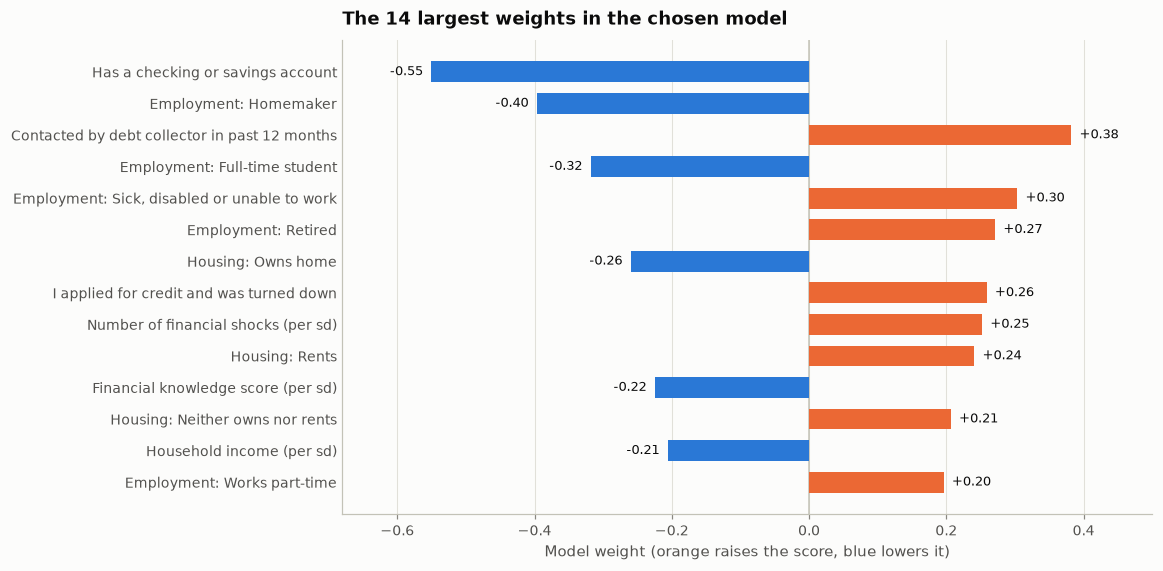

In [73]:
top = full_coef.reindex(full_coef.abs().sort_values(ascending=False).index).head(14).iloc[::-1]
labels = [l.replace("Which one of the following best describes your housing situation?", "Housing")
           .replace("Primary or only employment status", "Employment").replace("Marital Status", "Marital status")
           .replace("Has: Checking or Savings Account at a bank or credit union", "Has a checking or savings account")
           .replace("Any household member received SNAP benefits", "Household received SNAP benefits")
           .replace("Knoll and Houts financial knowledge scale score", "Financial knowledge score (per sd)")
           .replace("Number of financial shocks in the past year (0-11)", "Number of financial shocks (per sd)")
           .replace("Household Income", "Household income (per sd)") for l in top.index]
fig, ax = plt.subplots(figsize=(9.5, 5.6))
ax.barh(np.arange(len(top)), top.values, height=0.66, color=[ORANGE if v > 0 else BLUE for v in top.values], zorder=3)
for i, v in enumerate(top.values):
    ax.text(v + (0.012 if v > 0 else -0.012), i, f"{v:+.2f}", va="center", ha="left" if v > 0 else "right", fontsize=8.5, color=INK)
ax.axvline(0, color=AXIS, linewidth=1)
ax.set_yticks(np.arange(len(top)), labels)
ax.set_xlim(-0.68, 0.50)
ax.set_xlabel("Model weight (orange raises the score, blue lowers it)")
ax.set_title("The 14 largest weights in the chosen model")
ax.grid(axis="y", visible=False)
ax.tick_params(axis="y", length=0)
fig.savefig(FIG_DIR / "19_score_associations.png")
plt.show()

**Takeaways**

- **Bank-account status has the largest weight.** People with a checking or savings account have 42% lower odds of prepaid use (odds ratio 0.58), with everything else held fixed.
- **Credit distress raises the score:** contacted by a debt collector (odds ratio 1.47), turned down for credit (1.30), and each standard deviation more financial shocks (1.29).
- **Housing matters:** renters have 1.63 times, and people who neither own nor rent 1.58 times, the odds of homeowners.
- **Knowledge and income lower the score:** 0.80 and 0.81 per standard deviation.
- **Liquidity and hardship carry almost no weight inside the model.** Savings (0.96), ability to raise \$2,000 (1.01), financial well-being (1.06) and the hardship count (1.04) rank 21st to 24th of the 26 model columns, and two of the three liquidity weights point the "wrong" way, which is what weights near zero do. Without the three liquidity predictors the top-20% lift is 2.49 on training data (2.43 with them) and 2.76 on test data (2.77), and the two sets of scores rank people almost identically (rank correlation 0.998).
  - **This does not contradict Part 1.** Low savings and hardship are strongly related to prepaid use on their own. The model shows that bank-account status, debt collection, credit rejection, shocks and employment already carry that signal.
  - **It is good news for the company,** because savings, well-being and hardship are survey-only and cannot be observed for a prospect anyway.
- **Age, marital status and SNAP receipt are not in the model.** They are prohibited bases under fair-lending law (Part 2). Younger adults and SNAP households still use prepaid cards more (Section 3), and the model reaches them through renting, income, employment and credit distress.
- **Employment status matters, against the self-employed:** people who are sick or disabled (1.25) or retired (1.21) score higher.
- **Education and health insurance have weights close to zero** once the other predictors are known.
- **Treat the category weights with care.** Homemaker (0.63) and full-time student (0.67, both against self-employed) are large, but rest on 23 and 14 prepaid users. They are tentative.

---
## 3. Target segments and confirmation on the test set

Each segment is defined by one plain rule a marketing team could act on. For each one the table gives:

- **People** and **share of file:** how big the segment is.
- **Usage rate:** the share of the segment who reported using a prepaid card.
- **Lift:** that rate divided by the overall rate in the same file (8.8%). A lift of 2.0x means twice the average.

Segments are defined on the training set and confirmed on the test set. They overlap heavily (the same person can be a renter, on SNAP and without a bank account), so their sizes must not be added together.

In [74]:
KNOWLEDGE_CUT = float(X_train["KHscore"].quantile(0.25))      # fixed on the training set, applied unchanged to the test set
knowledge_share = (X_train["KHscore"] <= KNOWLEDGE_CUT).mean()


def segment_masks(df):
    return {
        "Top 20% of model scores": df["score_chosen"] >= threshold,
        "Household received SNAP benefits": df["SNAP"] == 1,
        "Turned down for credit": df["REJECTED_1"] == 1,
        "No checking or savings account reported": df["PRODHAVE_1"] == 0,
        "Savings under $1,000": df["SAVINGSRANGES"] <= 3,
        "At least one material hardship": df["HARDSHIP_COUNT"] >= 1,
        "Disabled, unemployed or working part-time": df["EMPLOY"].isin([3, 6, 7]),
        "Rents, or neither owns nor rents": df["HOUSING"].isin([2, 3]),
        f"Low financial knowledge (lowest {knowledge_share:.0%} of scores)": df["KHscore"] <= KNOWLEDGE_CUT,
    }


def segment_table(raw, scores):
    df = raw.join(scores[["score_chosen"]], how="inner")
    overall = df["PRODUSE_3"].mean()
    rows = []
    for segment, mask in segment_masks(df).items():
        rate = df.loc[mask, "PRODUSE_3"].mean()
        rows.append({"Segment": segment, "People": int(mask.sum()), "Share of file": mask.mean(),
                     "Users": int(df.loc[mask, "PRODUSE_3"].sum()), "Usage rate": rate, "Lift": rate / overall})
    return pd.DataFrame(rows).set_index("Segment")


train_segments, test_segments = segment_table(train_raw, train_scores), segment_table(test_raw, test_scores)
segment_results = train_segments.add_suffix(" (train)").join(test_segments.add_suffix(" (test)"))
display(fmt(segment_results, {"People (train)": "{:,}", "Share of file (train)": "{:.1%}", "Usage rate (train)": "{:.1%}", "Lift (train)": "{:.2f}x",
                              "Share of file (test)": "{:.1%}", "Usage rate (test)": "{:.1%}", "Lift (test)": "{:.2f}x"}))
print(f"Overall usage rate: {y_train.mean():.1%} in training, {y_test.mean():.1%} in test.")
print(f"Low financial knowledge = KHscore at or below {KNOWLEDGE_CUT} (the training 25th percentile). "
      f"The score takes only 11 values, so this covers {knowledge_share:.1%} of people, not 25%.")

,People (train),Share of file (train),Users (train),Usage rate (train),Lift (train),People (test),Share of file (test),Users (test),Usage rate (test),Lift (test)
Segment,,,,,,,,,,
Top 20% of model scores,"1,019",20.0%,218,21.4%,2.43x,246,19.3%,60,24.4%,2.77x
Household received SNAP benefits,491,9.6%,113,23.0%,2.62x,123,9.7%,21,17.1%,1.94x
Turned down for credit,504,9.9%,98,19.4%,2.21x,137,10.8%,24,17.5%,1.99x
No checking or savings account reported,715,14.0%,138,19.3%,2.19x,207,16.2%,43,20.8%,2.36x
"Savings under $1,000","1,212",23.8%,202,16.7%,1.89x,294,23.1%,42,14.3%,1.62x
At least one material hardship,"1,458",28.6%,236,16.2%,1.84x,371,29.1%,57,15.4%,1.75x
"Disabled, unemployed or working part-time",746,14.6%,119,16.0%,1.81x,200,15.7%,30,15.0%,1.71x
"Rents, or neither owns nor rents","1,754",34.4%,263,15.0%,1.70x,426,33.4%,56,13.1%,1.50x
Low financial knowledge (lowest 35% of scores),"1,772",34.8%,252,14.2%,1.62x,440,34.5%,77,17.5%,1.99x


Overall usage rate: 8.8% in training, 8.8% in test.
Low financial knowledge = KHscore at or below -0.57 (the training 25th percentile). The score takes only 11 values, so this covers 34.8% of people, not 25%.


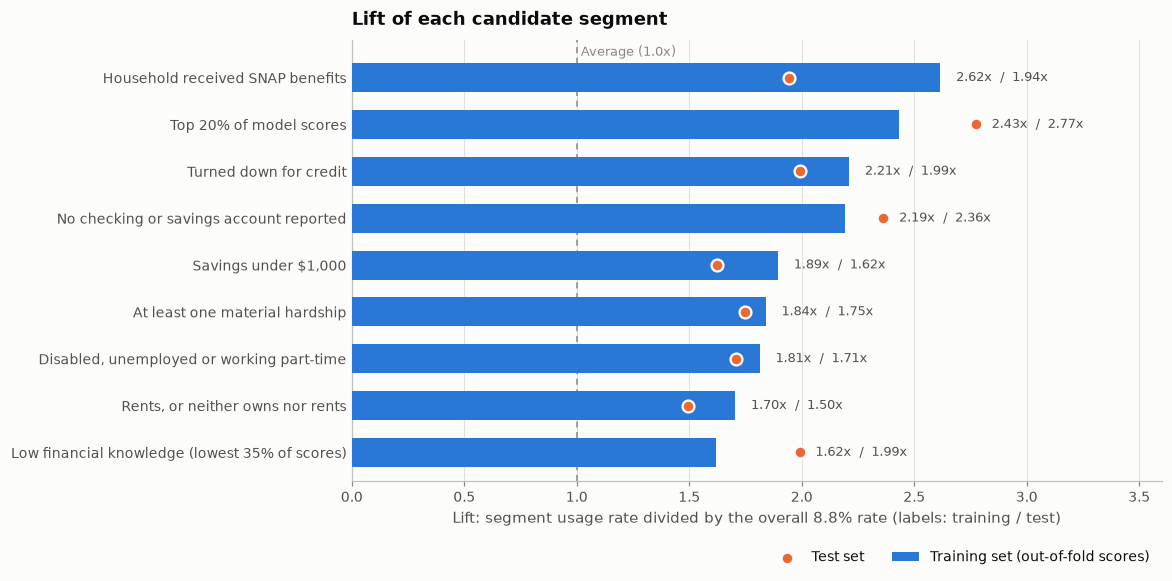

In [75]:
order = train_segments.sort_values("Lift").index
y_pos = np.arange(len(order))
fig, ax = plt.subplots(figsize=(9.5, 5.2))
ax.barh(y_pos, train_segments.loc[order, "Lift"], height=0.62, color=BLUE, zorder=3, label="Training set (out-of-fold scores)")
ax.scatter(test_segments.loc[order, "Lift"], y_pos, s=60, color=ORANGE, edgecolor=SURFACE, linewidth=1.5, zorder=4, label="Test set")
for i, seg in enumerate(order):
    right = max(train_segments.loc[seg, "Lift"], test_segments.loc[seg, "Lift"])
    ax.text(right + 0.07, i, f"{train_segments.loc[seg, 'Lift']:.2f}x  /  {test_segments.loc[seg, 'Lift']:.2f}x", va="center", fontsize=8.5, color=INK2)
ax.axvline(1, color=MUTED, linewidth=1, linestyle=(0, (4, 3)))
ax.text(1.0, len(order) - 0.45, " Average (1.0x)", fontsize=8.5, color=MUTED, va="center")
ax.set_yticks(y_pos, order)
ax.set_xlim(0, 3.6)
ax.set_ylim(-0.6, len(order) - 0.2)
ax.set_xlabel("Lift: segment usage rate divided by the overall 8.8% rate (labels: training / test)")
ax.set_title("Lift of each candidate segment")
ax.grid(axis="y", visible=False)
ax.tick_params(axis="y", length=0)
ax.legend(loc="upper right", bbox_to_anchor=(1.0, -0.13), ncol=2)
fig.savefig(FIG_DIR / "20_target_segments.png")
plt.show()

In [76]:
def score_deciles(y, score):
    out = pd.DataFrame({"y": np.asarray(y), "score": np.asarray(score)}).sort_values("score", ascending=False).reset_index(drop=True)
    out["Score decile (1 = highest)"] = np.arange(len(out)) * 10 // len(out) + 1
    t = out.groupby("Score decile (1 = highest)").agg(People=("y", "size"), Users=("y", "sum"), Usage_rate=("y", "mean"))
    t["Cumulative share of users"] = t["Users"].cumsum() / out["y"].sum()
    return t


deciles = score_deciles(y_train, train_scores["score_chosen"]).add_suffix(" (train)").join(
    score_deciles(y_test, test_scores["score_chosen"]).add_suffix(" (test)"))
display(fmt(deciles, {"Usage_rate (train)": "{:.1%}", "Cumulative share of users (train)": "{:.1%}",
                      "Usage_rate (test)": "{:.1%}", "Cumulative share of users (test)": "{:.1%}"}))

users = train_raw[train_raw["PRODUSE_3"] == 1]
flagged_users = train_raw[(train_scores["score_chosen"] >= threshold) & (train_raw["PRODUSE_3"] == 1)]
print(f"Of the {len(users)} prepaid users in the training set, {users['PRODHAVE_1'].mean():.1%} have a checking or savings account "
      f"and {(users['PPINCIMP'] >= 3).mean():.1%} have household income of $30,000 or more.")
missed_users = train_raw[(train_scores["score_chosen"] < threshold) & (train_raw["PRODUSE_3"] == 1)]
print(f"Of the {len(flagged_users)} users inside the top 20% of scores, {flagged_users['PRODHAVE_1'].mean():.1%} have an account.")
print(f"Of the {len(missed_users)} users outside the top 20%, {missed_users['PRODHAVE_1'].mean():.1%} have an account.")

,People (train),Users (train),Usage_rate (train),Cumulative share of users (train),People (test),Users (test),Usage_rate (test),Cumulative share of users (test)
Score decile (1 = highest),,,,,,,,
1,510,133,26.1%,29.7%,128,35,27.3%,31.2%
2,509,85,16.7%,48.7%,127,25,19.7%,53.6%
3,509,57,11.2%,61.4%,128,11,8.6%,63.4%
4,510,44,8.6%,71.2%,127,11,8.7%,73.2%
5,509,36,7.1%,79.2%,127,4,3.1%,76.8%
6,509,26,5.1%,85.0%,128,7,5.5%,83.0%
7,510,16,3.1%,88.6%,127,9,7.1%,91.1%
8,509,20,3.9%,93.1%,128,4,3.1%,94.6%
9,509,18,3.5%,97.1%,127,6,4.7%,100.0%


Of the 448 prepaid users in the training set, 69.2% have a checking or savings account and 61.4% have household income of $30,000 or more.
Of the 218 users inside the top 20% of scores, 48.2% have an account.
Of the 230 users outside the top 20%, 89.1% have an account.


**Takeaways**

- **The model score is the best single way to target.** The top 20% of scores has a usage rate of 21.4% on training data (2.43 times the average) and 24.4% on the test set (2.77 times). The top two score deciles hold 48.7% of all users in training and 53.6% in the test set. Below the top 20% the advantage fades quickly: the third decile is at 11.2% in training and 8.6% in the test set, and every lower decile is at or below the 8.8% average.
- **Every single-rule segment beats the average,** by 1.6 to 2.6 times in training and 1.5 to 2.4 times in the test set.
- **Small segments are unstable.** SNAP households have the highest lift in training (23.0%, 2.62 times) but 17.1% (1.94 times) among the 123 in the test set. "No bank account reported" is the most consistent: 19.3% and 20.8%.
- **Size trades off against lift.** The largest segment, people who rent or neither own nor rent (34% of everyone), has the weakest training lift after low knowledge (1.70 times).
- **Most users are not in these segments at all.** 69.2% of prepaid users have a bank account and 61.4% have household income of \$30,000 or more. Inside the top 20% only 48.2% of users have an account; the 230 users the rule misses are 89.1% banked. The rule is good at finding fragile users and poor at finding mainstream ones.

---
## 4. Reachability: what can a card company actually observe?

The model uses survey answers. A card company cannot ask a prospect how many hardships they faced last year. Part 2 marked each predictor by how realistically a company could know it about a prospect (the team's judgement, recorded in `data/selected_features.csv`):

- **Yes:** routinely available, such as stated income, home ownership, and debt-collection activity from a credit bureau.
- **Partly:** available in some settings, such as on an application form or from a partner (bank-account status, employment, credit rejections, payment history).
- **Survey only:** not observable (savings, hardship, SNAP, financial knowledge, well-being, shocks).

The same model is refitted on three sets of predictors and judged on the same top-20% rule. The second set is the optimistic case and the third is the conservative case.

In [77]:
availability = features["available_to_card_company"]
predictor_sets = {
    f"All {len(features)} predictors (survey)": features.index.tolist(),
    f"Yes + Partly observable ({(availability != 'Survey only').sum()})": availability.index[availability != "Survey only"].tolist(),
    f"Yes only ({availability.str.startswith('Yes').sum()})": availability.index[availability.str.startswith("Yes")].tolist(),
}
for label, cols in predictor_sets.items():
    print(f"{label}: {', '.join(cols)}")

rows = []
for label, cols in predictor_sets.items():
    if len(cols) == len(features):
        oof, test = train_scores["score_chosen"].to_numpy(), test_scores["score_chosen"].to_numpy()
    else:
        oof, test = subset_scores(cols)
    rows += top20_rows(label, oof, test)
reachability = pd.DataFrame(rows)
full_lift = reachability[reachability["Predictors used"] == f"All {len(features)} predictors (survey)"].set_index("File")["Lift"]
reachability["Lift kept vs all"] = reachability["Lift"] / reachability["File"].map(full_lift)
display(fmt(reachability, {"Share flagged": "{:.1%}", "Usage rate among flagged": "{:.1%}", "Recall (share of users caught)": "{:.1%}",
                           "Lift": "{:.2f}x", "Lift kept vs all": "{:.0%}"}))

All 17 predictors (survey): PPINCIMP, PPEDUC, HOUSING, EMPLOY, PRODHAVE_1, PRODHAVE_4, PRODHAVE_3, SAVINGSRANGES, ABSORBSHOCK, VOLATILITY, HARDSHIP_COUNT, COLLECT, REJECTED_1, SHOCKS_COUNT, KHscore, FWBscore, MANAGE1_1
Yes + Partly observable (10): PPINCIMP, PPEDUC, HOUSING, EMPLOY, PRODHAVE_1, PRODHAVE_4, PRODHAVE_3, COLLECT, REJECTED_1, MANAGE1_1
Yes only (3): PPINCIMP, HOUSING, COLLECT


,Predictors used,File,People flagged,Share flagged,Usage rate among flagged,Recall (share of users caught),Lift,Lift kept vs all
0,All 17 predictors (survey),Training (out-of-fold),1019,20.0%,21.4%,48.7%,2.43x,100%
1,All 17 predictors (survey),Test,246,19.3%,24.4%,53.6%,2.77x,100%
2,Yes + Partly observable (10),Training (out-of-fold),1019,20.0%,21.2%,48.2%,2.41x,99%
3,Yes + Partly observable (10),Test,265,20.8%,21.1%,50.0%,2.40x,87%
4,Yes only (3),Training (out-of-fold),1019,20.0%,19.9%,45.3%,2.26x,93%
5,Yes only (3),Test,264,20.7%,17.8%,42.0%,2.03x,73%


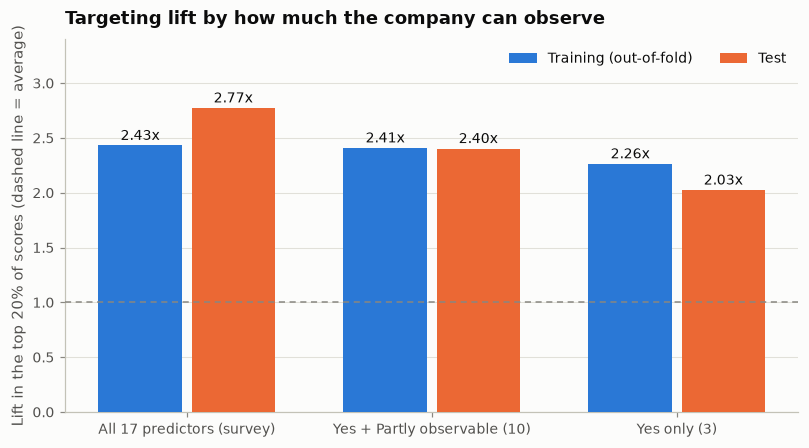

In [78]:
pivot = reachability.pivot(index="Predictors used", columns="File", values="Lift").loc[list(predictor_sets)]
x = np.arange(len(pivot))
fig, ax = plt.subplots(figsize=(8.6, 4.4))
for offset, (col, colour) in zip([-0.19, 0.19], [("Training (out-of-fold)", BLUE), ("Test", ORANGE)]):
    bars = ax.bar(x + offset, pivot[col], width=0.34, color=colour, label=col, zorder=3)
    for xi, v in zip(x + offset, pivot[col]):
        ax.text(xi, v + 0.05, f"{v:.2f}x", ha="center", fontsize=9, color=INK)
ax.axhline(1, color=MUTED, linewidth=1, linestyle=(0, (4, 3)), zorder=4)
ax.set_xticks(x, pivot.index)
ax.set_ylim(0, 3.4)
ax.set_ylabel("Lift in the top 20% of scores (dashed line = average)")
ax.set_title("Targeting lift by how much the company can observe")
ax.grid(axis="x", visible=False)
ax.legend(loc="upper right", ncol=2)
fig.savefig(FIG_DIR / "21_reachability_lift.png")
plt.show()

**Takeaways**

- **With everything a company could observe or partly observe (10 predictors),** the top 20% has a lift of 2.41 on training data, 99% of the full model's 2.43. On the test set it is 2.40 against 2.77, or 87%. It reaches 48.2% and 50.0% of users.
- **With only what a company clearly has (3 predictors: income, housing, debt-collection contact),** lift is 2.26 on training data and 2.03 on the test set, 93% and 73% of the full model. It reaches 45.3% and 42.0% of users.
- **How to read the gap between training and test.** The training figures rest on 448 users and are the steadier guide; the test set has 112, and the full model's 2.77 there was itself above its training value. A fair expectation for an observable-only campaign is a lift of about **2.0 to 2.4 times**, against about 2.4 to 2.8 with survey data.
- **The survey-only measures are not needed for reach.** Knowledge, savings, hardship and shocks cannot be seen for a prospect, and dropping them costs between 1% and 27% of the lift depending on how much else the company knows.
- **The 10-predictor case is optimistic.** It assumes application or partner data (bank-account status, employment, credit rejections, payment history). For cold prospecting from marketing lists, the 3-predictor case is the realistic one.

---
## 5. Recommended marketing and origination strategy

The model supports a **needs-aware, transparent acquisition strategy**. It is a ranking tool for deciding where to make a clearly explained offer. It is not an approval rule and not a basis for pricing.

Each recommendation below states the evidence it rests on. Where a recommendation is a reasoned business proposal that the data cannot test, it says so.

In [79]:
t20 = test_segments.loc["Top 20% of model scores"]
tr20 = train_segments.loc["Top 20% of model scores"]
recall_test = t20["Users"] / int(y_test.sum())
recall_train = tr20["Users"] / int(y_train.sum())
opportunity = pd.DataFrame({
    "Training (out-of-fold)": [f"{len(y_train):,}", f"{int(y_train.sum())}", f"{int(tr20['People']):,} ({tr20['Share of file']:.1%})", f"{int(tr20['Users'])} ({recall_train:.1%})",
                               f"{tr20['Usage rate']:.1%}", f"{tr20['Lift']:.2f}x", f"{1 - tr20['Usage rate']:.1%}"],
    "Test": [f"{len(y_test):,}", f"{int(y_test.sum())}", f"{int(t20['People']):,} ({t20['Share of file']:.1%})", f"{int(t20['Users'])} ({recall_test:.1%})",
             f"{t20['Usage rate']:.1%}", f"{t20['Lift']:.2f}x", f"{1 - t20['Usage rate']:.1%}"],
}, index=["Respondents", "Prepaid users", "Flagged by the top-20% rule", "Users among those flagged (share of all users)",
          "Usage rate among those flagged", "Lift over the 8.8% average", "Flagged people who are not users"])
print("Size of the opportunity under the top-20% rule:")
display(opportunity)

flag = train_scores["score_chosen"] >= threshold
traits = {"At least one material hardship": train_raw["HARDSHIP_COUNT"] >= 1, "Savings under $1,000": train_raw["SAVINGSRANGES"] <= 3,
          "Household income under $30,000": train_raw["PPINCIMP"] <= 2, "No checking or savings account reported": train_raw["PRODHAVE_1"] == 0,
          "Contacted by a debt collector": train_raw["COLLECT"] == 1, "Household received SNAP benefits": train_raw["SNAP"] == 1}
fragility = pd.DataFrame({k: {"Flagged (top 20%)": v[flag].mean(), "Not flagged": v[~flag].mean(), "Everyone": v.mean()} for k, v in traits.items()}).T
print("Who the rule flags (training set): share of each group with the characteristic")
display(fmt(fragility, "{:.1%}"))

Size of the opportunity under the top-20% rule:


,Training (out-of-fold),Test
Respondents,"5,093","1,274"
Prepaid users,448,112
Flagged by the top-20% rule,"1,019 (20.0%)",246 (19.3%)
Users among those flagged (share of all users),218 (48.7%),60 (53.6%)
Usage rate among those flagged,21.4%,24.4%
Lift over the 8.8% average,2.43x,2.77x
Flagged people who are not users,78.6%,75.6%


Who the rule flags (training set): share of each group with the characteristic


,Flagged (top 20%),Not flagged,Everyone
At least one material hardship,72.6%,17.6%,28.6%
"Savings under $1,000",61.0%,14.5%,23.8%
"Household income under $30,000",58.9%,9.2%,19.2%
No checking or savings account reported,45.5%,6.2%,14.0%
Contacted by a debt collector,39.4%,6.8%,13.3%
Household received SNAP benefits,34.8%,3.3%,9.6%


| Decision | Recommendation | Evidence | Basis |
|---|---|---|---|
| **Who to target** | The top 20% of model scores. | Test set: 246 people flagged, 60 of 112 users reached (53.6%), usage rate 24.4%, lift 2.77. Training: 48.7% of users, lift 2.43 (Section 3). | Data |
| **How to find them** | Score prospects on observable data: bank-account status, housing, income, debt-collection contact, credit rejections. | Observable-only models keep a lift of 2.0 to 2.4 (Section 4). The largest weights are observable: bank account 0.58, debt collector 1.47, renting 1.63 (Section 2). | Data |
| **Second audience** | Run a separate, mainstream campaign for banked customers. Do not define the market as "the unbanked". | 69.2% of users have a bank account. The 230 users outside the top 20% are 89.1% banked (Section 3). | Data |
| **Channels** | Benefits and payroll partners, and community or credit-counselling referrals, alongside digital acquisition. | SNAP households use at 23.0% in training and 17.1% in test; disabled, unemployed and part-time workers at 16.0% and 15.0% (Section 3). The survey does not record how anyone was reached, so channel effectiveness is untested. | Reasoned proposal |
| **Message** | Lead with clear, predictable fees, direct deposit and budgeting control. No urgency or scarcity appeals. | The flagged group is financially fragile: 72.6% report a hardship, 61.0% have under \$1,000 saved, 58.9% have income under \$30,000 (table below). | Data on who; proposal on wording |
| **Origination** | Use the score to decide who gets an offer, never as an approval, pricing or fee rule. Offer a low-fee or fee-free path, and point to a basic bank account where that is cheaper. | 75.6% of flagged people in the test set are not users. Scores are rankings, not probabilities (Part 3). The outcome records use, not fees paid or ability to pay. | Data on limits; proposal on design |
| **Measurement** | Pilot before scaling. Track take-up, repeat use, fees paid, complaints and outcomes by group. | Results move between samples: SNAP lift 2.62 in training, 1.94 in test; Part 3's interval for the test ROC-AUC is 0.699 to 0.794. | Data |

---
## 6. Responsible marketing

Race/ethnicity is not a predictor and must not be used to select who receives an offer. That does not make the targeting rule race-neutral in its effect: income, housing, bank-account access and credit distress are unevenly distributed across groups, so a rule built on them reaches some groups far more than others. The table below shows who the top-20% rule reaches.

In [80]:
profile_train, profile_test = load_profile()
RACE = {1: "White, non-Hispanic", 2: "Black, non-Hispanic", 3: "Other, non-Hispanic", 4: "Hispanic"}


def reach_by_group(profile, y, scores):
    d = pd.DataFrame({"group": profile["PPETHM"].map(RACE), "flagged": scores["score_chosen"] >= threshold, "user": y})
    t = d.groupby("group").agg(People=("user", "size"), Share_flagged=("flagged", "mean"), Usage_rate=("user", "mean"))
    t["Usage rate among flagged"] = d[d["flagged"]].groupby("group")["user"].mean()
    return t.loc[list(RACE.values())]


reach = reach_by_group(profile_train, y_train, train_scores).add_suffix(" (train)").join(
    reach_by_group(profile_test, y_test, test_scores).add_suffix(" (test)"))
display(fmt(reach, {"People (train)": "{:,}", "Share_flagged (train)": "{:.1%}", "Usage_rate (train)": "{:.1%}", "Usage rate among flagged (train)": "{:.1%}",
                    "Share_flagged (test)": "{:.1%}", "Usage_rate (test)": "{:.1%}", "Usage rate among flagged (test)": "{:.1%}"}))

,People (train),Share_flagged (train),Usage_rate (train),Usage rate among flagged (train),People (test),Share_flagged (test),Usage_rate (test),Usage rate among flagged (test)
group,,,,,,,,
"White, non-Hispanic","3,586",12.6%,6.2%,17.9%,898,11.8%,4.9%,15.1%
"Black, non-Hispanic",536,42.2%,18.3%,28.3%,145,48.3%,20.0%,30.0%
"Other, non-Hispanic",270,20.0%,8.5%,7.4%,65,24.6%,9.2%,25.0%
Hispanic,701,40.8%,14.7%,24.1%,166,32.5%,19.9%,35.2%


**Takeaways**

- **The rule reaches Black and Hispanic respondents about three times as often as White respondents.** It flags 42.2% of Black and 40.8% of Hispanic respondents against 12.6% of White respondents in training (48.3%, 32.5% and 11.8% in the test set).
- **Part of that reflects real differences in use.** Usage rates are 18.3% (Black), 14.7% (Hispanic) and 6.2% (White) in training. The reach gap (3.3 times for Black against White respondents) is somewhat wider than the usage gap (3.0 times).
- **The rule is not flagging these groups on weaker evidence.** Among people flagged, 28.3% of Black and 24.1% of Hispanic respondents are users, against 17.9% of White respondents. The disparity comes from how income, housing, bank-account access and credit distress are distributed, not from the model treating groups differently.
- **The "Other, non-Hispanic" group is too small to read** (270 people in training, 65 in test; its flagged-usage rate swings from 7.4% to 25.0%).
- **What this means for the company.** A campaign built on this rule will fall disproportionately on Black and Hispanic households that are also financially fragile. Offer identical terms to everyone flagged, monitor offers, fees and complaints by group, and keep fees low. This is taken further in Part 5 (CFPB).

---
## 7. Conclusions and limitations for the card company

**Conclusions**

1. **A targeting strategy is supportable, as a ranking tool.** Scoring prospects and contacting the top 20% reaches about half of all prepaid users at 2.4 to 2.8 times the average usage rate.
2. **It works on observable data.** Bank-account status, housing, income and credit distress give a lift of 2.0 to 2.4 without any survey answers.
3. **There are two markets.** The model finds financially fragile users. Most users are banked and mainstream, and the model does not find them; they need a separate proposition.
4. **The commercial opportunity and the consumer-protection risk are the same people.** Those most likely to take the product are the least able to absorb fees, and they are disproportionately Black and Hispanic. Fee transparency and low-cost design are part of the strategy.

**Limitations**

- **Moderate accuracy.** Three in four people flagged are not users, and about half of users are missed.
- **Results vary between samples.** Segment rates differ between training and test, especially for small segments; the test set has only 112 users.
- **The observability labels are the team's judgement,** not a fact about any particular company's data.
- **The outcome is use, not value.** The survey does not record how often cards were used, what fees were paid, or whether the product suited the person, so nothing here measures profitability.
- **2016, self-reported, unweighted.** The figures describe this sample, are not national estimates, and may not reflect today's prepaid market.
- **Associations, not causes.** A high weight means two things go together, not that one produces the other.

#### Hand-off

- **Task D (CFPB)** should take up the reach-by-group table in Section 6 and the overlap between the best prospects and the financially fragile.
- `score_chosen` in `data/train_oof_scores.csv` is the leakage-safe ranking for profiling; `data/test_scores.csv` is the confirmation set. The top-20% rule is `score_chosen >= 0.602`.
- Figures saved by this part: `figures/19_score_associations.png`, `figures/20_target_segments.png`, `figures/21_reachability_lift.png`.

# Part 5: CFPB at-risk groups, policy recommendations and project conclusions

*Lead: Anirudh Gopalan.*

**Question.** Given potential high fees, and concerns about unsophisticated users, can we identify at-risk groups? What policies can we prescribe to protect them?

**Purpose.** Use the chosen model from Part 3 and the survey's knowledge, hardship and banking measures to define who is at risk, size those groups, test the "unsophisticated user" concern directly, check whether the targeting rule falls unevenly on racial and ethnic groups, and turn the evidence into specific protections. The last section draws conclusions and limitations for the whole project.

| Section | What it delivers |
|---|---|
| 1. Setup | The shared split, the chosen model's scores and the cleaned survey columns |
| 2. Defining "at risk" | The two conditions (likely to use, vulnerable) and why each marker was chosen |
| 3. Size and profile of the at-risk groups | How many people, their usage rate, and who they are |
| 4. The knowledge and confidence gap | How far users' tested knowledge falls short of their self-assessment |
| 5. Fairness audit of the model | Selection, error rates and calibration by race/ethnicity, sex and age; proxy check; what drives the gap; mitigations; intersections |
| 6. Policy recommendations | Each protection tied to the group it protects and the evidence |
| 7. Conclusions and limitations for the whole project | What the project shows, and what it cannot show |

### Summary

- **Yes, at-risk groups can be identified, and they are sizeable.** "At risk" means likely to use a prepaid card (top 20% of model scores, or already a user) **and** vulnerable (at least two of: low financial knowledge, household income under \$30,000, savings under \$1,000, a material hardship, no bank account). That is **996 people, 19.6% of the training set, and they include 62.9% of all prepaid users** (test set: 238 people, 18.7%, 63.4% of users). Their usage rate is 28.3%, 3.22 times the 8.8% average.
- **Risk compounds.** Usage rises from 4.2% among people with none of the five markers to 30.2% among those with all five (test set: 3.7% to 36.7%). **90.3% of the people the targeting rule flags are vulnerable** (92.3% in the test set), so the card company's best prospects and the CFPB's at-risk population are largely the same people.
- **Specific groups to protect** (among people the model flags, training set): the **unbanked**, for whom the card is likely their main account (464 people, usage 24.4%; test 31.0%); people with **low knowledge who are also financially stretched** (643, 23.8%); **low-income households** (600, 22.2%); **low-knowledge users who rate their own knowledge highly** (337, 20.2%); people **also using payday, pawn or check-cashing services** (299, 18.7%); and **SNAP households** (355, 26.8% in training, 20.2% in test).
- **The "unsophisticated user" concern is real, and users underrate it.** On tested knowledge users score 0.51 standard deviations below non-users on average; on self-ratings, only 0.23. They rank themselves 10.7 percentile points higher on self-rated knowledge than their test result places them (non-users: −1.1). Half of low-knowledge users (50.2%) rate their knowledge 5 or more out of 7, the same as low-knowledge non-users (52.8%), so **self-assessment cannot pick them out.**
- **Vulnerable users report worse treatment:** 36.3% felt mistreated by financial services sometimes or often (non-users 17.4%), and 51.3% are not at all familiar with any agency that resolves problems.
- **The targeting rule is not neutral in effect, by race/ethnicity or by sex.** It ranks people about equally well within each racial/ethnic group (ROC-AUC 0.69 to 0.72 for White, Black and Hispanic respondents). However, **37.0% of Black and 36.3% of Hispanic non-users are flagged, against 11.1% of White non-users** (3.3 times as often for both), so they would receive marketing for a product they do not use far more often. This follows real differences in usage and vulnerability: at the same score, Black and Hispanic respondents use prepaid cards *more*. **Women are flagged more than men (22.5% against 17.8%) although usage is identical (8.7% against 8.9%),** and 44.6% of Hispanic women non-users are flagged.
- **The disparity cannot be engineered out of the inputs.** The 17 inputs identify Black or Hispanic respondents (ROC-AUC 0.763) better than they predict prepaid use. Financial knowledge, housing, income and bank access drive most of the gap. This version of the project removes the three predictors that are prohibited bases under ECOA (age, marital status, SNAP). That costs no accuracy, but it hardly changes who is flagged, and the Hispanic gap widens slightly because age had been narrowing it.
- **Policies tied to the evidence:** fee disclosure in plain dollars, tested for comprehension; limits on fees that penalise low balances; a fee-free path to a low-cost bank account; outcome monitoring by race/ethnicity for issuers who use predictive targeting; complaint contacts on the card itself; and help delivered through benefit offices and community organisations. Section 6 separates what the data supports from what is a reasoned suggestion.

All results are associations in a 2016 self-reported survey, unweighted as the brief requires. They describe this sample; they are not causal effects or national estimates.

---
## 1. Setup

This part uses the fixed train/test split and 17 predictors from Part 2, and the chosen model's scores from Part 3. Nothing is re-split, re-cleaned or re-modelled.

Three views of the data are used, each for a different job:

- **Training set, out-of-fold scores (5,093 people):** the main file for anything that uses the model score. Each person was scored by a model that never saw them, so profiling is free of leakage.
- **Test set (1,274 people):** used only to confirm that the training patterns hold.
- **Full cleaned sample (6,367 people):** used for descriptions that do not involve the model score, such as the knowledge gap in Section 4. This matches Part 1.

Variables outside the 17 predictors (self-rated knowledge, experiences with financial services, other alternative-finance products) come from `data/cfpb_clean.csv`, joined on `PUF_ID`. Their value labels were taken from the CFPB codebook in `docs/`.

In [81]:
from pathlib import Path
import warnings

import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score, roc_auc_score
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

from prep import build_preprocessor, feature_lists, feature_table, load_profile, load_split

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=pd.errors.PerformanceWarning)
pd.set_option("display.max_columns", 60, "display.width", 220, "display.max_colwidth", 110, "display.max_rows", 100)

DATA_DIR = Path("data")
FIG_DIR = Path("figures")
FIG_DIR.mkdir(exist_ok=True)
SEED = 42
TOP_SHARE = 0.20          # the top-20% rule recommended in Part 3
MIN_MARKERS = 2           # "vulnerable" = at least two of the five markers defined in Section 2

INK, INK2, MUTED = "#0b0b0b", "#52514e", "#898781"
GRID, AXIS, SURFACE = "#e1e0d9", "#c3c2b7", "#fcfcfb"
BLUE, ORANGE = "#2a78d6", "#eb6834"
mpl.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "figure.dpi": 110, "savefig.dpi": 200, "savefig.bbox": "tight",
    "font.size": 10, "text.color": INK, "axes.labelcolor": INK2,
    "axes.titlesize": 11.5, "axes.titleweight": "bold", "axes.titlelocation": "left", "axes.titlepad": 10,
    "axes.edgecolor": AXIS, "axes.linewidth": 0.8, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "axes.axisbelow": True, "grid.color": GRID, "grid.linewidth": 0.7,
    "xtick.color": MUTED, "ytick.color": MUTED, "xtick.labelcolor": INK2, "ytick.labelcolor": INK2,
    "xtick.labelsize": 9, "ytick.labelsize": 9, "legend.frameon": False, "legend.fontsize": 9,
})


def fmt(df, formats, hide_index=False):
    """Return a display copy of a table with numbers formatted as text."""
    out = df.copy()
    if isinstance(formats, str):
        formats = {c: formats for c in out.columns if pd.api.types.is_numeric_dtype(out[c])}
    for col, pattern in formats.items():
        if col in out.columns:
            out[col] = out[col].map(lambda v, p=pattern: p.format(v) if pd.notna(v) else "")
    return out.reset_index(drop=True) if hide_index else out


def interval(k, n, z=1.96):
    """95% Wilson interval for a rate of k out of n, as text. Small groups give wide intervals."""
    p, den = k / n, 1 + z ** 2 / n
    centre, half = (p + z ** 2 / (2 * n)) / den, z * np.sqrt(p * (1 - p) / n + z ** 2 / (4 * n ** 2)) / den
    return f"{centre - half:.1%} to {centre + half:.1%}"


X_train, X_test, y_train, y_test = load_split()
profile_train, profile_test = load_profile()
train_scores = pd.read_csv(DATA_DIR / "train_oof_scores.csv", index_col="PUF_ID")
test_scores = pd.read_csv(DATA_DIR / "test_scores.csv", index_col="PUF_ID")
clean = pd.read_csv(DATA_DIR / "cfpb_clean.csv", index_col="PUF_ID")

assert train_scores.index.equals(X_train.index) and test_scores.index.equals(X_test.index)
assert clean.index.is_unique and set(clean.index) == set(X_train.index) | set(X_test.index)
assert (clean.loc[y_train.index, "PRODUSE_3"] == y_train).all() and (clean.loc[y_test.index, "PRODUSE_3"] == y_test).all()

threshold = float(np.quantile(train_scores["score_chosen"], 1 - TOP_SHARE))
KNOWLEDGE_CUT = float(X_train["KHscore"].quantile(0.25))   # same cut-off as Part 4, fixed on the training set
RACE = {1: "White, non-Hispanic", 2: "Black, non-Hispanic", 3: "Other, non-Hispanic", 4: "Hispanic"}

MARKERS = {
    "Low financial knowledge": lambda d: d["KHscore"] <= KNOWLEDGE_CUT,
    "Household income under $30,000": lambda d: d["PPINCIMP"] <= 2,
    "Savings under $1,000": lambda d: d["SAVINGSRANGES"] <= 3,
    "At least one material hardship": lambda d: d["HARDSHIP_COUNT"] >= 1,
    "No checking or savings account": lambda d: d["PRODHAVE_1"] == 0,
}


def analysis_frame(ids, scores=None, profile=None):
    """Cleaned survey columns plus the five markers, their count, and (if given) the model score and race/ethnicity."""
    d = clean.loc[ids]
    extra = {"user": d["PRODUSE_3"] == 1}
    extra.update({name: rule(d) for name, rule in MARKERS.items()})   # a missing answer counts as "marker absent"
    extra["markers"] = sum(extra[name].astype(int) for name in MARKERS)
    extra["vulnerable"] = extra["markers"] >= MIN_MARKERS
    if scores is not None:
        extra["score"] = scores["score_chosen"]
        extra["flagged"] = scores["score_chosen"] >= threshold
        extra["at_risk"] = (extra["flagged"] | extra["user"]) & extra["vulnerable"]
    if profile is not None:
        extra["race"] = profile["PPETHM"].map(RACE)
    return pd.concat([d, pd.DataFrame(extra, index=d.index)], axis=1)


train = analysis_frame(X_train.index, train_scores, profile_train)
test = analysis_frame(X_test.index, test_scores, profile_test)
full = analysis_frame(clean.index, profile=clean[["PPETHM"]])

print(f"Training: {len(train):,} respondents, {int(train['user'].sum())} prepaid users ({train['user'].mean():.1%})")
print(f"Test:     {len(test):,} respondents, {int(test['user'].sum())} prepaid users ({test['user'].mean():.1%})")
print(f"Full cleaned sample: {len(full):,} respondents, {int(full['user'].sum())} prepaid users ({full['user'].mean():.1%})")
print(f"Top-{TOP_SHARE:.0%} rule from Part 3: score_chosen >= {threshold:.3f} (cut-off fixed on training scores)")
print(f"Low financial knowledge: KHscore <= {KNOWLEDGE_CUT} (training 25th percentile; covers {(X_train['KHscore'] <= KNOWLEDGE_CUT).mean():.1%} of training respondents)")
print(f"Savings answer missing ('prefer not to say' or 'don't know'): {train['SAVINGSRANGES'].isna().mean():.1%} of training respondents")

Training: 5,093 respondents, 448 prepaid users (8.8%)
Test:     1,274 respondents, 112 prepaid users (8.8%)
Full cleaned sample: 6,367 respondents, 560 prepaid users (8.8%)
Top-20% rule from Part 3: score_chosen >= 0.602 (cut-off fixed on training scores)
Low financial knowledge: KHscore <= -0.57 (training 25th percentile; covers 34.8% of training respondents)
Savings answer missing ('prefer not to say' or 'don't know'): 18.2% of training respondents


---
## 2. Defining "at risk"

**The CFPB uses the score differently from the card company.** The company wants to *find* likely users, so it cares about precision in the top scores. The CFPB wants to *protect* vulnerable ones, and the costs of its mistakes are lopsided: aiming a protection at people who turn out not to be at risk costs little, but missing an at-risk group leaves it unprotected. So the CFPB should favour recall. That is why the definition below counts **actual users** as well as the model's flags: the model alone misses about half of users (Part 3).

**Prepaid use is not harmful in itself.** Many people choose prepaid cards to budget or to avoid overdraft fees. Harm comes from fees combined with a lack of sophistication or financial slack, so "at risk" must combine likely use with vulnerability, not use alone.

The CFPB's concern therefore has two parts, and the definition has two conditions. A person is **at risk** when both hold:

**Condition 1: likely to use a prepaid card.** Either the model places them in the **top 20% of scores** (the targeting rule from Part 3, `score_chosen >= 0.602`), or they **already use** one. The first captures the people a card company would market to; the second captures people already exposed to the fees.

**Condition 2: vulnerable to fees or poor decisions.** At least **two** of the five markers below. Each one is chosen because it makes fees harder to understand, harder to avoid, or harder to absorb:

| Marker | Rule | Why it signals vulnerability |
|---|---|---|
| Low financial knowledge | Knoll–Houts knowledge score in the bottom quarter of the training set (`KHscore <= -0.57`; covers 35% because the score takes only 11 values) | Fee schedules (monthly, reload, ATM, inactivity, decline fees) are hard to compare. This is the brief's "unsophisticated user". Same cut-off as Part 4. |
| Low income | Household income under \$30,000 (`PPINCIMP` 1–2) | The same flat fee takes a much larger share of a small income. |
| Little or no savings | Under \$1,000 in savings (`SAVINGSRANGES` 1–3) | No buffer: a fee or a declined transaction can tip a month into hardship. |
| Material hardship | At least one hardship sometimes or often, such as running out of food or a utility shut-off (`HARDSHIP_COUNT >= 1`) | Shows fees are already competing with essentials. |
| No bank account | No checking or savings account (`PRODHAVE_1 = 0`) | The prepaid card is likely the person's main account, so every deposit, withdrawal and payment can carry a fee. |

**Why two markers rather than one.** Each marker on its own is common (one in three people has low knowledge) and loosely tied to use. The table after next shows that usage rises steeply once markers stack up, and that the model flags very few people with fewer than two. Requiring two keeps the focus on people whose risks compound.

A missing answer is counted as "marker absent". This matters only for savings, where 18% did not give an amount, so the savings marker understates true low savings.

The first table checks each marker on its own: how common it is, and how much more often people with it use prepaid cards.

In [82]:
def marker_table(d):
    rows = []
    for name in MARKERS:
        has = d[name]
        rows.append({"Marker": name, "Share of file": has.mean(), "Usage rate with marker": d.loc[has, "user"].mean(),
                     "Usage rate without": d.loc[~has, "user"].mean(), "Share of users with marker": d.loc[d["user"], name].mean()})
    t = pd.DataFrame(rows).set_index("Marker")
    t["Ratio (with / without)"] = t["Usage rate with marker"] / t["Usage rate without"]
    return t


markers_tr, markers_te = marker_table(train), marker_table(test)
pct = "{:.1%}"
display(fmt(markers_tr.add_suffix(" (train)").join(markers_te[["Usage rate with marker", "Ratio (with / without)"]].add_suffix(" (test)")),
            {**{c: pct for c in ["Share of file (train)", "Usage rate with marker (train)", "Usage rate without (train)", "Share of users with marker (train)",
                                 "Usage rate with marker (test)"]},
             "Ratio (with / without) (train)": "{:.2f}x", "Ratio (with / without) (test)": "{:.2f}x"}))
print(f"Overall usage rate: {train['user'].mean():.1%} (train), {test['user'].mean():.1%} (test).")

,Share of file (train),Usage rate with marker (train),Usage rate without (train),Share of users with marker (train),Ratio (with / without) (train),Usage rate with marker (test),Ratio (with / without) (test)
Marker,,,,,,,
Low financial knowledge,34.8%,14.2%,5.9%,56.2%,2.41x,17.5%,4.17x
"Household income under $30,000",19.2%,17.7%,6.7%,38.6%,2.65x,17.5%,2.58x
"Savings under $1,000",23.8%,16.7%,6.3%,45.1%,2.63x,14.3%,2.00x
At least one material hardship,28.6%,16.2%,5.8%,52.7%,2.78x,15.4%,2.52x
No checking or savings account,14.0%,19.3%,7.1%,30.8%,2.73x,20.8%,3.21x


Overall usage rate: 8.8% (train), 8.8% (test).


**Takeaways**

- **Each marker on its own is associated with about 2.4 to 2.8 times the usage rate** of people without it in training (2.0 to 4.2 times in the test set). Usage rates with a marker range from 14.2% (low knowledge) to 19.3% (no bank account), against 8.8% overall.
- **No bank account has the highest usage rate** (19.3% in training, 20.8% in test) but covers only 30.8% of users. **Low financial knowledge is the most widespread:** it covers 34.8% of everyone and 56.2% of users. Hardship covers 52.7% of users.
- **The test-set ratios move around** (low knowledge 2.41 in training, 4.17 in test). The test set has only 112 users, so the training figures are the steadier guide.
- **Using markers that carry little weight in the model is deliberate.** Part 4 showed savings and hardship add almost nothing to the model's score once bank status, SNAP and credit distress are known. Here they do a different job: they describe how badly fees would hurt someone, not how likely that person is to use a card.

The next table counts how many markers each person has, and shows how usage and the model's targeting change as they stack up.

,People (train),Users (train),Usage_rate (train),Share_flagged (train),People (test),Users (test),Usage_rate (test),Share_flagged (test)
Number of markers (of 5),,,,,,,,
0,2220,94,4.2%,0.6%,535,20,3.7%,0.0%
1,1182,72,6.1%,7.2%,303,21,6.9%,6.3%
2,725,80,11.0%,28.6%,205,17,8.3%,24.9%
3,502,81,16.1%,58.2%,115,21,18.3%,62.6%
4,325,79,24.3%,87.4%,86,22,25.6%,86.0%
5,139,42,30.2%,98.6%,30,11,36.7%,100.0%


Training: 33.2% of people have 2+ markers; usage rate 16.7% with 2+ markers vs 4.9% with 0-1; 90.3% of those the model flags have 2+ markers.
Test: 34.2% of people have 2+ markers; usage rate 16.3% with 2+ markers vs 4.9% with 0-1; 92.3% of those the model flags have 2+ markers.


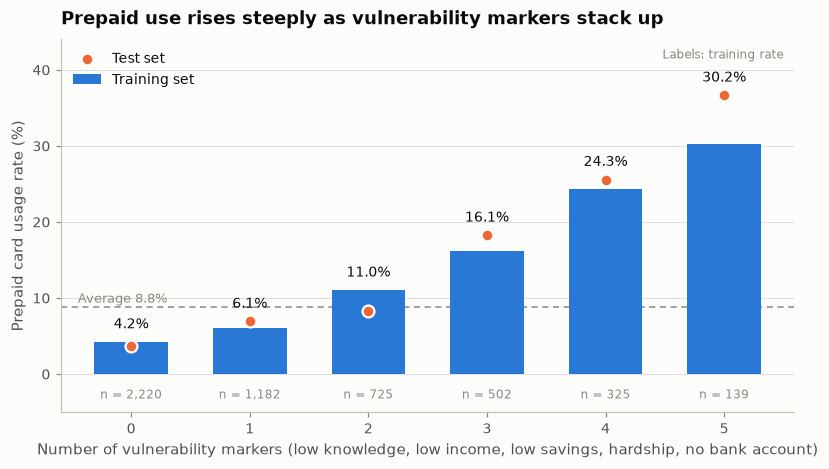

In [83]:
def stacking_table(d):
    t = d.groupby("markers").agg(People=("user", "size"), Users=("user", "sum"), Usage_rate=("user", "mean"), Share_flagged=("flagged", "mean"))
    t.index.name = "Number of markers (of 5)"
    return t


stack_tr, stack_te = stacking_table(train), stacking_table(test)
display(fmt(stack_tr.add_suffix(" (train)").join(stack_te.add_suffix(" (test)")),
            {c: pct for c in ["Usage_rate (train)", "Share_flagged (train)", "Usage_rate (test)", "Share_flagged (test)"]}))

for name, d in [("Training", train), ("Test", test)]:
    v = d["vulnerable"]
    print(f"{name}: {v.mean():.1%} of people have 2+ markers; usage rate {d.loc[v, 'user'].mean():.1%} with 2+ markers vs "
          f"{d.loc[~v, 'user'].mean():.1%} with 0-1; {d.loc[d['flagged'], 'vulnerable'].mean():.1%} of those the model flags have 2+ markers.")

fig, ax = plt.subplots(figsize=(8.6, 4.4))
x = np.arange(len(stack_tr))
ax.bar(x, stack_tr["Usage_rate"] * 100, width=0.62, color=BLUE, zorder=3, label="Training set")
ax.scatter(x, stack_te["Usage_rate"].reindex(stack_tr.index) * 100, s=60, color=ORANGE, edgecolor=SURFACE, linewidth=1.5, zorder=4, label="Test set")
for xi, (rate, n, rate_te) in enumerate(zip(stack_tr["Usage_rate"], stack_tr["People"], stack_te["Usage_rate"].reindex(stack_tr.index))):
    ax.text(xi, max(rate, rate_te) * 100 + 1.8, f"{rate:.1%}", ha="center", fontsize=9, color=INK)
    ax.text(xi, -3.2, f"n = {n:,}", ha="center", fontsize=8, color=MUTED)
base = train["user"].mean() * 100
ax.axhline(base, color=MUTED, linewidth=1, linestyle=(0, (4, 3)), zorder=2)
ax.text(-0.45, base + 0.6, f"Average {base:.1f}%", fontsize=8.5, color=MUTED)
ax.set_xticks(x, [str(i) for i in stack_tr.index])
ax.set_ylim(-5, 44)
ax.text(len(stack_tr) - 0.5, 41.5, "Labels: training rate", ha="right", fontsize=8, color=MUTED)
ax.set_xlabel("Number of vulnerability markers (low knowledge, low income, low savings, hardship, no bank account)")
ax.set_ylabel("Prepaid card usage rate (%)")
ax.set_title("Prepaid use rises steeply as vulnerability markers stack up")
ax.grid(axis="x", visible=False)
ax.legend(loc="upper left")
fig.savefig(FIG_DIR / "22_usage_by_vulnerability_markers.png")
plt.show()

**Takeaways**

- **Usage rises with every extra marker:** 4.2% with none, 6.1% with one, 11.0% with two, 16.1% with three, 24.3% with four and 30.2% with all five (training). The test set follows the same path, from 3.7% to 36.7%, with a dip at two markers (8.3%, on 17 users).
- **This is why the threshold is two markers.** One marker leaves usage below the 8.8% average (6.1%) and the model flags only 7.2% of such people. From two markers, usage is above average and the model starts to target people in earnest (28.6% flagged at two, 58.2% at three).
- **33.2% of training respondents have two or more markers.** Their usage rate is 16.7%, against 4.9% for everyone else (test: 34.2%, 16.3% and 4.9%).
- **The model's targets are overwhelmingly vulnerable.** 90.3% of the people the top-20% rule flags in training have two or more markers (92.3% in test). For the CFPB, a company following the Part 4 strategy would be marketing mainly to vulnerable people.

---
## 3. Size and profile of the at-risk groups

#### 3.1 The at-risk population

Three overlapping views of the same population:

- **At-risk prospects:** flagged by the model **and** vulnerable. These are the people a card company using the Part 3 rule would market to who are least able to absorb fees.
- **At-risk current users:** already use a prepaid card **and** are vulnerable. They are exposed to fees now, whether or not the model would find them.
- **All at risk:** either of the two.

For each, **lift** is the usage rate divided by the overall 8.8% rate, and **share of all users** is the fraction of every prepaid user in the file who falls in the group.

In [84]:
def population_table(d):
    groups = {"At-risk prospects (flagged and vulnerable)": d["flagged"] & d["vulnerable"],
              "At-risk current users (user and vulnerable)": d["user"] & d["vulnerable"],
              "All at risk (either)": d["at_risk"],
              "For reference: everyone flagged by the model": d["flagged"]}
    base, n_users = d["user"].mean(), d["user"].sum()
    rows = [{"Group": g, "People": int(m.sum()), "Share of file": m.mean(), "Users": int(d.loc[m, "user"].sum()),
             "Usage rate": d.loc[m, "user"].mean(), "95% interval": interval(d.loc[m, "user"].sum(), m.sum()), "Lift": d.loc[m, "user"].mean() / base,
             "Share of all users": d.loc[m, "user"].sum() / n_users} for g, m in groups.items()]
    return pd.DataFrame(rows).set_index("Group")


pop_tr, pop_te = population_table(train), population_table(test)
pop_formats = {"Share of file": pct, "Usage rate": pct, "Lift": "{:.2f}x", "Share of all users": pct}
print("Training set (out-of-fold scores):")
display(fmt(pop_tr, pop_formats))
print("Test set (confirmation):")
display(fmt(pop_te, pop_formats))
print("Usage rate is 100% for 'current users' by definition; it is shown only for completeness.")

flag_users = train["flagged"] & train["user"]
print(f"Training: of the {int(flag_users.sum())} users the model flags, {train.loc[flag_users, 'vulnerable'].mean():.1%} are vulnerable; "
      f"of the {int((train['user'] & ~train['flagged']).sum())} users it misses, {train.loc[train['user'] & ~train['flagged'], 'vulnerable'].mean():.1%} are.")

Training set (out-of-fold scores):


,People,Share of file,Users,Usage rate,95% interval,Lift,Share of all users
Group,,,,,,,
At-risk prospects (flagged and vulnerable),920,18.1%,206,22.4%,19.8% to 25.2%,2.55x,46.0%
At-risk current users (user and vulnerable),282,5.5%,282,100.0%,98.7% to 100.0%,11.37x,62.9%
All at risk (either),996,19.6%,282,28.3%,25.6% to 31.2%,3.22x,62.9%
For reference: everyone flagged by the model,1019,20.0%,218,21.4%,19.0% to 24.0%,2.43x,48.7%


Test set (confirmation):


,People,Share of file,Users,Usage rate,95% interval,Lift,Share of all users
Group,,,,,,,
At-risk prospects (flagged and vulnerable),227,17.8%,60,26.4%,21.1% to 32.5%,3.01x,53.6%
At-risk current users (user and vulnerable),71,5.6%,71,100.0%,94.9% to 100.0%,11.38x,63.4%
All at risk (either),238,18.7%,71,29.8%,24.4% to 35.9%,3.39x,63.4%
For reference: everyone flagged by the model,246,19.3%,60,24.4%,19.4% to 30.1%,2.77x,53.6%


Usage rate is 100% for 'current users' by definition; it is shown only for completeness.
Training: of the 218 users the model flags, 94.5% are vulnerable; of the 230 users it misses, 33.0% are.


**Takeaways**

- **The at-risk population is 996 people (19.6% of the training file) and holds 282 of the 448 prepaid users (62.9%).** Its usage rate is 28.3%, 3.22 times the average. The test set confirms it: 238 people (18.7%), 63.4% of users, 3.39 times.
- **At-risk prospects:** 920 people (18.1%) are both flagged and vulnerable, with a usage rate of 22.4% (2.55 times); test 227 people, 26.4% (3.01 times). About three in four are *not* current users, so they are the people a marketing campaign would newly reach.
- **Nearly two-thirds of current users are vulnerable.** This fits with Part 4's finding that 69.2% of users have a bank account: having an account does not stop someone being low-income, low-knowledge or in hardship.
- **The other 37% of users look like deliberate, mainstream users.** Section 4.1 shows that users with 0–1 markers report mistreatment, difficulty paying bills and use of other high-cost services at rates similar to or below non-users (the exception: 11.1% have reported a problem to an agency, against 6.5% of non-users). They plausibly use prepaid cards by choice, for example to budget. The survey does not ask why people use them, so this is an inference.
- **The model finds the vulnerable users and misses the rest.** 94.5% of the 218 users it flags are vulnerable, against 33.0% of the 230 users it misses. For the CFPB this matters: the people a model-driven campaign would reach are the people least able to absorb fees.

#### 3.2 Specific at-risk groups

The at-risk population is broad. The CFPB needs groups that a specific protection can be aimed at. Each group below is a plain rule applied to the people the model flags, so its usage rate shows how strongly it is targeted. The last column shows the share of **all** prepaid users who have the trait, flagged or not. Groups overlap: the same person can be unbanked, low-income and on SNAP, so sizes must not be added.

Two groups use variables outside the model: **other high-cost services** (payday loan, pawn or auto-title loan, or non-bank check cashing; `PRODUSE_1`, `2`, `5`) and **self-rated knowledge** (`SUBKNOWL1`, 1–7). These are profiling columns, not predictors.

In [85]:
OTHER_HIGH_COST = ["PRODUSE_1", "PRODUSE_2", "PRODUSE_5"]


def group_rules(d):
    low_k = d["Low financial knowledge"]
    return {
        "No bank account: card likely their main account": d["No checking or savings account"],
        "Low knowledge and financially stretched (low savings or hardship)": low_k & (d["Savings under $1,000"] | d["At least one material hardship"]),
        "Low knowledge but rates own knowledge 5+ of 7": low_k & (d["SUBKNOWL1"] >= 5),
        "Household income under $30,000": d["Household income under $30,000"],
        "Also uses payday, pawn/title loans or check cashing": (d[OTHER_HIGH_COST] == 1).any(axis=1),
        "Household receives SNAP benefits": d["SNAP"] == 1,
    }


def group_table(d):
    base, n_users = d["user"].mean(), d["user"].sum()
    rows = []
    for g, trait in group_rules(d).items():
        m = d["flagged"] & trait
        rows.append({"Group (among people the model flags)": g, "People": int(m.sum()), "Share of file": m.mean(),
                     "Usage rate": d.loc[m, "user"].mean(), "95% interval": interval(d.loc[m, "user"].sum(), m.sum()),
                     "Lift": d.loc[m, "user"].mean() / base,
                     "Share of all users with this trait": d.loc[d["user"], :].pipe(lambda u: trait[u.index].mean())})
    return pd.DataFrame(rows).set_index("Group (among people the model flags)")


groups_tr, groups_te = group_table(train), group_table(test)
display(fmt(groups_tr.add_suffix(" (train)").join(groups_te[["People", "Usage rate", "Lift"]].add_suffix(" (test)")),
            {"Share of file (train)": pct, "Usage rate (train)": pct, "Lift (train)": "{:.2f}x", "Share of all users with this trait (train)": pct,
             "Usage rate (test)": pct, "Lift (test)": "{:.2f}x"}))

,People (train),Share of file (train),Usage rate (train),95% interval (train),Lift (train),Share of all users with this trait (train),People (test),Usage rate (test),Lift (test)
Group (among people the model flags),,,,,,,,,
No bank account: card likely their main account,464,9.1%,24.4%,20.7% to 28.5%,2.77x,30.8%,126,31.0%,3.52x
Low knowledge and financially stretched (low savings or hardship),643,12.6%,23.8%,20.7% to 27.2%,2.71x,42.9%,158,27.2%,3.10x
Low knowledge but rates own knowledge 5+ of 7,337,6.6%,20.2%,16.2% to 24.8%,2.29x,27.0%,99,24.2%,2.76x
"Household income under $30,000",600,11.8%,22.2%,19.0% to 25.7%,2.52x,38.6%,138,27.5%,3.13x
"Also uses payday, pawn/title loans or check cashing",299,5.9%,18.7%,14.7% to 23.5%,2.13x,18.5%,79,17.7%,2.02x
Household receives SNAP benefits,355,7.0%,26.8%,22.4% to 31.6%,3.04x,25.2%,84,20.2%,2.30x


**Takeaways**

- **Every group is strongly targeted.** Usage rates are 2.1 to 3.0 times the average in training and 2.0 to 3.5 times in the test set. Even the lowest 95% interval (14.7% to 23.5%, other high-cost services) sits well above the 8.8% average, so no group's elevated rate is a fluke of sample size.
- **Unbanked (card likely their main account): 464 flagged people (9.1%), usage 24.4%, 2.77 times; test 126 people, 31.0%, 3.52 times.** This group has the most direct exposure to fees, because deposits, withdrawals and bill payments can each be charged. 30.8% of all users have no bank account.
- **Low knowledge and financially stretched: the largest specific group, 643 people (12.6%), usage 23.8%; test 158, 27.2%.** 42.9% of all users fit this description.
- **Low knowledge but confident: 337 people (6.6%), usage 20.2%; test 99, 24.2%.** 27.0% of all users. They are unlikely to look for help or read fee terms closely (Section 4).
- **Low income: 600 people (11.8%), usage 22.2%; test 138, 27.5%.** 38.6% of all users.
- **Also using payday, pawn/title loans or check cashing: 299 people (5.9%), usage 18.7%; test 79, 17.7%.** 18.5% of all users combine several high-cost products, so their fees add up across products.
- **SNAP households: 355 people (7.0%), 26.8% in training but 20.2% in test** (3.04 against 2.30 times). The group is small in the test set (84 people), so its rate moves between samples, as Part 4 also found.

#### 3.3 Who is in the at-risk population?

Share of each group with each characteristic, training set. Race/ethnicity comes from `load_profile()`; everything else from the cleaned survey. Codes follow the CFPB codebook.

In [86]:
def profile_traits(d):
    return {
        "White, non-Hispanic": d["race"] == RACE[1], "Black, non-Hispanic": d["race"] == RACE[2],
        "Hispanic": d["race"] == RACE[4], "Other, non-Hispanic": d["race"] == RACE[3],
        "Age 18-34": d["agecat"] <= 2, "Age 35-61": d["agecat"].between(3, 5), "Age 62 and over": d["agecat"] >= 6,
        "Female": d["PPGENDER"] == 2,
        "No bachelor's degree": d["PPEDUC"] <= 3,
        "Below the federal poverty line": d["fpl"] == 1,
        "Rents": d["HOUSING"] == 2,
        "Sick/disabled or unemployed": d["EMPLOY"].isin([6, 7]),
        "Household receives SNAP": d["SNAP"] == 1,
        "Finds it very difficult to cover monthly bills": d["ENDSMEET"] == 3,
        "Region: Northeast": d["PPREG4"] == 1, "Region: Midwest": d["PPREG4"] == 2,
        "Region: South": d["PPREG4"] == 3, "Region: West": d["PPREG4"] == 4,
        "Lives outside a metropolitan area": d["PPMSACAT"] == 0,
    }


groups ={"All at risk": train["at_risk"], "Not at risk": ~train["at_risk"], "Everyone": pd.Series(True, index=train.index)}
traits = profile_traits(train)
profile = pd.DataFrame({g: {t: v[m].mean() for t, v in traits.items()} for g, m in groups.items()})
profile["Ratio (at risk / not at risk)"] = profile["All at risk"] / profile["Not at risk"]
sizes = pd.DataFrame({g: [int(m.sum())] for g, m in groups.items()}, index=["People"])
display(sizes)
display(fmt(profile, {"All at risk": pct, "Not at risk": pct, "Everyone": pct, "Ratio (at risk / not at risk)": "{:.2f}x"}))

by_race = train.groupby("race").agg(People=("at_risk", "size"), Share_at_risk=("at_risk", "mean")).loc[list(RACE.values())]
by_race_te = test.groupby("race")["at_risk"].mean().rename("Share_at_risk (test)")
print("Share of each race/ethnicity group that is at risk:")
display(fmt(by_race.join(by_race_te), {"Share_at_risk": pct, "Share_at_risk (test)": pct}))

,All at risk,Not at risk,Everyone
People,996,4097,5093


,All at risk,Not at risk,Everyone,Ratio (at risk / not at risk)
"White, non-Hispanic",44.0%,76.8%,70.4%,0.57x
"Black, non-Hispanic",22.4%,7.6%,10.5%,2.93x
Hispanic,28.5%,10.2%,13.8%,2.80x
"Other, non-Hispanic",5.1%,5.3%,5.3%,0.96x
Age 18-34,40.9%,20.0%,24.1%,2.04x
Age 35-61,39.9%,40.5%,40.4%,0.98x
Age 62 and over,19.3%,39.4%,35.5%,0.49x
Female,53.5%,45.7%,47.3%,1.17x
No bachelor's degree,89.3%,55.5%,62.1%,1.61x
Below the federal poverty line,41.0%,3.1%,10.5%,13.43x


Share of each race/ethnicity group that is at risk:


,People,Share_at_risk,Share_at_risk (test)
race,,,
"White, non-Hispanic",3586,12.2%,11.4%
"Black, non-Hispanic",536,41.6%,48.3%
"Other, non-Hispanic",270,18.9%,20.0%
Hispanic,701,40.5%,31.9%


**Takeaways**

- **Race/ethnicity.** 41.6% of Black and 40.5% of Hispanic respondents are at risk, against 12.2% of White respondents (test: 48.3%, 31.9% and 11.4%). Black and Hispanic respondents make up 22.4% and 28.5% of the at-risk population, against 7.6% and 10.2% of everyone else.
- **Younger.** 40.9% are aged 18–34 (20.0% of those not at risk); only 19.3% are 62 or over (39.4%).
- **Deeply economically fragile.** 41.0% are below the federal poverty line (3.1% of those not at risk), 36.2% live in a SNAP household (3.2%), 26.2% find it very difficult to cover monthly bills (2.9%), 24.1% are sick, disabled or unemployed (3.9%) and 61.2% rent (17.4%). Some of this follows from the definition, because low income is one of the markers, but SNAP, employment and housing are not markers.
- **Less formal education:** 89.3% have no bachelor's degree (55.5%). Slightly more are women (53.5% against 45.7%).
- **Geography matters little:** 39.7% live in the South (33.8% of those not at risk), and the share living outside a metropolitan area is the same (13.3% against 13.3%). Region was not a predictor, and the at-risk population is not concentrated in rural areas.
- **What this means for policy:** the at-risk population is reachable through benefit programmes (SNAP), and protections should be designed for people under daily financial strain, not for occasional users choosing between products.

---
## 4. The knowledge and confidence gap

The brief's concern is "unsophisticated users". The survey measures sophistication two ways:

- **Tested:** people answer questions with right and wrong answers. The Knoll–Houts knowledge score (`KHscore`), the three-question Lusardi–Mitchell quiz (`LMscore`, 0–3 correct) and a probability question ("if 1,000 people each buy a ticket with a 1% chance of winning, how many win?", `ON2correct`).
- **Self-rated:** people say how good they are. Overall financial knowledge (`SUBKNOWL1`, 1–7), the financial skill scale (`FSscore`) and skill with percentages (`SUBNUMERACY1`, 1–6).

If users know less but do not *feel* they know less, they are unlikely to seek help or read fee terms closely, and a disclosure regime that relies on them noticing will not protect them.

**Gap in standard deviations** = (users' average − non-users' average) ÷ the spread of the measure across everyone. It puts measures on different scales on a common footing: −0.5 means users sit half a standard deviation lower. This section uses the full cleaned sample (6,367 people), as Part 1 did.

,Type,Non-users (mean),Users (mean),Gap in standard deviations
Measure,,,,
Knowledge test (Knoll-Houts score),Tested,-0.01,-0.49,-0.60
Knowledge quiz (0-3 correct),Tested,2.55,2.17,-0.51
Probability question correct,Tested,0.68,0.48,-0.43
Self-rated financial knowledge (1-7),Self-rated,4.74,4.54,-0.17
Financial skill scale (self-rated),Self-rated,50.96,48.90,-0.16
Self-rated skill with percentages (1-6),Self-rated,4.40,3.89,-0.37


Average gap: tested -0.51 sd, self-rated -0.23 sd. The self-rated gap is 46% of the tested gap.


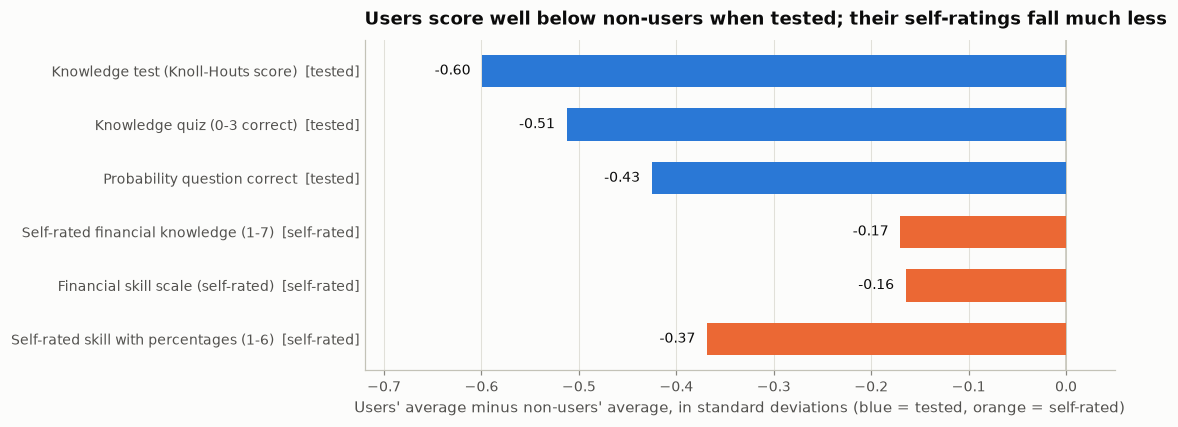

In [87]:
MEASURES = [
    ("KHscore", "Knowledge test (Knoll-Houts score)", "Tested"),
    ("LMscore", "Knowledge quiz (0-3 correct)", "Tested"),
    ("ON2correct", "Probability question correct", "Tested"),
    ("SUBKNOWL1", "Self-rated financial knowledge (1-7)", "Self-rated"),
    ("FSscore", "Financial skill scale (self-rated)", "Self-rated"),
    ("SUBNUMERACY1", "Self-rated skill with percentages (1-6)", "Self-rated"),
]
u = full["user"]
gap = pd.DataFrame([{"Measure": label, "Type": kind, "Non-users (mean)": full.loc[~u, col].mean(), "Users (mean)": full.loc[u, col].mean(),
                     "Gap in standard deviations": (full.loc[u, col].mean() - full.loc[~u, col].mean()) / full[col].std()}
                    for col, label, kind in MEASURES]).set_index("Measure")
display(fmt(gap, {"Non-users (mean)": "{:.2f}", "Users (mean)": "{:.2f}", "Gap in standard deviations": "{:+.2f}"}))
tested_avg = gap.loc[gap["Type"] == "Tested", "Gap in standard deviations"].mean()
self_avg = gap.loc[gap["Type"] == "Self-rated", "Gap in standard deviations"].mean()
print(f"Average gap: tested {tested_avg:+.2f} sd, self-rated {self_avg:+.2f} sd. "
      f"The self-rated gap is {self_avg / tested_avg:.0%} of the tested gap.")

fig, ax = plt.subplots(figsize=(8.8, 3.9))
order = gap.index[::-1]
colors = [BLUE if gap.loc[m, "Type"] == "Tested" else ORANGE for m in order]
ax.barh(np.arange(len(order)), gap.loc[order, "Gap in standard deviations"], height=0.6, color=colors, zorder=3)
for i, m in enumerate(order):
    v = gap.loc[m, "Gap in standard deviations"]
    ax.text(v - 0.012, i, f"{v:+.2f}", va="center", ha="right", fontsize=9, color=INK)
ax.axvline(0, color=AXIS, linewidth=1)
ax.set_yticks(np.arange(len(order)), [f"{m}  [{gap.loc[m, 'Type'].lower()}]" for m in order])
ax.set_xlim(-0.72, 0.05)
ax.set_xlabel("Users' average minus non-users' average, in standard deviations (blue = tested, orange = self-rated)")
ax.set_title("Users score well below non-users when tested; their self-ratings fall much less")
ax.grid(axis="y", visible=False)
ax.tick_params(axis="y", length=0)
fig.savefig(FIG_DIR / "23_knowledge_confidence_gap.png")
plt.show()

The gap can also be measured person by person. Each respondent gets a **percentile** on tested knowledge (`KHscore`) and on self-rated knowledge (`SUBKNOWL1`): where they stand against everyone else, from 0 (lowest) to 100 (highest). **Overconfidence** is the self-rated percentile minus the tested percentile. A positive value means a person ranks themselves higher than their test result ranks them.

In [88]:
kh_pct = full["KHscore"].rank(pct=True) * 100
self_pct = full["SUBKNOWL1"].rank(pct=True) * 100
over = (self_pct - kh_pct).rename("overconfidence")
low_k = full["Low financial knowledge"]
rated_high = full["SUBKNOWL1"] >= 5

conf = pd.DataFrame({
    "Average overconfidence (percentile points)": [over[u].mean(), over[~u].mean()],
    "Share ranking themselves 25+ points above their test": [(over[u] >= 25).mean(), (over[~u] >= 25).mean()],
    "Low knowledge: share rating own knowledge 5+ of 7": [rated_high[u & low_k].mean(), rated_high[~u & low_k].mean()],
    "Low knowledge: average self-rating (1-7)": [full.loc[u & low_k, "SUBKNOWL1"].mean(), full.loc[~u & low_k, "SUBKNOWL1"].mean()],
    "People": [int(u.sum()), int((~u).sum())],
}, index=["Users", "Non-users"]).T
display(fmt(conf.T, {"Average overconfidence (percentile points)": "{:+.1f}", "Share ranking themselves 25+ points above their test": pct,
                     "Low knowledge: share rating own knowledge 5+ of 7": pct, "Low knowledge: average self-rating (1-7)": "{:.2f}", "People": "{:,.0f}"}).T)
print(f"Users with low tested knowledge: {int((u & low_k).sum())} of {int(u.sum())} ({low_k[u].mean():.1%}); "
      f"of these, {int((u & low_k & rated_high).sum())} rate their own knowledge 5 or more out of 7.")

,Users,Non-users
Average overconfidence (percentile points),+10.7,-1.1
Share ranking themselves 25+ points above their test,34.3%,23.8%
Low knowledge: share rating own knowledge 5+ of 7,50.2%,52.8%
Low knowledge: average self-rating (1-7),4.42,4.45
People,560,"5,807"


Users with low tested knowledge: 329 of 560 (58.8%); of these, 165 rate their own knowledge 5 or more out of 7.


**Takeaways**

- **On tested knowledge, users fall well behind:** 0.60 standard deviations below non-users on the knowledge test, 0.51 on the three-question quiz and 0.43 on the probability question (48% answered it correctly, against 68% of non-users).
- **On self-ratings, the gap is much smaller:** 0.17 standard deviations on self-rated knowledge and 0.16 on the financial skill scale. On average the self-rated gap (−0.23) is 46% of the tested gap (−0.51). Users know they are a little behind. They do not see how far.
- **The exception is percentages:** users rate their skill with percentages 0.37 standard deviations lower, so they partly recognise this weakness. Fees stated as percentages (for example, a currency conversion fee of 3%) are therefore hard for this group; dollar amounts are easier to understand.
- **Person by person, users overrate themselves.** They rank 10.7 percentile points higher on self-rated knowledge than their test places them; non-users rank 1.1 points lower. 34.3% of users rank themselves 25 or more points above their test result, against 23.8% of non-users.
- **Self-assessment cannot pick out the unsophisticated user.** 58.8% of users (329 of 560) have low tested knowledge, and 165 of them rate their knowledge 5 or more out of 7. Among low-knowledge people, users rate themselves exactly as highly as non-users (average 4.42 against 4.45; 50.2% against 52.8% rating 5 or more).
- **What this means for policy:** protections that depend on consumers recognising that they need help, such as opt-in education or "read the terms and conditions", will miss about half of the people they are meant for. Defaults and plain disclosures protect people whether or not they see the risk.

#### 4.1 Experience with financial services and complaints

The survey also asks about treatment by financial services, familiarity with the agencies that resolve problems (such as the CFPB), and use of other high-cost services. These bear directly on which protections can reach users. Full cleaned sample; "vulnerable users" are users with two or more markers.

In [89]:
EXPERIENCE = {
    "Felt mistreated by financial services sometimes or often": full["CONSPROTECT1"] >= 3,
    "Not at all familiar with agencies that resolve problems": full["CONSPROTECT2"] == 1,
    "Has reported a problem to such an agency": full["CONSPROTECT3"] == 1,
    "Struggles to understand financial information often or always": full["FS2_3"] >= 4,
    "Used payday, pawn/title loan or check cashing": (full[OTHER_HIGH_COST] == 1).any(axis=1),
    "Finds it very difficult to cover monthly bills": full["ENDSMEET"] == 3,
}
groups4 = {"Non-users": ~u, "All users": u, "Vulnerable users (2+ markers)": u & full["vulnerable"], "Other users (0-1 markers)": u & ~full["vulnerable"]}
experience = pd.DataFrame({g: {k: v[m].mean() for k, v in EXPERIENCE.items()} for g, m in groups4.items()})
experience["Ratio (users / non-users)"] = experience["All users"] / experience["Non-users"]
display(pd.DataFrame({g: [int(m.sum())] for g, m in groups4.items()}, index=["People"]))
display(fmt(experience, {**{g: pct for g in groups4}, "Ratio (users / non-users)": "{:.2f}x"}))

seek = {"Government": "INTERCONNECTIONS_9", "Community or faith-based organization": "INTERCONNECTIONS_6", "Financial institution": "INTERCONNECTIONS_7",
        "Professional advisor or counselor": "INTERCONNECTIONS_8", "Friends or co-workers": "INTERCONNECTIONS_5", "Parent": "INTERCONNECTIONS_1"}
advice = pd.DataFrame({g: {k: (full[c] == 1)[m].mean() for k, c in seek.items()} for g, m in list(groups4.items())[:3]})
advice["Ratio (users / non-users)"] = advice["All users"] / advice["Non-users"]
print("Where people seek advice about money (share who name each source):")
display(fmt(advice, {**{g: pct for g in list(groups4)[:3]}, "Ratio (users / non-users)": "{:.2f}x"}))

,Non-users,All users,Vulnerable users (2+ markers),Other users (0-1 markers)
People,5807,560,353,207


,Non-users,All users,Vulnerable users (2+ markers),Other users (0-1 markers),Ratio (users / non-users)
Felt mistreated by financial services sometimes or often,17.4%,29.3%,36.3%,17.4%,1.69x
Not at all familiar with agencies that resolve problems,55.8%,48.4%,51.3%,43.5%,0.87x
Has reported a problem to such an agency,6.5%,12.3%,13.0%,11.1%,1.90x
Struggles to understand financial information often or always,14.6%,19.5%,23.5%,12.6%,1.33x
"Used payday, pawn/title loan or check cashing",9.3%,18.8%,24.6%,8.7%,2.01x
Finds it very difficult to cover monthly bills,6.6%,17.0%,25.8%,1.9%,2.57x


Where people seek advice about money (share who name each source):


,Non-users,All users,Vulnerable users (2+ markers),Ratio (users / non-users)
Government,3.1%,6.8%,8.5%,2.21x
Community or faith-based organization,3.4%,6.8%,6.8%,2.01x
Financial institution,20.5%,18.9%,11.6%,0.93x
Professional advisor or counselor,27.0%,19.1%,9.3%,0.71x
Friends or co-workers,22.7%,25.4%,22.9%,1.11x
Parent,21.2%,26.2%,27.2%,1.24x


**Takeaways**

- **Users report worse treatment.** 29.3% felt mistreated by financial services sometimes or often, against 17.4% of non-users (1.69 times). Among vulnerable users it is 36.3%; among other users it is 17.4%, the same as non-users. The problem sits with the vulnerable users.
- **Users know complaint channels slightly better, and use them.** 48.4% are not at all familiar with agencies that resolve problems (non-users 55.8%), and users are about twice as likely to have reported a problem (12.3% against 6.5%). However, **half of vulnerable users (51.3%) are not at all familiar with any such agency.**
- **Vulnerable users struggle with financial information more:** 23.5% often or always struggle to understand it, against 14.6% of non-users and 12.6% of other users.
- **Fees stack across products.** 24.6% of vulnerable users also used a payday loan, pawn or title loan, or check cashing, against 8.7% of other users and 9.3% of non-users.
- **Day-to-day strain is severe:** 25.8% of vulnerable users find it very difficult to cover monthly bills, against 1.9% of other users.
- **Advice comes from outside the financial system.** Users name government (6.8% against 3.1%) and community or faith organisations (6.8% against 3.4%) about twice as often as non-users. Vulnerable users rarely use professional advisors (9.3%) or financial institutions (11.6%) and most often turn to parents (27.2%) and friends (22.9%). The shares are small, but they show which channels can reach this group: benefit offices and community organisations, not bank branches or advisors.

---
## 5. Fairness audit of the model

**Why this matters.** A model that finds likely prepaid users will tend to concentrate on lower-income, unbanked and minority consumers. If it is used to market a high-fee product, that amounts to steering protected groups toward worse products ("reverse redlining"). Race/ethnicity and sex are not predictors (Part 2), but leaving them out ("fairness through unawareness") is not enough on its own: bank access, income and housing can recreate them. This section measures what the rule actually does.

**Legal and regulatory context** (background for the policy discussion, not legal advice):

- **Equal Credit Opportunity Act (ECOA) / Regulation B** prohibits credit discrimination on race, color, religion, national origin, sex, marital status, age, or receipt of public assistance income. A plain prepaid card is not credit, but cards with overdraft or credit features can be, and regulators apply fair-lending thinking to marketing and targeting. **The project's original 20-predictor model used three of these: age (`agecat`), marital status (`PPMARIT`) and SNAP receipt, which is public assistance.** This version of the project removes them (Part 2), and Section 5.6 measures what that changed.
- **UDAAP** (Dodd-Frank) prohibits unfair, deceptive or abusive acts or practices. Taking unreasonable advantage of consumers' lack of understanding is the core of "abusive", so steering high-fee products at low-knowledge consumers is the risk.
- **Disparate impact:** a neutral-looking rule can still be a problem if its outcomes fall disproportionately on a protected group without a business need that a less discriminatory alternative could meet.
- **CFPB Prepaid Accounts Rule** (effective April 2019): standard short-form fee disclosures, Regulation E error and loss protections, and credit-card rules for overdraft features.

Part 4 (Section 6) showed the rule flags Black and Hispanic respondents about three times as often as White respondents. The audit takes that further:

| Subsection | Test |
|---|---|
| 5.1 | **Selection and error rates by group** (race/ethnicity, sex, age band) |
| 5.2 | **Calibration by group:** do people with similar scores use prepaid cards at similar rates in every group? |
| 5.3 | **Equally vulnerable people:** does the gap remain within the same vulnerability band? |
| 5.4 | **Proxy check:** can the 17 inputs predict race/ethnicity or sex? |
| 5.5 | **What drives the gap:** which predictors push Black and Hispanic respondents' scores up |
| 5.6 | **Mitigations and their cost:** removing the legally sensitive predictors, and the strongest proxies |
| 5.7 | **Intersections:** race/ethnicity by sex and by age |
| 5.8 | **Audit summary:** what was tested, found and changed, and what risk remains |

All audit tests use the training set (out-of-fold scores), with the test set confirming the headline rates. The "Other, non-Hispanic" group is small (270 in training, 65 in test; 23 and 6 users) and its figures are not reliable.

#### 5.1 Selection and error rates by group

- **Score percentile:** where a person's score falls among all training scores (0–100).
- **Share flagged (selection rate):** share of the group the top-20% rule would market to. **Selection ratio** = a group's share flagged divided by the most-flagged group's. A common screening flag is a ratio below 0.8 (the "four-fifths rule" from employment law). Here, being selected means receiving an offer for a potentially high-fee product, so a *high* selection rate is the exposure to watch, not a benefit being withheld.
- **True-positive rate:** share of actual users the rule flags. **False-positive rate:** share of *non-users* it flags, meaning people who would receive marketing for a product they do not use. **Precision:** share of those flagged who are users.
- **ROC-AUC within group:** the chance that a randomly chosen user in the group scores above a randomly chosen non-user (0.5 = no better than chance, 1 = perfect).

Race/ethnicity, training set (out-of-fold scores):


Group,"White, non-Hispanic","Black, non-Hispanic","Other, non-Hispanic",Hispanic
People,"3,586",536,270,701
Users,224,98,23,103
Usage rate,6.2%,18.3%,8.5%,14.7%
Median score percentile,42,73,52,74
Share flagged,12.6%,42.2%,20.0%,40.8%
True-positive rate (users flagged),36.2%,65.3%,17.4%,67.0%
False-positive rate (non-users flagged),11.1%,37.0%,20.2%,36.3%
Precision (flagged who are users),17.9%,28.3%,7.4%,24.1%
ROC-AUC within group,0.694,0.719,0.549,0.704
Selection ratio (vs most-flagged group),0.30,1.00,0.47,0.97


Race/ethnicity, test set (confirmation):


Group,"White, non-Hispanic","Black, non-Hispanic","Other, non-Hispanic",Hispanic
People,898,145,65,166
Users,44,29,6,33
Usage rate,4.9%,20.0%,9.2%,19.9%
Median score percentile,44,79,55,63
Share flagged,11.8%,48.3%,24.6%,32.5%
True-positive rate (users flagged),36.4%,72.4%,66.7%,57.6%
False-positive rate (non-users flagged),10.5%,42.2%,20.3%,26.3%
Precision (flagged who are users),15.1%,30.0%,25.0%,35.2%
ROC-AUC within group,0.704,0.670,0.836,0.669
Selection ratio (vs most-flagged group),0.24,1.00,0.51,0.67


Training false-positive rate relative to White respondents: Black 3.3x, Hispanic 3.3x.
Sex, training set:


Group,Male,Female
People,"2,686","2,407"
Users,238,210
Usage rate,8.9%,8.7%
Median score percentile,44,55
Share flagged,17.8%,22.5%
True-positive rate (users flagged),46.2%,51.4%
False-positive rate (non-users flagged),15.0%,19.7%
Precision (flagged who are users),23.0%,20.0%
ROC-AUC within group,0.734,0.722
Selection ratio (vs most-flagged group),0.79,1.00


Age band, training set:


Group,18-34,35-61,62 and over
People,"1,227","2,058","1,808"
Users,151,161,136
Usage rate,12.3%,7.8%,7.5%
Median score percentile,67,45,46
Share flagged,33.5%,19.3%,11.7%
True-positive rate (users flagged),64.2%,51.6%,27.9%
False-positive rate (non-users flagged),29.2%,16.6%,10.3%
Precision (flagged who are users),23.6%,20.9%,18.0%
ROC-AUC within group,0.708,0.760,0.690
Selection ratio (vs most-flagged group),1.00,0.58,0.35


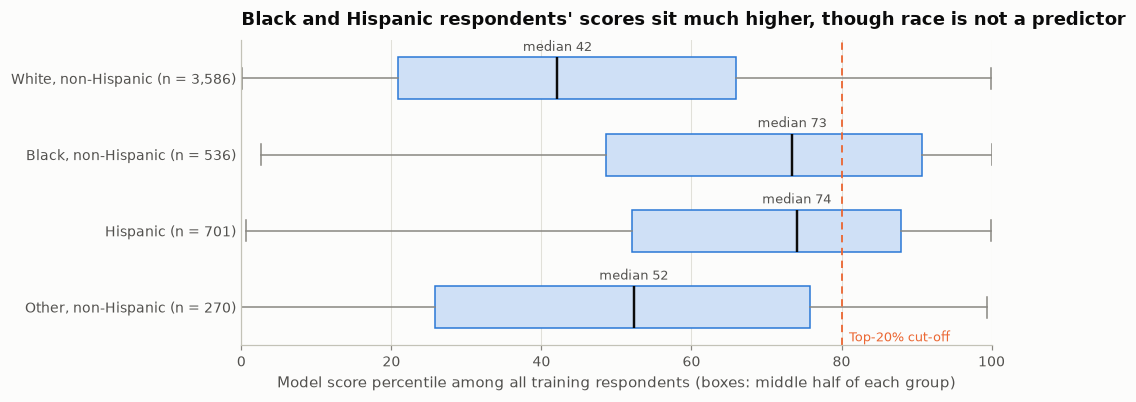

In [90]:
train_sorted = np.sort(train_scores["score_chosen"].to_numpy())
SEX = {1: "Male", 2: "Female"}
AGE_BANDS = ["18-34", "35-61", "62 and over"]


def add_audit_columns(d):
    """Score percentile among training scores, sex, and a three-way age band (from agecat)."""
    return d.assign(score_pct=np.searchsorted(train_sorted, d["score"].to_numpy(), side="right") / len(train_sorted) * 100,
                    sex=d["PPGENDER"].map(SEX),
                    age_band=pd.cut(d["agecat"], [0, 2, 5, 8], labels=AGE_BANDS).astype(str))


train, test = add_audit_columns(train), add_audit_columns(test)


def fairness_table(d, col, order):
    rows = []
    for g in order:
        x = d[d[col] == g]
        rows.append({"Group": g, "People": len(x), "Users": int(x["user"].sum()), "Usage rate": x["user"].mean(),
                     "Median score percentile": x["score_pct"].median(), "Share flagged": x["flagged"].mean(),
                     "True-positive rate (users flagged)": x.loc[x["user"], "flagged"].mean(),
                     "False-positive rate (non-users flagged)": x.loc[~x["user"], "flagged"].mean(),
                     "Precision (flagged who are users)": x.loc[x["flagged"], "user"].mean(),
                     "ROC-AUC within group": roc_auc_score(x["user"], x["score"])})
    t = pd.DataFrame(rows).set_index("Group")
    t["Selection ratio (vs most-flagged group)"] = t["Share flagged"] / t["Share flagged"].max()
    return t


fair_formats = {"People": "{:,}", "Usage rate": pct, "Median score percentile": "{:.0f}", "Share flagged": pct,
                "True-positive rate (users flagged)": pct, "False-positive rate (non-users flagged)": pct,
                "Precision (flagged who are users)": pct, "ROC-AUC within group": "{:.3f}", "Selection ratio (vs most-flagged group)": "{:.2f}"}
fair_tr = fairness_table(train, "race", RACE.values())
fair_te = fairness_table(test, "race", RACE.values())
print("Race/ethnicity, training set (out-of-fold scores):")
display(fmt(fair_tr, fair_formats).T)
print("Race/ethnicity, test set (confirmation):")
display(fmt(fair_te, fair_formats).T)
w, b, h = RACE[1], RACE[2], RACE[4]
print(f"Training false-positive rate relative to White respondents: Black {fair_tr.loc[b, 'False-positive rate (non-users flagged)'] / fair_tr.loc[w, 'False-positive rate (non-users flagged)']:.1f}x, "
      f"Hispanic {fair_tr.loc[h, 'False-positive rate (non-users flagged)'] / fair_tr.loc[w, 'False-positive rate (non-users flagged)']:.1f}x.")
for col, order, title in [("sex", SEX.values(), "Sex"), ("age_band", AGE_BANDS, "Age band")]:
    print(f"{title}, training set:")
    display(fmt(fairness_table(train, col, order), fair_formats).T)

fig, ax = plt.subplots(figsize=(8.8, 3.6))
groups5 = [w, b, h, RACE[3]]
data = [train.loc[train["race"] == g, "score_pct"] for g in groups5][::-1]
bp = ax.boxplot(data, orientation="horizontal", widths=0.55, patch_artist=True, showfliers=False,
                medianprops={"color": INK, "linewidth": 1.6}, whiskerprops={"color": MUTED}, capprops={"color": MUTED})
for patch in bp["boxes"]:
    patch.set(facecolor="#cfe0f6", edgecolor=BLUE)
for i, g in enumerate(groups5[::-1], start=1):
    med = fair_tr.loc[g, "Median score percentile"]
    ax.text(med, i + 0.36, f"median {med:.0f}", ha="center", fontsize=8.5, color=INK2)
ax.axvline(100 * (1 - TOP_SHARE), color=ORANGE, linewidth=1.2, linestyle=(0, (4, 3)))
ax.text(100 * (1 - TOP_SHARE) + 1, 0.55, "Top-20% cut-off", color=ORANGE, fontsize=8.5)
ax.set_yticks(range(1, len(groups5) + 1), [f"{g} (n = {fair_tr.loc[g, 'People']:,})" for g in groups5[::-1]])
ax.set_xlim(0, 100)
ax.set_xlabel("Model score percentile among all training respondents (boxes: middle half of each group)")
ax.set_title("Black and Hispanic respondents' scores sit much higher, though race is not a predictor")
ax.grid(axis="y", visible=False)
ax.tick_params(axis="y", length=0)
fig.savefig(FIG_DIR / "24_score_by_race_ethnicity.png")
plt.show()

**Takeaways**

- **Scores sit much higher for Black and Hispanic respondents.** Their median score percentile is 73 and 74, against 42 for White respondents (test: 79, 63 and 44). The rule flags 42.2% and 40.8% against 12.6%.
- **The model ranks people about equally well within each group.** ROC-AUC is 0.719 for Black, 0.704 for Hispanic and 0.694 for White respondents in training (test: 0.670, 0.669 and 0.704). Precision is *higher* for Black and Hispanic respondents (28.3% and 24.1% of those flagged are users, against 17.9%). The model is not less accurate for them.
- **The cost of the model's mistakes falls unevenly.** **37.0% of Black and 36.3% of Hispanic non-users are flagged, against 11.1% of White non-users: 3.3 times as often for both** (test: 42.2% and 26.3% against 10.5%). In a campaign built on this rule, Black and Hispanic consumers who do not use prepaid cards would receive offers for a potentially high-fee product about three times as often as White consumers.
- **The other side:** the rule flags 65.3% of Black and 67.0% of Hispanic users but only 36.2% of White users. White users are mostly the banked, mainstream users the model misses (Part 4).
- **The "Other, non-Hispanic" figures are unreliable** (23 users in training, 6 in test; ROC-AUC 0.549 in training and 0.836 in test).
- **The selection ratio for White respondents is 0.30** (0.24 in test), far below the 0.8 screening line.
- **Sex: women are flagged more often than men (22.5% against 17.8%; selection ratio 0.79, just below 0.8) although usage is the same (8.7% against 8.9%).** 19.7% of women non-users are flagged against 15.0% of men, and precision is lower for women (20.0% against 23.0%). Unlike the racial gap, this one is **not** matched by a difference in use. Sections 5.2, 5.5 and 5.7 look at why.
- **Age: 18–34-year-olds are flagged at 33.5%** (usage 12.3%), against 11.7% of those 62 and over (usage 7.5%; selection ratio 0.35). Age is not a predictor in this version, so this gap comes entirely from the other predictors.
- **Plainly:** leaving race and sex out of the model does not make its effect neutral. A regulator would expect a firm using this rule to monitor these disparities and be able to justify them.

#### 5.2 Calibration by group

If the score means the same thing in every group, people in the same score band should use prepaid cards at similar rates whatever their race/ethnicity. Scores are rankings, not probabilities (Part 3), so the check uses actual usage rates within three score bands: the bottom 40%, the middle 40%, and the top 20% that the rule flags. Each cell shows the usage rate and, in brackets, the number of people.

In [91]:
BAND_ORDER = ["Bottom 40% of scores", "Middle 40%", "Top 20% (flagged)"]


def calibration_by_group(d, col, order):
    band = np.select([d["flagged"], d["score_pct"] >= 40], BAND_ORDER[:0:-1], BAND_ORDER[0])
    g = d.assign(band=band).groupby(["band", col])["user"].agg(["mean", "size"])
    return pd.DataFrame({grp: [f"{g.loc[(bd, grp), 'mean']:.1%} ({int(g.loc[(bd, grp), 'size']):,})" if (bd, grp) in g.index else ""
                               for bd in BAND_ORDER] for grp in order}, index=pd.Index(BAND_ORDER, name="Score band"))


print("Usage rate (number of people) by score band, training set:")
display(calibration_by_group(train, "race", list(RACE.values())))
print("Test set (confirmation):")
display(calibration_by_group(test, "race", list(RACE.values())))
print("By sex and age band, training set:")
display(calibration_by_group(train, "sex", list(SEX.values())).join(calibration_by_group(train, "age_band", AGE_BANDS)))

Usage rate (number of people) by score band, training set:


,"White, non-Hispanic","Black, non-Hispanic","Other, non-Hispanic",Hispanic
Score band,,,,
Bottom 40% of scores,"3.0% (1,709)",4.7% (106),7.0% (100),2.5% (122)
Middle 40%,"6.4% (1,424)",14.2% (204),10.3% (116),10.6% (293)
Top 20% (flagged),17.9% (453),28.3% (226),7.4% (54),24.1% (286)


Test set (confirmation):


,"White, non-Hispanic","Black, non-Hispanic","Other, non-Hispanic",Hispanic
Score band,,,,
Bottom 40% of scores,2.8% (396),0.0% (22),0.0% (23),14.9% (47)
Middle 40%,4.3% (396),15.1% (53),7.7% (26),10.8% (65)
Top 20% (flagged),15.1% (106),30.0% (70),25.0% (16),35.2% (54)


By sex and age band, training set:


,Male,Female,18-34,35-61,62 and over
Score band,,,,,
Bottom 40% of scores,"3.3% (1,220)",3.3% (817),5.9% (320),2.4% (961),3.3% (756)
Middle 40%,8.9% (988),"7.1% (1,049)",7.1% (496),7.9% (700),8.7% (841)
Top 20% (flagged),23.0% (478),20.0% (541),23.6% (411),20.9% (397),18.0% (211)


**Takeaways**

- **Race/ethnicity: the score does not overstate Black and Hispanic respondents' likelihood of use; if anything it understates it.** Within the same score band they use prepaid cards more often than White respondents: in the top 20%, 28.3% (Black) and 24.1% (Hispanic) against 17.9% (White); in the middle 40%, 14.2% and 10.6% against 6.4%. The test set agrees for the top band (30.0% and 35.2% against 15.1%). Its smaller cells, such as Hispanic respondents in the bottom band (47 people), are too noisy to read.
- **So the high flag rates in Section 5.1 do not come from inflated scores for these groups.** They come from more Black and Hispanic respondents sitting in the top band, because more of them have the characteristics the model weighs. The bands are wide, so this is a coarse check.
- **Sex: the score does overstate women's likelihood relative to men's.** At the same score band, women use prepaid cards less often than men: 20.0% against 23.0% in the top 20%, and 7.1% against 8.9% in the middle 40%. Together with Section 5.1 (women flagged 22.5% against 17.8%, with equal usage of 8.7% and 8.9%), this is a disparity that **is not explained by a difference in use**.
- **Age:** usage in the top band is 23.6% (18–34), 20.9% (35–61) and 18.0% (62 and over), a mild version of the same pattern for younger adults.
- **The fairness measures cannot all be met at once.** When usage rates differ between groups, a score cannot be equally calibrated, have equal false-positive rates and select groups at equal rates all at the same time. For race/ethnicity the model is roughly calibrated but selects and mis-flags Black and Hispanic non-users far more often. When the use is *marketing a potentially high-fee product*, exposure (selection and false-positive rates) is the measure the CFPB should weigh most. When the use is *finding people who need protection*, calibration matters more.

#### 5.3 Equally vulnerable people

Does the gap remain among people who are equally vulnerable, and what do the flagged people in each group look like?

In [92]:
def within_band(d):
    rows = []
    for g in RACE.values():
        x = d[d["race"] == g]
        lo, hi = x[~x["vulnerable"]], x[x["vulnerable"]]
        f = x[x["flagged"]]
        rows.append({"Group": g, "Share vulnerable (2+ markers)": x["vulnerable"].mean(),
                     "Flagged, 0-1 markers": lo["flagged"].mean(), "Flagged, 2+ markers": hi["flagged"].mean(),
                     "Usage rate, 0-1 markers": lo["user"].mean(), "Usage rate, 2+ markers": hi["user"].mean(),
                     "Average markers if 2+": hi["markers"].mean(),
                     "Flagged who are vulnerable": f["vulnerable"].mean(), "Flagged with low knowledge": f["Low financial knowledge"].mean(),
                     "Flagged with no bank account": f["No checking or savings account"].mean()})
    return pd.DataFrame(rows).set_index("Group")


band_tr = within_band(train)
band_formats = {c: pct for c in band_tr.columns if c != "Average markers if 2+"} | {"Average markers if 2+": "{:.2f}"}
print("Training set:")
display(fmt(band_tr, band_formats).T)
band_te = within_band(test)
print("Test set, flag rates within band (confirmation):")
display(fmt(band_te[["Share vulnerable (2+ markers)", "Flagged, 0-1 markers", "Flagged, 2+ markers", "Usage rate, 2+ markers"]], band_formats).T)

Training set:


Group,"White, non-Hispanic","Black, non-Hispanic","Other, non-Hispanic",Hispanic
Share vulnerable (2+ markers),25.3%,52.4%,30.7%,59.6%
"Flagged, 0-1 markers",2.1%,5.9%,4.3%,6.7%
"Flagged, 2+ markers",43.6%,75.1%,55.4%,63.9%
"Usage rate, 0-1 markers",3.9%,9.8%,7.5%,8.1%
"Usage rate, 2+ markers",13.2%,26.0%,10.8%,19.1%
Average markers if 2+,2.75,3.32,2.84,3.06
Flagged who are vulnerable,87.4%,93.4%,85.2%,93.4%
Flagged with low knowledge,64.2%,87.2%,77.8%,83.9%
Flagged with no bank account,41.3%,51.3%,35.2%,49.7%


Test set, flag rates within band (confirmation):


Group,"White, non-Hispanic","Black, non-Hispanic","Other, non-Hispanic",Hispanic
Share vulnerable (2+ markers),26.5%,64.8%,32.3%,50.0%
"Flagged, 0-1 markers",1.7%,5.9%,6.8%,2.4%
"Flagged, 2+ markers",39.9%,71.3%,61.9%,62.7%
"Usage rate, 2+ markers",9.7%,25.5%,19.0%,24.1%


**Takeaways**

- **Vulnerability itself is unevenly spread:** 52.4% of Black and 59.6% of Hispanic respondents have two or more markers, against 25.3% of White respondents.
- **The flag gap remains among equally vulnerable people.** Among people with two or more markers, the rule flags 75.1% of Black and 63.9% of Hispanic respondents, against 43.6% of White respondents (test: 71.3%, 62.7% and 39.9%). Among people with 0–1 markers it flags 5.9% and 6.7% against 2.1%.
- **Within the band, the gap follows real differences.** Vulnerable Black and Hispanic respondents have more markers on average (3.32 and 3.06 against 2.75) and use prepaid cards more (26.0% and 19.1% against 13.2%). Section 5.5 shows which predictors carry the rest of the gap.
- **The people flagged in Black and Hispanic groups are more exposed.** In every group most flagged people are vulnerable (85.2% to 93.4%), but flagged Black and Hispanic respondents more often have low knowledge (87.2% and 83.9% against 64.2%) and no bank account (51.3% and 49.7% against 41.3%).
- **Reading:** for race/ethnicity the disparity is not a modelling error. It mirrors how financial fragility and usage are distributed, so removing race from the inputs cannot remove it (Sections 5.4–5.6 test this).

#### 5.4 Proxy check: do the 17 inputs encode race/ethnicity or sex?

If the predictors can recover a protected attribute, excluding the attribute does not keep it out of the model. The test fits a logistic regression that predicts each attribute from the same 17 inputs, with the same preparation, scored by 5-fold cross-validation on the training set. ROC-AUC reads as before: 0.5 means the inputs carry no information about the attribute, and 1 means they reveal it perfectly. For comparison, the same inputs predict prepaid use with ROC-AUC 0.730 (Part 3).

In [93]:
folds = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
features = feature_table()


def cv_auc(target, columns=None):
    """Cross-validated ROC-AUC of a class-weighted logistic regression predicting `target` from the predictors."""
    columns = list(features.index) if columns is None else columns
    model = Pipeline([("prep", subset_preprocessor(columns)),
                      ("model", LogisticRegression(class_weight="balanced", max_iter=5000, random_state=SEED))])
    oof = cross_val_predict(model, X_train[columns], target, cv=folds, method="predict_proba")[:, 1]
    return roc_auc_score(target, oof)


scaled_cols, binary_cols, nominal_cols = feature_lists()
# The three predictors removed from the model in Part 2, with the preparation they had there (used only in Section 5.6).
ECOA_SENSITIVE = {"agecat": "scaled", "SNAP": "binary", "PPMARIT": "nominal"}
scaled_cols, binary_cols, nominal_cols = (scaled_cols + ["agecat"], binary_cols + ["SNAP"], nominal_cols + ["PPMARIT"])


def subset_preprocessor(columns):
    """The shared preparation rules from prep.py, applied to a subset of the predictors (plus the three removed ECOA-sensitive ones, for Section 5.6)."""
    columns = list(columns)
    return ColumnTransformer([
        ("scaled", Pipeline([("impute", SimpleImputer(strategy="median")), ("scale", StandardScaler())]), [c for c in scaled_cols if c in columns]),
        ("binary", SimpleImputer(strategy="most_frequent"), [c for c in binary_cols if c in columns]),
        ("nominal", Pipeline([("impute", SimpleImputer(strategy="most_frequent")),
                              ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False))]), [c for c in nominal_cols if c in columns]),
    ], remainder="drop", verbose_feature_names_out=False)


proxy_targets = {"Black, non-Hispanic (vs everyone else)": train["race"] == RACE[2],
                 "Hispanic (vs everyone else)": train["race"] == RACE[4],
                 "Black or Hispanic (vs everyone else)": train["race"].isin([RACE[2], RACE[4]]),
                 "Female (vs male)": train["sex"] == "Female"}
proxy = pd.DataFrame([{"Attribute predicted from the 17 inputs": k, "Share of respondents": v.mean(), "Cross-validated ROC-AUC": cv_auc(v.astype(int))}
                      for k, v in proxy_targets.items()]).set_index("Attribute predicted from the 17 inputs")
display(fmt(proxy, {"Share of respondents": pct, "Cross-validated ROC-AUC": "{:.3f}"}))

,Share of respondents,Cross-validated ROC-AUC
Attribute predicted from the 17 inputs,,
"Black, non-Hispanic (vs everyone else)",10.5%,0.731
Hispanic (vs everyone else),13.8%,0.757
Black or Hispanic (vs everyone else),24.3%,0.763
Female (vs male),47.3%,0.690


**Takeaways**

- **The 17 inputs identify race/ethnicity better than they predict prepaid use.** They pick out Black or Hispanic respondents with ROC-AUC 0.763 (Black alone 0.731, Hispanic alone 0.757), against 0.730 for prepaid use itself. They identify women with ROC-AUC 0.690.
- **Leaving race/ethnicity and sex out of the model therefore does not keep them out.** The model cannot be described as "unbiased" because protected attributes were excluded. This is why Sections 5.1–5.3 test outcomes directly.

#### 5.5 What drives the score gap between groups?

The chosen model is a logistic regression, so each person's score (on the log-odds scale) is a sum of one contribution per predictor: weight × the person's prepared value. Averaging those contributions within each group and subtracting the White average splits the score gap exactly into the part due to each predictor. The model is refitted from its documented settings (as in Part 4) and checked against the Part 3 scores first.

A positive number means the predictor pushes the group's average score **above** White respondents'. The units are log-odds; only their relative size matters here.

Total gap in average log-odds: Black minus White +0.752, Hispanic minus White +0.695


,Black minus White,Hispanic minus White,Black minus White (share of total gap),Hispanic minus White (share of total gap)
Knoll and Houts financial knowledge scale score (KHscore),+0.173,+0.183,23%,26%
Which one of the following best describes your housing situation? (HOUSING),+0.136,+0.147,18%,21%
Household Income (PPINCIMP),+0.105,+0.128,14%,18%
Has: Checking or Savings Account at a bank or credit union (PRODHAVE_1),+0.081,+0.092,11%,13%
Has: Retirement Account (such as a 401k or IRA) (PRODHAVE_4),+0.042,+0.054,6%,8%
Contacted by debt collector in past 12 months (COLLECT),+0.067,+0.028,9%,4%
Number of financial shocks in the past year (0-11) (SHOCKS_COUNT),+0.035,+0.051,5%,7%
Household income volatility (VOLATILITY),+0.027,+0.036,4%,5%
Past 6 months: Paid all your bills on time (MANAGE1_1),+0.036,+0.021,5%,3%
I applied for credit and was turned down (REJECTED_1),+0.032,+0.017,4%,2%


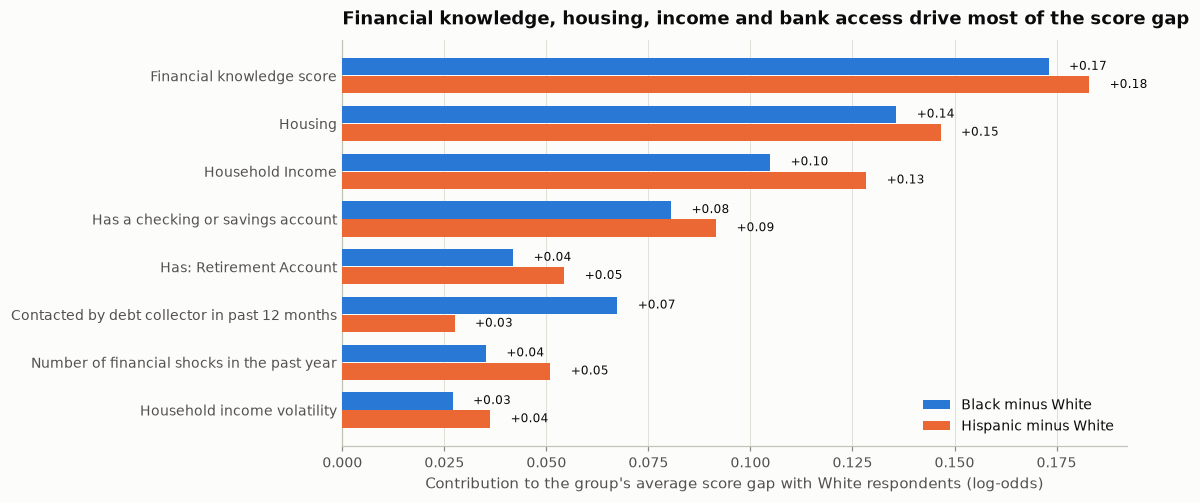

Total gap in average log-odds, Female minus Male: +0.198. Five largest contributors:


,Female minus Male,Share of total gap
Knoll and Houts financial knowledge scale score (KHscore),+0.096,49%
Household Income (PPINCIMP),+0.042,21%
Household income volatility (VOLATILITY),+0.015,7%
Number of financial shocks in the past year (0-11) (SHOCKS_COUNT),+0.014,7%
Has: Retirement Account (such as a 401k or IRA) (PRODHAVE_4),+0.014,7%


In [94]:
def logit():
    """The chosen model's settings from Part 3."""
    return LogisticRegression(C=0.3, class_weight="balanced", max_iter=5000, random_state=SEED)


chosen = Pipeline([("prep", build_preprocessor()), ("model", logit())]).fit(X_train, y_train)
assert np.allclose(chosen.predict_proba(X_test)[:, 1], test_scores["score_chosen"].to_numpy(), atol=1e-8)
prep_step, weights = chosen.named_steps["prep"], chosen.named_steps["model"].coef_[0]
model_cols = prep_step.get_feature_names_out()
contrib = pd.DataFrame(prep_step.transform(X_train) * weights, index=X_train.index, columns=model_cols)
by_predictor = contrib.T.groupby([c if c in features.index else c.rpartition("_")[0] for c in model_cols]).sum().T

white_avg = by_predictor[train["race"] == w].mean()
gaps = pd.DataFrame({"Black minus White": by_predictor[train["race"] == b].mean() - white_avg,
                     "Hispanic minus White": by_predictor[train["race"] == h].mean() - white_avg})
logodds = pd.Series(chosen.decision_function(X_train), index=X_train.index)
for col, grp in [("Black minus White", b), ("Hispanic minus White", h)]:
    assert np.isclose(gaps[col].sum(), logodds[train["race"] == grp].mean() - logodds[train["race"] == w].mean())

gaps["Combined"] = gaps.sum(axis=1)
gaps = gaps.sort_values("Combined", ascending=False)
gaps.index = [f"{features.loc[v, 'label']} ({v})" for v in gaps.index]
total = gaps[["Black minus White", "Hispanic minus White"]].sum()
shares = gaps[["Black minus White", "Hispanic minus White"]] / total
show = gaps[["Black minus White", "Hispanic minus White"]].join(shares.add_suffix(" (share of total gap)"))
print(f"Total gap in average log-odds: Black minus White {total.iloc[0]:+.3f}, Hispanic minus White {total.iloc[1]:+.3f}")
display(fmt(show, {"Black minus White": "{:+.3f}", "Hispanic minus White": "{:+.3f}",
                   "Black minus White (share of total gap)": "{:.0%}", "Hispanic minus White (share of total gap)": "{:.0%}"}))
top2 = [v.rsplit("(", 1)[1].rstrip(")") for v in gaps.index[:2]]

top = gaps.head(8).iloc[::-1]
short = [l.split(" (")[0].replace("Has: Checking or Savings Account at a bank or credit union", "Has a checking or savings account")
          .replace("Which one of the following best describes your housing situation?", "Housing")
          .replace("Knoll and Houts financial knowledge scale score", "Financial knowledge score")
          .replace("Any household member received SNAP benefits", "Household received SNAP")[:52] for l in top.index]
fig, ax = plt.subplots(figsize=(9.2, 4.8))
y = np.arange(len(top))
for off, col, colour in [(0.19, "Black minus White", BLUE), (-0.19, "Hispanic minus White", ORANGE)]:
    ax.barh(y + off, top[col], height=0.36, color=colour, label=col, zorder=3)
    for yi, v in zip(y + off, top[col]):
        ax.text(v + (0.005 if v >= 0 else -0.005), yi, f"{v:+.2f}", va="center", ha="left" if v >= 0 else "right", fontsize=8, color=INK)
ax.axvline(0, color=AXIS, linewidth=1)
ax.set_yticks(y, short)
ax.set_xlabel("Contribution to the group's average score gap with White respondents (log-odds)")
ax.set_title("Financial knowledge, housing, income and bank access drive most of the score gap")
ax.grid(axis="y", visible=False)
ax.tick_params(axis="y", length=0)
ax.legend(loc="lower right")
fig.savefig(FIG_DIR / "25_score_gap_by_predictor.png")
plt.show()

sex_gap = by_predictor[train["sex"] == "Female"].mean() - by_predictor[train["sex"] == "Male"].mean()
sex_total = sex_gap.sum()
sex_tab = pd.DataFrame({"Female minus Male": sex_gap, "Share of total gap": sex_gap / sex_total}).sort_values("Female minus Male", ascending=False)
sex_tab.index = [f"{features.loc[v, 'label']} ({v})" for v in sex_tab.index]
print(f"Total gap in average log-odds, Female minus Male: {sex_total:+.3f}. Five largest contributors:")
display(fmt(sex_tab.head(5), {"Female minus Male": "{:+.3f}", "Share of total gap": "{:.0%}"}))

**Takeaways**

- **Black respondents' average score is 0.752 log-odds above White respondents'; Hispanic respondents' is 0.695 above.**
- **Four predictors account for most of the gap: financial knowledge, housing, income and bank account.** Together they explain 66% of the Black–White gap (23%, 18%, 14% and 11%) and 78% of the Hispanic–White gap (26%, 21%, 18% and 13%). Debt-collector contact adds 9% for Black respondents.
- **The financial knowledge score is the largest single channel** for both groups. Knowledge-test results also reflect unequal access to education. Because low knowledge *raises* the score, a campaign built on this model leans toward the consumers least able to judge fees. That is the UDAAP concern stated in the introduction.
- **Employment narrows the Hispanic–White gap (−11%).** Age, marital status and SNAP are no longer in the model. In the previous model age had narrowed the Hispanic gap, because Hispanic respondents are younger on average and age had a small positive weight; Section 5.6 shows the effect of removing it.
- **The gap between women and men** (+0.198 log-odds) comes mostly from financial knowledge (49%), then income (21%).

#### 5.6 Mitigations and what they cost

This version of the project has already removed the three predictors that are prohibited bases under ECOA (age, marital status and SNAP). The table compares three versions, each scored out-of-fold with the same cross-validation folds as Part 3 (training set only; the test set is not used):

1. **The previous model:** the original 20 predictors including age, marital status and SNAP, with its original setting (`C` = 10).
2. **The current model:** the 17 predictors used throughout this version of the project.
3. **The current model without the two predictors that contribute most to the race/ethnicity score gap** (from Section 5.5).

For each version: overall ranking quality (ROC-AUC, PR-AUC), the top-20% rule's lift and recall, and how the flags fall by group.

In [95]:
X_extended = X_train.join(clean.loc[X_train.index, list(ECOA_SENSITIVE)])


def oof_scores(columns, C=0.3):
    model = Pipeline([("prep", subset_preprocessor(columns)),
                      ("model", LogisticRegression(C=C, class_weight="balanced", max_iter=5000, random_state=SEED))])
    return cross_val_predict(model, X_extended[columns], y_train, cv=folds, method="predict_proba")[:, 1]


current = list(features.index)
assert np.allclose(oof_scores(current), train_scores["score_chosen"].to_numpy(), atol=1e-6), "Refit must reproduce Part 3's out-of-fold scores"
proxies_removed = top2
variants = {f"Previous model: {len(current) + len(ECOA_SENSITIVE)} predictors incl. age, marital status, SNAP": (current + list(ECOA_SENSITIVE), 10),
            f"Current model: {len(current)} predictors (chosen)": (current, 0.3),
            f"Current model without {' and '.join(proxies_removed)} ({len(current) - len(proxies_removed)})":
                ([c for c in current if c not in proxies_removed], 0.3)}

rows = []
for label, (cols, C) in variants.items():
    s = oof_scores(cols, C)
    flag = s >= np.quantile(s, 1 - TOP_SHARE)
    row = {"Version": label, "ROC-AUC": roc_auc_score(y_train, s), "PR-AUC": average_precision_score(y_train, s),
           "Top-20% lift": y_train[flag].mean() / y_train.mean(), "Top-20% recall": flag[y_train.to_numpy() == 1].mean()}
    for g, short_name in [(w, "White"), (b, "Black"), (h, "Hispanic")]:
        in_g = (train["race"] == g).to_numpy()
        row[f"Flagged: {short_name}"] = flag[in_g].mean()
        row[f"Non-users flagged: {short_name}"] = flag[in_g & (y_train.to_numpy() == 0)].mean()
    row["Selection ratio White / Black"] = row["Flagged: White"] / row["Flagged: Black"]
    rows.append(row)
mitigation = pd.DataFrame(rows).set_index("Version")
display(fmt(mitigation, {"ROC-AUC": "{:.3f}", "PR-AUC": "{:.3f}", "Top-20% lift": "{:.2f}x", "Top-20% recall": pct, "Selection ratio White / Black": "{:.2f}",
                         **{c: pct for c in mitigation.columns if c.startswith(("Flagged", "Non-users"))}}).T)
print(f"Predictors removed in the third version: {', '.join(f'{c} ({features.loc[c, 'label']})' for c in proxies_removed)}.")
print("ROC-AUC and PR-AUC here are computed on all 5,093 out-of-fold scores pooled together; Part 3 reports the average across the five folds "
      "(0.730 and 0.225 for the current model); Part 2 puts the fold-to-fold spread of ROC-AUC at about 0.03.")

Version,"Previous model: 20 predictors incl. age, marital status, SNAP",Current model: 17 predictors (chosen),Current model without KHscore and HOUSING (15)
ROC-AUC,0.726,0.728,0.717
PR-AUC,0.215,0.215,0.208
Top-20% lift,2.44x,2.43x,2.45x
Top-20% recall,48.9%,48.7%,49.1%
Flagged: White,12.9%,12.6%,13.5%
Non-users flagged: White,11.3%,11.1%,11.9%
Flagged: Black,43.8%,42.2%,39.7%
Non-users flagged: Black,38.8%,37.0%,34.0%
Flagged: Hispanic,38.5%,40.8%,38.9%
Non-users flagged: Hispanic,33.9%,36.3%,34.6%


Predictors removed in the third version: KHscore (Knoll and Houts financial knowledge scale score), HOUSING (Which one of the following best describes your housing situation?).
ROC-AUC and PR-AUC here are computed on all 5,093 out-of-fold scores pooled together; Part 3 reports the average across the five folds (0.730 and 0.225 for the current model); Part 2 puts the fold-to-fold spread of ROC-AUC at about 0.03.


**Takeaways**

- **Removing age, marital status and SNAP cost nothing measurable.** The previous 20-predictor model scores ROC-AUC 0.726, PR-AUC 0.215 and a top-20% lift of 2.44; the current 17-predictor model scores 0.728, 0.215 and 2.43. Three prohibited bases under ECOA are gone at no cost.
- **But it barely changed who is flagged.** Black respondents are flagged at 42.2% (from 43.8%) and Black non-users at 37.0% (from 38.8%). Hispanic respondents are flagged *more*, at 40.8% (from 38.5%), and Hispanic non-users at 36.3% (from 33.9%), because age had been narrowing their gap. The White/Black selection ratio stays at 0.30.
- **Also removing the two largest gap contributors (financial knowledge and housing) changes little more.** ROC-AUC falls to 0.717, a drop of 0.011, inside the fold-to-fold noise of about 0.03; lift is 2.45 and recall 49.1%. Black non-users flagged fall from 37.0% to 34.0%, Hispanic non-users from 36.3% to 34.6%, and the White/Black selection ratio rises only to 0.34. Income, bank access and the remaining predictors carry the same information.
- **Conclusion:** the disparity cannot be engineered out of the inputs. Any model that finds likely prepaid users will find them disproportionately among Black and Hispanic consumers, because that is where usage and fragility are concentrated. The protection has to come from how the rule is used: identical terms, low fees and outcome monitoring (Section 6).

#### 5.7 Intersections

Groups defined by two attributes at once can hide patterns that one attribute alone does not show. The tables cross race/ethnicity (the three larger groups) with sex and with age band. Cells with fewer than 20 users are marked: their usage and flag rates are too noisy to support a conclusion.

In [96]:
def intersections(d, col, order):
    rows = []
    for r in [w, b, h]:
        for g in order:
            x = d[(d["race"] == r) & (d[col] == g)]
            rows.append({"Race/ethnicity": r, col.replace("_", " ").capitalize(): g, "People": len(x), "Users": int(x["user"].sum()),
                         "Usage rate": x["user"].mean(), "Share flagged": x["flagged"].mean(),
                         "Non-users flagged": x.loc[~x["user"], "flagged"].mean(),
                         "Readable?": "Yes" if x["user"].sum() >= 20 else "Too few users"})
    return pd.DataFrame(rows)


inter_formats = {"Usage rate": pct, "Share flagged": pct, "Non-users flagged": pct}
print("Race/ethnicity by sex, training set:")
display(fmt(intersections(train, "sex", list(SEX.values())), inter_formats, hide_index=True))
print("Race/ethnicity by age band, training set:")
display(fmt(intersections(train, "age_band", AGE_BANDS), inter_formats, hide_index=True))

Race/ethnicity by sex, training set:


,Race/ethnicity,Sex,People,Users,Usage rate,Share flagged,Non-users flagged,Readable?
0,"White, non-Hispanic",Male,1907,115,6.0%,11.2%,9.9%,Yes
1,"White, non-Hispanic",Female,1679,109,6.5%,14.3%,12.4%,Yes
2,"Black, non-Hispanic",Male,244,39,16.0%,38.9%,34.1%,Yes
3,"Black, non-Hispanic",Female,292,59,20.2%,44.9%,39.5%,Yes
4,Hispanic,Male,382,69,18.1%,35.9%,28.8%,Yes
5,Hispanic,Female,319,34,10.7%,46.7%,44.6%,Yes


Race/ethnicity by age band, training set:


,Race/ethnicity,Age band,People,Users,Usage rate,Share flagged,Non-users flagged,Readable?
0,"White, non-Hispanic",18-34,780,72,9.2%,25.1%,21.8%,Yes
1,"White, non-Hispanic",35-61,1369,66,4.8%,11.2%,9.7%,Yes
2,"White, non-Hispanic",62 and over,1437,86,6.0%,7.2%,6.7%,Yes
3,"Black, non-Hispanic",18-34,129,39,30.2%,57.4%,51.1%,Yes
4,"Black, non-Hispanic",35-61,247,41,16.6%,38.9%,34.5%,Yes
5,"Black, non-Hispanic",62 and over,160,18,11.2%,35.0%,31.7%,Too few users
6,Hispanic,18-34,244,28,11.5%,51.2%,46.3%,Yes
7,Hispanic,35-61,334,51,15.3%,36.5%,32.2%,Yes
8,Hispanic,62 and over,123,24,19.5%,31.7%,26.3%,Yes


**Takeaways**

- **Women are flagged more than men within every racial/ethnic group:** 14.3% against 11.2% (White), 44.9% against 38.9% (Black) and 46.7% against 35.9% (Hispanic).
- **Hispanic women are the clearest case of over-flagging.** Their usage rate (10.7%) is well below Hispanic men's (18.1%), yet they are flagged more often, and **44.6% of Hispanic women who do not use prepaid cards are flagged**. The model's knowledge and income channels (Section 5.5) push their scores up without matching use.
- **Young Black adults have the highest rates of both use and exposure:** usage 30.2%, flagged 57.4%, and **51.1% of non-users flagged**. Half of young Black adults who do not use prepaid cards would receive offers.
- **Young Hispanic adults are also over-flagged relative to use:** usage 11.5%, flagged 51.2% (46.3% of non-users). Older Hispanic adults (62 and over) use more (19.5%) and are flagged less (31.7%).
- **Black respondents aged 62 and over (18 users) are too few to read.** Every other cell has at least 20 users, but most are still small: treat these rates as indications, not precise estimates.

#### 5.8 Audit summary

**What we tested.** Selection rates, error rates, within-group ranking quality and calibration by race/ethnicity, sex and age band. Flag rates among equally vulnerable people. Whether the inputs encode race/ethnicity and sex. Which predictors drive the score gaps. Two input-level mitigations and their cost. Race/ethnicity crossed with sex and with age.

**What we found.**
- The top-20% rule flags Black and Hispanic respondents 3.3 times as often as White respondents among **non-users** (selection ratio for White respondents: 0.30). Within the same score band Black and Hispanic respondents use prepaid cards *more* often, so the disparity reflects where usage and fragility are concentrated, not scores inflated for these groups.
- **Women are flagged more often than men (22.5% against 17.8%; selection ratio 0.79, just below the 0.8 screening flag) although they use prepaid cards at the same rate.** This disparity is not explained by usage, and is sharpest for Hispanic women.
- The 17 inputs identify Black or Hispanic respondents (ROC-AUC 0.763) better than they predict prepaid use (0.730). Financial knowledge, housing, income and bank access drive most of the gap.
- The previous model used three predictors (age, marital status, SNAP) that are prohibited bases under ECOA.

**What we changed.** Age, marital status and SNAP were removed from the model (Part 2) at no cost in accuracy, so the targeting model no longer uses any prohibited basis under ECOA. Removing the strongest proxies as well costs little accuracy but leaves most of the disparity in place, so it is not recommended as a fix on its own.

**What risk remains.** Used to market a high-fee product, this rule would put offers disproportionately in front of Black and Hispanic consumers, women and young adults, including many who do not use prepaid cards and who have low financial knowledge. That is the reverse-redlining and UDAAP risk described above. It can be managed through product terms and monitoring (Section 6), not through the model alone. The model must not be described as unbiased.

---
## 6. Policy recommendations

Each recommendation names the group it protects and the evidence from this part. The **Basis** column separates what the data supports from what is a reasoned suggestion. The survey records whether someone used a prepaid card, not which fees they paid, so no recommendation about fee *levels* can be tested here. Those rest on the evidence about who the users are.

| # | Policy | Group it protects | Evidence in this part | Basis |
|---|---|---|---|---|
| 1 | **Short, standard fee disclosure before purchase, in dollars, with a typical monthly cost for common usage patterns**, tested with low-knowledge consumers before adoption. This would build on the CFPB's existing short-form prepaid disclosure. | Low-knowledge users, especially the confident ones (337 flagged, usage 20.2%; 27.0% of all users) | Tested knowledge gap −0.51 sd against −0.23 self-rated. 50.2% of low-knowledge users rate their knowledge 5+ of 7. Only 48% of users answer the probability question correctly (68% of non-users), and users rate their percentage skills 0.37 sd lower (Section 4). | **Data** on who is at risk and why. Dollars rather than percentages is a **reasoned suggestion**. |
| 2 | **Limit fees that penalise low balances and frequent small transactions:** cap or ban negative-balance, declined-transaction and inactivity fees; no overdraft or credit features on cards marketed to at-risk segments; and at least one free way to load cash and one free way to withdraw it. | Low-income and low-savings users; people in hardship (600 flagged low-income people, usage 22.2%; 38.6% of users) | 72.6% of flagged people report a hardship and 61.0% have under \$1,000 saved (Part 4). 25.8% of vulnerable users find it very difficult to cover monthly bills (Section 4.1). 41.0% of the at-risk population is below the poverty line (Section 3.3). | **Reasoned suggestion.** The survey does not record fees paid, so it shows who fees would hurt most, not which fees are charged or how much. **Trade-off:** caps set too low could push providers out, leaving the unbanked with costlier options such as check cashers, so levels should be set with fee and cost data. |
| 3 | **A fee-free route to a low-cost bank account** (for example, accounts certified under the Bank On standard), offered at sign-up and at conversion, with no penalty for leaving the card. | The unbanked, for whom the card is the main account (464 flagged, usage 24.4%, test 31.0%) | Not having a bank account carries the model's largest weight (odds ratio 0.58, Part 4). 45.5% of flagged people (Part 4) and 51.3% of flagged Black and 49.7% of flagged Hispanic respondents have no account (Section 5). | **Data** on the association; that an offer would move people into accounts is a **reasoned suggestion** to pilot. |
| 4 | **Fair-marketing supervision for issuers that use predictive targeting:** identical prices and terms for everyone offered the card; no age, marital status or public-assistance inputs in targeting models; and regular reporting of offers, take-up, fees and complaints by race/ethnicity, sex and age. Treat targeting low-knowledge consumers with high-fee products as a UDAAP review trigger. | Black and Hispanic consumers, women, young adults | 37.0% of Black and 36.3% of Hispanic non-users are flagged, against 11.1% of White non-users. Women are flagged 22.5% against 17.8% with equal usage, and 44.6% of Hispanic women non-users are flagged. The inputs identify Black or Hispanic respondents with ROC-AUC 0.763. Removing the ECOA-sensitive inputs cost no accuracy. Knowledge is the largest channel of the gap (Section 5). | **Data** on the disparities and on the cost of removing the inputs. The supervisory design is a **reasoned suggestion**. |
| 5 | **Put the complaint route on the product:** the CFPB complaint contact printed on the card, in the app and on statements, in plain language. | Vulnerable users | 36.3% of vulnerable users felt mistreated sometimes or often (17.4% of non-users), and 51.3% are not at all familiar with any agency that resolves problems. Users who do know the channels use them (12.3% have reported a problem, against 6.5% of non-users) (Section 4.1). | **Data** on the need. The remedy is a **reasoned suggestion**. |
| 6 | **Help delivered where users already go, by default rather than opt-in:** fee guidance through SNAP and benefit offices, community and faith organisations, and at the point of sale. | Low-knowledge users and SNAP households (355 flagged, usage 26.8% in training, 20.2% in test) | Users seek advice from government (6.8% against 3.1%) and community organisations (6.8% against 3.4%) about twice as often as non-users; vulnerable users rarely use advisors (9.3%) or banks (11.6%). Overconfidence means opt-in courses will miss many (Section 4). | **Reasoned suggestion.** This survey cannot test whether education changes behaviour, and evidence elsewhere is mixed, so it should complement policies 1–3, not replace them. |
| 7 | **Supervise prepaid cards alongside other high-cost services** (payday, pawn/title loans, check cashing), looking at total fees per customer rather than one product at a time. | Users combining several high-cost products (299 flagged, usage 18.7%; 18.5% of users) | 24.6% of vulnerable users also used one of these services, against 8.7% of other users and 9.3% of non-users (Section 4.1). | **Data** on the overlap. Joint supervision is a **reasoned suggestion**. |
| 8 | **Benefit and payroll cards: free access to the full amount and a free choice of how to be paid**, with limits on fees for any card a person is required to use. | SNAP households and people who are sick, disabled or unemployed (24.1% of the at-risk population, against 3.9% of others) | SNAP households are 36.2% of the at-risk population against 3.2% of others (Section 3.3), and use prepaid cards at 23.0% in training (Part 4). | **Reasoned suggestion.** The survey does not say whether anyone's card was a benefit or payroll card, so the link is plausible, not shown. |

**What is new and what builds on existing rules.** The 2019 Prepaid Accounts Rule already requires a short-form fee disclosure, Regulation E error and loss protections, and credit-card rules for overdraft features. Policies 1 and 2 *extend* it: a dollar-based typical monthly cost, comprehension testing, and limits on low-balance fees. Policies 3 to 8 are additions.

**Priorities.** Policies 1, 3 and 4 rest most directly on this part's evidence. Policy 2 targets the group the data shows is most exposed, but it needs fee data to set any caps. Policies 6 and 8 are the least supported on their own.

**What the data does and does not support.** The data identifies *who* is exposed and *why* fees would hurt them more: users are concentrated among people with low knowledge, low income, little savings and no bank account, they underrate their knowledge gap, and they report more mistreatment. It does not measure fees paid, whether disclosure or education changes behaviour, or whether fee caps would reduce supply. Those effects should be checked with the CFPB's own complaint and supervisory data, or piloted and evaluated before being adopted at scale.

---
## 7. Conclusions and limitations for the whole project

#### What the project shows

1. **Prepaid card use is a minority behaviour concentrated among financially fragile households, but most users are mainstream** (Part 1). 8.8% of the 6,367 respondents used a reloadable prepaid card. Use is higher with low income, little savings, hardship, no bank account and low financial knowledge, yet 69.2% of users have a bank account.
2. **Prediction is possible, but only moderately accurate** (Parts 2–3). Seventeen predictors covering resources, strain, knowledge, banking and demographics feed a class-weighted logistic regression; age, marital status, sex and SNAP receipt are excluded as prohibited bases under fair-lending law. It was chosen over a random forest and XGBoost, which performed about as well, because it is easier to explain. On the test set it reaches ROC-AUC 0.746 and PR-AUC 0.247 (random guessing would score 0.5 and 0.088). The top 20% of scores contains about half of all users at 2.4 to 2.8 times the average rate.
3. **For the card company, targeting works as a ranking tool, even on observable data** (Part 4). Bank-account status, housing, income and credit distress keep a lift of about 2.0 to 2.4. There are two markets: the fragile users the model finds, and banked, mainstream users it misses.
4. **For the CFPB, the at-risk groups are identifiable and large** (Part 5). About one respondent in five is both likely to use a card and vulnerable, and that group holds 62.9% of all users. Vulnerability compounds: usage rises from 4.2% with no markers to 30.2% with all five. Users underrate their knowledge gap, report more mistreatment, and often combine several high-cost products.
5. **The commercial opportunity and the consumer-protection risk are the same people.** 90.3% of the people the targeting rule flags are vulnerable. The rule reaches Black and Hispanic non-users about three times as often as White non-users, and women more often than men with no difference in use. Leaving protected attributes out does not prevent this: the inputs encode race/ethnicity, and removing the strongest proxies hardly changes the result. A responsible strategy and sound regulation point the same way: transparent dollar-based fees, low-balance protections, a route into low-cost bank accounts, no ECOA-sensitive targeting inputs (as this version already does), and monitoring of outcomes by group.

#### Limitations

- **Self-reported 2016 survey.** Answers may be misremembered or shaded. The prepaid market has changed since 2016, including new federal prepaid rules that took effect in 2019 and the growth of low-cost digital accounts, so current users may differ.
- **The outcome records use, not fees paid or frequency.** The survey does not say how often a card was used, which fees were paid, or whether the person was harmed. "At risk" here means exposed to potential harm, not shown to be harmed. No fee level or cap can be tested with this data.
- **Unweighted results are not national estimates.** As the brief requires, survey weights were ignored, so every figure describes this sample, not the US adult population.
- **Associations, not causes.** No characteristic in this project has been shown to cause prepaid card use or harm. Policy effects, such as whether a disclosure or an account offer changes behaviour, would need a pilot or experiment.
- **Model performance is moderate.** Three in four people flagged are not users, and about half of users are missed. The test set holds only 112 users, so test figures carry wide uncertainty (Part 3 puts the test ROC-AUC between 0.699 and 0.794).
- **Judgement calls in Part 5.** The five markers, their cut-offs and the two-marker threshold are reasoned choices, not fixed standards; another reasonable definition would give somewhat different sizes. The savings marker understates low savings, because 18.2% of respondents did not give an amount. The knowledge measures test general financial knowledge, not understanding of prepaid fees specifically.
- **Target is past use, a proxy for future demand.** The model is trained on who *has used* a prepaid card, which stands in for who *would* take one up. The survey covers the general adult population, not card applicants, so the project models the market, not an approval funnel.
- **Fairness measures conflict.** Because usage differs between groups, no score can be equally calibrated, have equal error rates and select groups equally at once. The audit reports all three and argues for which one matters in each use; another reasonable weighting could reach a different verdict.
- **Small groups are unstable.** The "Other, non-Hispanic" group (23 users in training) and segment rates in the test set (for example, SNAP households) move noticeably between samples. Race/ethnicity is available only in four broad categories.

#### Suggested next steps

- Combine these profiles with data that records fees paid and harm, such as CFPB complaint data or issuer transaction data, to test where fees actually fall.
- Test disclosure formats with low-knowledge consumers before mandating one.
- If the targeting rule is used, pilot it with outcome monitoring by group from the start.

#### Hand-off for final integration

Shared numbers used in this part (base rate, sample sizes, top-20% cut-off, Part 4 figures) match the earlier parts. The table below records this part's key outputs.

In [97]:
handoff = pd.DataFrame({
    "Value": [f"{len(train):,} / {len(test):,}", f"{train['user'].mean():.1%} / {test['user'].mean():.1%}",
              f"score_chosen >= {threshold:.3f}", f"{MIN_MARKERS}+ of 5 markers; low knowledge = KHscore <= {KNOWLEDGE_CUT}",
              f"{int(pop_tr.loc['All at risk (either)', 'People']):,} ({pop_tr.loc['All at risk (either)', 'Share of file']:.1%})",
              f"{int(pop_te.loc['All at risk (either)', 'People']):,} ({pop_te.loc['All at risk (either)', 'Share of file']:.1%})",
              f"{pop_tr.loc['All at risk (either)', 'Share of all users']:.1%} / {pop_te.loc['All at risk (either)', 'Share of all users']:.1%}",
              "22_usage_by_vulnerability_markers.png, 23_knowledge_confidence_gap.png, 24_score_by_race_ethnicity.png, 25_score_gap_by_predictor.png"]},
    index=["Training / test respondents", "Usage rate (train / test)", "Targeting rule (from Part 3)", "Vulnerable",
           "At risk, training set", "At risk, test set", "Share of users who are at risk (train / test)", "Figures saved"])
display(handoff)

,Value
Training / test respondents,"5,093 / 1,274"
Usage rate (train / test),8.8% / 8.8%
Targeting rule (from Part 3),score_chosen >= 0.602
Vulnerable,2+ of 5 markers; low knowledge = KHscore <= -0.57
"At risk, training set",996 (19.6%)
"At risk, test set",238 (18.7%)
Share of users who are at risk (train / test),62.9% / 63.4%
Figures saved,"22_usage_by_vulnerability_markers.png, 23_knowledge_confidence_gap.png, 24_score_by_race_ethnicity.png, 25..."
